# Auditoría térmica de CO₂: ecuación simplificada y capa histórica

Reconstrucción de los análisis térmicos para LAB019–LAB021 y sus conjuntos históricos de comparación. **Dos theta congelados:** `theta_full` y `theta_defaults`. Este último conserva los once parámetros naturales estimados y completa únicamente `sN`, `qXG`, `qXF`, `sG`, `sF`, `m0` con `DEFAULT_THETA`; no reemplaza todo el vector por defaults.

La referencia usa la ecuación de `docs/CO2_equation_simplified.tex`: rampa y gain conservados, transitorio dentro de $q_{\mathrm{bio}}$, modulación por O₂ conservada y **sin aporte aditivo respiratorio**. La capa CO₂ es la **antigua**, incluido el transitorio manual $A=0.30$, subida 4 h, caída 12 h y normalización por máximo de grilla.

Se rehacen el reloj posterior, adaptación, $k(T)$, combinaciones y reloj dentro de toda la cinética. Los parámetros térmicos se estiman de nuevo e independientemente para cada theta; no se reutilizan ajustes térmicos anteriores. La capa histórica, theta, ICs y dosis permanecen fijos.

Protocolo conservado: ajuste LAB005/007/008 + LAB019/020/021 (pesos 1 y 2); selección LAB011/012; evaluación externa LAB016/017/018; LAB010 sólo sensibilidad. Son conjuntos previamente explorados: la evaluación externa **no es un holdout nuevo**. El gate principal proviene de G+F/E simulados, como en la auditoría original; no usa onset observado ni onset manual. Todos los resultados y figuras quedan inline; no se escriben tablas ni imágenes en `results`.

**Umbral local de esta auditoría:** G+F predicho consumido ≥ **6 g/L** **o** etanol predicho generado ≥ **2 g/L**, respecto del inicio. Se conserva la condición «o» y la transición suave con las fracciones antiguas. Todas las funciones de esta auditoría están definidas en el SOURCE.

In [1]:
from __future__ import annotations

import csv
import io
import json
import math
import re
import sys
from dataclasses import replace
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
from IPython import get_ipython
_ip = get_ipython()
if _ip is not None:
    _ip.run_line_magic("matplotlib", "inline")
import numpy as np
import openpyxl
import pandas as pd
from IPython.display import Markdown, Image, display

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "fermentation_model").exists())
FM = ROOT / "fermentation_model"
LAB2026 = FM / "laboratory_2026"
DATA_DIR = FM / "data" / "mem2026" / "LAB019-021"
DATA_016_018_DIR = FM / "data" / "mem2026" / "LAB016-018"
REFERENCE_RESULTS_DIR = LAB2026 / "results" / "lab019_021_theta_full_holdout"

for path in (FM, LAB2026, FM / "pilot_2025"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from shared import run_new_must_glycerol_estimability_doe as base
from shared import run_secondary_joint_campaign_doe as joint
from laboratory_2026 import run_estimability_historical_by_medium as natural_loader
from laboratory_2026 import run_co2_matrix_cross_validation_2026 as co2_cross

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5, "font.family": "DejaVu Sans"})


def display_inline_figure(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=110, bbox_inches='tight', pad_inches=.15, facecolor='white')
    plt.close(fig)
    display(Image(data=buffer.getvalue()))
    buffer.close()

LABS = ("LAB019", "LAB020", "LAB021")
FERMENTER = {"LAB019": "F1", "LAB020": "F2", "LAB021": "F3"}
MATCHED_ORIGINAL = {"LAB019": "LAB004", "LAB020": "LAB006", "LAB021": "LAB009"}
COLORS = {"LAB019": "#4c72b0", "LAB020": "#55a868", "LAB021": "#c44e52"}
T0 = pd.Timestamp("2026-09-21 17:00:00")
# Hora y dosis reales del segundo pulso: hoja Nutricion, no un valor heredado del ajuste histórico.
nutrition_wb = openpyxl.load_workbook(
    DATA_DIR / "Mediciones-Offline-LAB019-021.xlsx", read_only=True, data_only=True
)
pulse2_rows = [
    row for row in nutrition_wb["Nutricion"].iter_rows(min_row=2, values_only=True)
    if row[0] in LABS and row[2] == "Pulso 2"
]
nutrition_wb.close()
assert len(pulse2_rows) == len(LABS)
assert {row[0] for row in pulse2_rows} == set(LABS)
PULSE2_DT = {row[0]: pd.Timestamp(row[3]) for row in pulse2_rows}
PULSE2_H = {lab: (stamp - T0).total_seconds() / 3600.0 for lab, stamp in PULSE2_DT.items()}
pulse2_doses = {row[0]: float(row[4]) / 1000.0 for row in pulse2_rows}  # mg/L -> kg/m³
assert len(set(pulse2_doses.values())) == 1, "el modelo usa una dosis común para los tres lotes"
DELTA_N_KG_M3 = next(iter(pulse2_doses.values()))
GRID_H = 0.25
CO2_FACTOR_G_L_H_PER_SCCM = 44.0095 * 60.0 * 0.74 / (1000.0 * 24.16 * 2.0)
assert np.isclose(CO2_FACTOR_G_L_H_PER_SCCM, 0.0404391928807947)
print("ROOT:", ROOT)
print("t0:", T0, "| pulse 2 [h]:", PULSE2_H)

pd.set_option("display.max_rows", 120)

assert Path(sys.prefix).name == 'fermentation', sys.executable
print('Python:', sys.executable)


ROOT: D:\claud\Desktop\Universidad\Memoria\Model\pyomo-doe
t0: 2026-09-21 17:00:00 | pulse 2 [h]: {'LAB019': 64.33333333333333, 'LAB020': 71.66666666666667, 'LAB021': 47.5}
Python: D:\anaconda3\envs\fermentation\python.exe


## Funciones de la auditoría

Implementación local dentro del SOURCE: parámetros, producción simplificada, activación química, ajustes térmicos, evaluación y figuras.

In [2]:
from dataclasses import replace
import math
import time

import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

from shared import run_new_must_glycerol_estimability_doe as base
from laboratory_2026 import run_co2_matrix_cross_validation_2026 as co2_cross


# Umbrales locales de este notebook: azúcar consumido O etanol generado.
CHEMISTRY_SUGAR_DROP_G_L = 6.0
CHEMISTRY_ETHANOL_RISE_G_L = 2.0

DEFAULT_PARAMETERS = ('sN', 'qXG', 'qXF', 'sG', 'sF', 'm0')
POST_SPECS = {
    'actual': dict(keys=(), label='Referencia simplificada', color='0.45'),
    'reloj': dict(keys=('B_clock_extra_K',), label='Reloj posterior', color='#0072B2'),
    'adaptacion': dict(keys=('tau_adapt_ref_h',), label='Adaptación', color='#D55E00'),
    'reloj_adaptacion': dict(keys=('B_clock_extra_K', 'tau_adapt_ref_h'), label='Reloj + adaptación', color='#009E73'),
    'termico_completo': dict(keys=('B_clock_extra_K', 'tau_adapt_ref_h', 'B_release_K'), label='Reloj + adaptación + k(T)', color='#CC79A7'),
}
KIN_SPECS = {
    'cin_global': dict(keys=(), label='Reloj cinético'),
    'cin_global_adapt': dict(keys=('tau_adapt_ref_h',), label='Cinética + adaptación'),
    'cin_global_full': dict(keys=('tau_adapt_ref_h', 'B_release_K'), label='Cinética + adaptación + k(T)'),
}


def load_parameters(fm):
    results = fm / 'laboratory_2026' / 'results'
    full_path = results / 'estimability_historical_natural/theta_natural_full.csv'
    old_path = results / 'estimability_historical_natural/theta.csv'
    layer_path = results / 'co2_matrix_cross_validation_2026/fit_parameters.csv'
    full_table = pd.read_csv(full_path)
    full = dict(zip(full_table.parameter, full_table.theta.astype(float)))
    old_raw = pd.read_csv(old_path, index_col=0).iloc[:, 0].astype(float).to_dict()
    defaults = co2_cross._load_theta(old_path)
    assert set(full) == set(base.FULL17)
    assert set(base.FULL17) - set(old_raw) == set(DEFAULT_PARAMETERS)
    defaults = {key: float(defaults[key]) for key in base.FULL17}
    for key in base.FULL17:
        expected = base.DEFAULT_THETA[key] if key in DEFAULT_PARAMETERS else full[key]
        assert np.isclose(defaults[key], expected, rtol=1e-12, atol=0), key
    layer = pd.read_csv(layer_path)
    layer = layer[layer.calibration_matrix.eq('natural')].copy()
    params = dict(zip(layer.parameter, layer.estimate.astype(float)))
    assert set(params) == set(co2_cross.PARAMETER_BOUNDS)
    params.update(A=.30, tau_rise_h=4., tau_decay_h=12.,
                  N_ref_g_l=.14, kernel_normalization='grid_max')
    table = pd.DataFrame({'parameter': base.FULL17,
                          'theta_full': [full[k] for k in base.FULL17],
                          'theta_defaults': [defaults[k] for k in base.FULL17],
                          'origen_defaults': ['DEFAULT_THETA' if k in DEFAULT_PARAMETERS else 'calibración natural histórica' for k in base.FULL17]})
    return {'theta_full': full, 'theta_defaults': defaults}, params, table, layer, (full_path, old_path, layer_path)


In [3]:
def speed_factor(temperature, B, reference=20.):
    return np.exp(float(B) * (1. / (reference + 273.15) - 1. / (np.asarray(temperature) + 273.15)))


def cumulative_clock(t, speed):
    return np.r_[0., np.cumsum(.5 * (speed[:-1] + speed[1:]) * np.diff(t))]


def bracket_from_core(core):
    t = core.index.to_numpy(float)
    sugar = (core.G + core.F).to_numpy(float)
    ethanol = core.E.to_numpy(float)
    crossed = np.flatnonzero((sugar <= sugar[0] - CHEMISTRY_SUGAR_DROP_G_L) | (ethanol >= ethanol[0] + CHEMISTRY_ETHANOL_RISE_G_L))
    if not len(crossed):
        return float(t[0]), float(t[0])
    i = int(crossed[0])
    return float(t[max(i - 1, 0)]), float(t[i])


def simulate_clock(batch, theta, t, B, config):
    """Sample before each exact pulse; scale continuous RHS, never pulse doses."""
    if float(B) == 0.:
        result = base.simulate(batch, theta, t)
        if result is None:
            raise RuntimeError(f'{batch.batch}: integración de referencia fallida')
        return result
    t = np.asarray(t, float)
    t0, tf = float(batch.time[0]), float(t[-1])
    events = base._pulse_events(batch, t0, tf)
    state = base.initial_vector(batch).copy()
    records = {t0: state.copy()}
    jump_error = 0.
    if t0 in events:
        previous = state.copy()
        state += events[t0]
        jump_error = float(np.max(np.abs((state - previous) - events[t0])))
    current = t0
    boundaries = sorted(set([tf, *[event for event in events if event > t0]]))

    def rhs(ti, yi):
        speed = speed_factor(base.temperature_at(batch, ti), B, config['reference_temperature_C'])
        return speed * np.asarray(base.rhs(ti, yi, theta, batch))

    for boundary in boundaries:
        if boundary <= current:
            continue
        requested = t[(t > current) & (t <= boundary)]
        evaluation = np.unique(np.r_[requested, boundary])
        solution = solve_ivp(rhs, (current, boundary), state, method='BDF',
                             t_eval=evaluation, rtol=1e-6, atol=1e-8,
                             max_step=config['integration_max_step_h'])
        if not solution.success:
            raise RuntimeError(f'{batch.batch}, B={B}: {solution.message}')
        requested_set = set(requested)
        for ti, yi in zip(solution.t, solution.y.T):
            if ti in requested_set:
                records[float(ti)] = yi.copy()
        state = solution.y[:, -1].copy()
        current = boundary
        if boundary in events:
            previous = state.copy()
            state += events[boundary]
            jump_error = max(jump_error, float(np.max(np.abs((state - previous) - events[boundary]))))
    values = np.vstack([records[float(ti)] for ti in t])
    for j, name in enumerate(base.STATE_NAMES):
        values[:, j] = np.clip(values[:, j], *base.STATE_BOUNDS[name])
    assert np.isfinite(values).all()
    result = pd.DataFrame(values, index=t, columns=base.STATE_NAMES)
    assert jump_error < 1e-12
    result.attrs['pulse_jump_max_error'] = jump_error
    return result


def pulse_multiplier(t, schedule, params):
    result = np.ones(len(t))
    for event, dose in schedule:
        u = np.maximum(t - event, 0.)
        raw = (1. - np.exp(-u / params['tau_rise_h'])) * np.exp(-u / params['tau_decay_h'])
        peak = float(raw.max())
        if peak <= 0:
            raise ValueError('El horizonte no contiene el transitorio nutricional')
        result += params['A'] * dose / params['N_ref_g_l'] * raw / peak
    return result


def oxygen_fraction(t, biomass, initial_saturation, params):
    oxygen = np.zeros(len(t))
    oxygen[0] = params['O2_initial_scale'] * initial_saturation
    for i, dt in enumerate(np.diff(t)):
        uptake = params['O2_qmax_mg_gdw_h'] * biomass[i] * oxygen[i] / (co2_cross.O2_K_MG_L + oxygen[i])
        oxygen[i + 1] = max(oxygen[i] - dt * uptake, 0.)
    anaerobic = co2_cross.O2_ANA_K_MG_L ** co2_cross.O2_ANA_HILL / (
        co2_cross.O2_ANA_K_MG_L ** co2_cross.O2_ANA_HILL + oxygen ** co2_cross.O2_ANA_HILL)
    return oxygen, co2_cross.O2_CRABTREE_FLOOR + (1. - co2_cross.O2_CRABTREE_FLOOR) * anaerobic


def pool(t, csat, qprod, k):
    c = np.zeros(len(t))
    qout = np.zeros(len(t))
    for i, dt in enumerate(np.diff(t), 1):
        previous = c[i - 1]
        fraction = .05 + .95 * previous / max(previous + csat[i], 1e-12)
        qout[i] = min(k[i] * previous * fraction, previous / dt + qprod[i - 1])
        c[i] = max(previous + dt * (qprod[i - 1] - qout[i]), 0.)
    error = float(np.max(np.abs(np.diff(c) - np.diff(t) * (qprod[:-1] - qout[1:]))))
    assert error < 1e-10 and (c >= 0).all() and (qout >= 0).all()
    return c, qout, error


def make_profile(batch, theta, t, params, B, config):
    without = replace(batch, pulses={**batch.pulses, 'N': ()})
    core = simulate_clock(batch, theta, t, B, config)
    core0 = simulate_clock(without, theta, t, B, config)
    temperature = np.array([base.temperature_at(batch, ti) for ti in t])
    speed = speed_factor(temperature, B, config['reference_temperature_C'])
    qn = speed * co2_cross.co2_model.co2_production_g_l_h(theta, batch, core, t)
    q0 = speed * co2_cross.co2_model.co2_production_g_l_h(theta, without, core0, t)
    schedule = batch.pulses.get('N', ())
    ramp = np.clip((t - schedule[0][0]) / params['pulse_t_rise_h'], 0., 1.) if schedule else np.zeros(len(t))
    biomass = np.maximum(core0.X.to_numpy() + ramp * (core.X.to_numpy() - core0.X.to_numpy()), 0.)
    e, g, f = [np.maximum(core[state].to_numpy(float), 0.) for state in ('E', 'G', 'F')]
    csat = params['CO2sat_scale'] * 1.69 * np.exp(-.032 * (temperature - 20.)) * np.exp(.0016 * e) * np.exp(-.0012 * (g + f))
    o2sat0 = co2_cross.co2_model.o2_saturation_mg_l(temperature[0], e[0], g[0], f[0], 1.)
    oxygen, fferm = oxygen_fraction(t, biomass, o2sat0, params)
    lower, upper = bracket_from_core(core)
    activation = co2_cross._bounded_smoothstep_activation(t, lower, upper,
        params['chem_activation_start_fraction'], params['chem_activation_duration_fraction'])
    return dict(t=t, temperature=temperature, speed=speed,
                clock=cumulative_clock(t, speed), core=core, core0=core0,
                qn=np.asarray(qn), q0=np.asarray(q0), ramp=ramp,
                activity=1. + (params['pulse_activity_gain'] - 1.) * ramp,
                multiplier=pulse_multiplier(t, schedule, params), csat=csat,
                oxygen=oxygen, fferm=fferm, activation=activation,
                lower=lower, upper=upper)


def curve(profile, params, thermal, mode='post', reference=20., temperature_override=None):
    t = profile['t']
    temperature = profile['temperature'] if temperature_override is None else np.full(len(t), float(temperature_override))
    if mode == 'post':
        speed = speed_factor(temperature, thermal.get('B_clock_extra_K', 0.), reference)
        clock = cumulative_clock(t, speed)
        # Same posterior-clock experiment as the original audit. Endpoint holding
        # is explicit and its support exceedance is reported for every candidate.
        q0 = speed * np.interp(clock, t, profile['q0'])
        delta_n = profile['qn'] - profile['q0']
        support_exceeded = clock > t[-1] + 1e-9
    else:
        speed, clock, q0 = profile['speed'], profile['clock'], profile['q0']
        delta_n = profile['qn'] - profile['q0']
        support_exceeded = np.zeros(len(t), dtype=bool)
    adaptation = (1. - np.exp(-clock / float(thermal['tau_adapt_ref_h']))) if 'tau_adapt_ref_h' in thermal else np.ones(len(t))
    qbio = profile['multiplier'] * np.maximum(profile['activity'] * q0 + profile['ramp'] * delta_n, 0.)
    qprod = profile['activation'] * adaptation * profile['fferm'] * qbio
    k = params['kCO2_release_h'] * speed_factor(temperature, thermal.get('B_release_K', 0.), reference)
    c, qout, error = pool(t, profile['csat'], qprod, k)
    frame = pd.DataFrame(dict(t_h=t, temperature_C=temperature, thermal_speed=speed,
        thermal_clock_h=clock, qbio=qbio, qprod=qprod, qout=qout,
        predicted=params['matrix_gain'] * qout, dissolved_g_l=c,
        csat_g_l=profile['csat'], O2_mg_l=profile['oxygen'], f_ferm=profile['fferm'],
        chemical_activation=profile['activation'], adaptation=adaptation,
        transient_multiplier=profile['multiplier'], k_release_h=k,
        clock_outside_driver=support_exceeded))
    frame.attrs['mass_error'] = error
    return frame


def onset(t, y, threshold, consecutive=3):
    above = np.asarray(y) >= threshold
    for i in range(len(above) - consecutive + 1):
        if above[i:i + consecutive].all():
            return float(t[i])
    return np.nan


def auc(t, y):
    dt = np.diff(t)
    keep = (dt > 0.) & (dt <= 1.5)
    return float(np.sum(.5 * (y[:-1] + y[1:]) * dt * keep))


def evaluate(theta_name, model, lab, data, prediction, role):
    t = data.t_h.to_numpy(float)
    observed = data.co2_rate_g_l_h.to_numpy(float)
    predicted = np.interp(t, prediction.t_h, prediction.predicted)
    early = observed[t <= 12.]
    baseline = float(np.median(early)) if len(early) else 0.
    threshold = max(float(data.detection_limit_g_l_h.median()), baseline + .1 * max(observed.max() - baseline, 0.))
    observed_onset, predicted_onset = onset(t, observed, threshold), onset(t, predicted, threshold)
    rmse = float(np.sqrt(np.mean((predicted - observed) ** 2)))
    ao, ap = auc(t, observed), auc(t, predicted)
    return dict(theta=theta_name, model=model, lab=lab, role=role, n=len(t),
        RMSE_g_l_h=rmse, NRMSE_peak=rmse / max(observed.max(), 1e-12),
        onset_observed_h=observed_onset, onset_predicted_h=predicted_onset,
        onset_error_h=predicted_onset - observed_onset,
        peak_observed_g_l_h=float(observed.max()), peak_predicted_g_l_h=float(predicted.max()),
        peak_time_error_h=float(t[np.argmax(predicted)] - t[np.argmax(observed)]),
        AUC_observed_g_l=ao, AUC_predicted_g_l=ap, AUC_relative_error=(ap - ao) / max(ao, 1e-12),
        clock_outside_driver_fraction=float(prediction.clock_outside_driver.mean()))


def abs_median(values):
    values = np.asarray(values, float)
    finite = np.isfinite(values)
    return float(np.median(np.abs(values[finite]))) if finite.any() else np.nan


def rank(metric_table):
    ranking = metric_table[metric_table.role.eq('historical_validation')].groupby(['theta', 'model'], as_index=False).agg(
        median_NRMSE=('NRMSE_peak', 'median'),
        median_abs_onset_h=('onset_error_h', abs_median),
        median_abs_AUC=('AUC_relative_error', abs_median),
        median_clock_outside_driver=('clock_outside_driver_fraction', 'median'))
    return ranking.sort_values(['theta', 'median_NRMSE', 'median_abs_onset_h', 'model'], na_position='last').reset_index(drop=True)


In [4]:
class ThermalAudit:
    def __init__(self, batches, observations, roles, theta_sets, params, thermal_config, kinetic_config, weights):
        self.batches, self.observations, self.roles = batches, observations, roles
        self.theta_sets, self.params = theta_sets, dict(params)
        self.thermal_config, self.kinetic_config, self.weights = thermal_config, kinetic_config, weights
        self.grids = {}
        for lab, batch in batches.items():
            end = float(observations[lab].t_h.max())
            grid = np.arange(0., end + co2_cross.DRIVER_GRID_H + 1e-9, co2_cross.DRIVER_GRID_H)
            grid = grid[grid <= end + 1e-9]
            if not np.isclose(grid[-1], end):
                grid = np.r_[grid, end]
            self.grids[lab] = grid
        self.profiles = {}
        self.fit_blocks = {}
        for lab, weight in weights.items():
            data = observations[lab]
            scale = max(float(data.co2_rate_g_l_h.max()), co2_cross.CO2_RESIDUAL_SIGMA_FLOOR_G_L_H)
            self.fit_blocks[lab] = (data.t_h.to_numpy(float), data.co2_rate_g_l_h.to_numpy(float),
                data.left_censored.to_numpy(bool), data.detection_limit_g_l_h.to_numpy(float), math.sqrt(weight / len(data)) / scale)
        assert all(roles[lab].startswith('train') for lab in self.fit_blocks)

    def profile(self, theta_name, lab, B=0.):
        key = (theta_name, float(B), lab)
        if key not in self.profiles:
            self.profiles[key] = make_profile(self.batches[lab], self.theta_sets[theta_name], self.grids[lab],
                                               self.params, B, self.kinetic_config)
        return self.profiles[key]

    def predict(self, theta_name, lab, thermal, mode='post', B=0., temperature_override=None):
        return curve(self.profile(theta_name, lab, B), self.params, thermal, mode,
                     self.thermal_config['reference_temperature_C'], temperature_override)

    def residual(self, theta_name, thermal, mode='post', B=0.):
        blocks = []
        for lab, (t, observed, censored, limit, weight) in self.fit_blocks.items():
            prediction = self.predict(theta_name, lab, thermal, mode, B)
            predicted = np.interp(t, prediction.t_h, prediction.predicted)
            residual = np.where(censored, np.maximum(predicted - limit, 0.), predicted - observed)
            blocks.append(weight * residual)
        return np.concatenate(blocks)

    def fit_post(self):
        results, starts, parameters = {}, [], []
        for theta_name in self.theta_sets:
            for model, spec in POST_SPECS.items():
                tick = time.perf_counter()
                keys = spec['keys']
                best = None
                if not keys:
                    res = self.residual(theta_name, {})
                    best = dict(params={}, WSSE=float(res @ res), success=True)
                for start_i, start in enumerate(self.thermal_config['multistart'] if keys else ()):
                    lower, upper = np.array([self.thermal_config['bounds'][key] for key in keys]).T
                    vector = np.array([start[key] for key in keys])
                    decode = lambda v: dict(zip(keys, map(float, v)))
                    fit = least_squares(lambda v: self.residual(theta_name, decode(v)), vector,
                        bounds=(lower, upper), max_nfev=self.thermal_config['max_nfev'], x_scale='jac',
                        ftol=1e-7, xtol=1e-7, gtol=1e-7)
                    wsse = float(fit.fun @ fit.fun)
                    starts.append(dict(theta=theta_name, model=model, start=start_i,
                        success=bool(fit.success), status=int(fit.status), nfev=fit.nfev,
                        WSSE=wsse, **decode(fit.x)))
                    if best is None or wsse < best['WSSE']:
                        best = dict(params=decode(fit.x), WSSE=wsse, success=bool(fit.success))
                results[(theta_name, model)] = best
                for key, value in best['params'].items():
                    lo, hi = self.thermal_config['bounds'][key]
                    parameters.append(dict(theta=theta_name, model=model, parameter=key, estimate=value,
                        lower=lo, upper=hi, active_bound=min(value - lo, hi - value) <= .01 * (hi - lo),
                        converged=best['success']))
                print(f'{theta_name} / {model}: WSSE={best["WSSE"]:.6f}, éxito={best["success"]}, {time.perf_counter()-tick:.1f} s', flush=True)
        return results, pd.DataFrame(starts), pd.DataFrame(parameters)

    def fit_kinetic(self):
        results, rows = {}, []
        config = self.kinetic_config
        for theta_name in self.theta_sets:
            for B in config['B_grid_K']:
                print(f'Grilla cinética: {theta_name}, B={B:g} K', flush=True)
                for lab in self.batches:
                    self.profile(theta_name, lab, B)
                for spec, description in KIN_SPECS.items():
                    keys = description['keys']
                    adaptations = config['tau_adapt_grid_h'] if 'tau_adapt_ref_h' in keys else (None,)
                    releases = config['B_release_grid_K'] if 'B_release_K' in keys else (None,)
                    candidate = f'{spec}__Bkin_{B:g}'
                    best = None
                    for tau in adaptations:
                        for release in releases:
                            params = {k: v for k, v in [('tau_adapt_ref_h', tau), ('B_release_K', release)] if v is not None}
                            residual = self.residual(theta_name, params, 'kinetic', B)
                            wsse = float(residual @ residual)
                            rows.append(dict(theta=theta_name, model=candidate, spec=spec, B_kin_extra_K=B, WSSE=wsse, **params))
                            if best is None or wsse < best['WSSE']:
                                best = dict(B=B, spec=spec, params=params, WSSE=wsse)
                    results[(theta_name, candidate)] = best
        return results, pd.DataFrame(rows)

    def evaluate_results(self, results, mode):
        curves, rows = {}, []
        for (theta_name, model), fit in results.items():
            for lab in self.batches:
                prediction = self.predict(theta_name, lab, fit['params'], mode, fit.get('B', 0.))
                curves[(theta_name, model, lab)] = prediction
                row = evaluate(theta_name, model, lab, self.observations[lab], prediction, self.roles[lab])
                row.update(WSSE_train=fit['WSSE'], B_kin_extra_K=fit.get('B', 0.))
                rows.append(row)
        metrics = pd.DataFrame(rows)
        ranking = rank(metrics)
        selected = {theta: str(ranking[ranking.theta.eq(theta)].iloc[0].model) for theta in self.theta_sets}
        return curves, metrics, ranking, selected


In [5]:
def draw_comparison(audit, labs, curves, selections, title, all_post=False, other_curves=None, other_selections=None):
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(len(labs), 2, figsize=(14, 3.3 * len(labs)), squeeze=False)
    for i, lab in enumerate(labs):
        data = audit.observations[lab]
        for j, theta in enumerate(audit.theta_sets):
            ax = axes[i, j]
            ax.plot(data.t_h, data.co2_rate_g_l_h, color='black', lw=1.5, label='CO₂ observado válido')
            if all_post:
                for model, spec in POST_SPECS.items():
                    p = curves[(theta, model, lab)]
                    ax.plot(p.t_h, p.predicted, color=spec['color'], lw=2 if model == selections[theta] else 1.1, label=spec['label'])
            else:
                actual = audit.predict(theta, lab, {})
                p = curves[(theta, selections[theta], lab)]
                ax.plot(actual.t_h, actual.predicted, color='0.5', ls='--', label='Referencia simplificada')
                ax.plot(p.t_h, p.predicted, color='#D55E00', lw=1.8, label='Reloj cinético seleccionado')
                if other_curves is not None:
                    other = other_curves[(theta, other_selections[theta], lab)]
                    ax.plot(other.t_h, other.predicted, color='#0072B2', label='Posterior seleccionado')
            for event, _ in audit.batches[lab].pulses.get('N', ()):
                ax.axvline(event, color='#8E44AD', ls=':', lw=.9, label='Pulso N' if event == audit.batches[lab].pulses['N'][0][0] else None)
            ax.set(title=f'{lab} · {theta}', xlabel='Tiempo desde origen del lote [h]',
                   ylabel='CO₂ [g L⁻¹ h⁻¹]', xlim=(0, audit.grids[lab][-1]), ylim=(0, None))
            if i == 0:
                ax.legend(fontsize=7.5, ncol=2)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, .98))
    return fig


def thermal_windows(audit, temperature_raw, fermenters, t0, candidates):
    rows = []
    for lab, fermenter in fermenters.items():
        raw = temperature_raw[temperature_raw.fermentador.eq(fermenter)].set_index('timestamp')[['T', 'SP']].resample('1min').median()
        raw['t_h'] = (raw.index - t0).total_seconds() / 3600.
        changes = raw[raw.SP.shift().notna() & raw.SP.notna() & raw.SP.ne(raw.SP.shift()) & raw.t_h.ge(0)]
        support = audit.observations[lab]
        for event in changes.itertuples():
            before = support[support.t_h.between(event.t_h - 3, event.t_h - 1)]
            after = support[support.t_h.between(event.t_h + 3, event.t_h + 5)]
            if before.empty or after.empty:
                continue
            observed_before, observed_after = before.co2_rate_g_l_h.median(), after.co2_rate_g_l_h.median()
            measured_before = raw.loc[raw.t_h.between(event.t_h - 3, event.t_h - 1), 'T']
            measured_after = raw.loc[raw.t_h.between(event.t_h + 3, event.t_h + 5), 'T']
            near_n = any(event.t_h - 3 <= tp <= event.t_h + 5 for tp, _ in audit.batches[lab].pulses.get('N', ()))
            for theta in audit.theta_sets:
                for name, prediction in candidates(theta, lab):
                    pb = float(np.median(np.interp(before.t_h, prediction.t_h, prediction.predicted)))
                    pa = float(np.median(np.interp(after.t_h, prediction.t_h, prediction.predicted)))
                    rows.append(dict(theta=theta, lab=lab, event_h=event.t_h, SP_new_C=event.SP,
                        delta_T_measured_C=measured_after.median() - measured_before.median(), near_N_pulse=near_n,
                        model=name, n_before=len(before), n_after=len(after),
                        observed_before=observed_before, observed_after=observed_after,
                        predicted_before=pb, predicted_after=pa,
                        delta_observed=observed_after - observed_before, delta_predicted=pa - pb,
                        ratio_observed=observed_after / observed_before if observed_before > 0 else np.nan,
                        ratio_predicted=pa / pb if pb > 0 else np.nan))
    return pd.DataFrame(rows)


## Parámetros congelados y configuración editable

La tabla de theta identifica los seis defaults. Los nueve parámetros de CO₂ se leen a precisión completa de la calibración **natural histórica**, y los tres parámetros del transitorio se fijan en sus valores manuales antiguos. Las grillas y límites térmicos conservan los del notebook original.

In [6]:
AUDIT_CONFIG = {
    'historical_weight': 1.0,
    'recent_weight': 2.0,
}

THERMAL_CONFIG = {
    'reference_temperature_C': 20.0,
    'max_nfev': 260,
    'bounds': {
        'B_clock_extra_K': (0.0, 12000.0),
        'tau_adapt_ref_h': (1.0, 60.0),
        'B_release_K': (0.0, 12000.0),
    },
    'multistart': (
        {'B_clock_extra_K': 0.0, 'tau_adapt_ref_h': 8.0, 'B_release_K': 0.0},
        {'B_clock_extra_K': 2500.0, 'tau_adapt_ref_h': 16.0, 'B_release_K': 1500.0},
        {'B_clock_extra_K': 6000.0, 'tau_adapt_ref_h': 24.0, 'B_release_K': 5000.0},
        {'B_clock_extra_K': 10000.0, 'tau_adapt_ref_h': 40.0, 'B_release_K': 9000.0},
    ),
}

KINETIC_CLOCK_CONFIG = {
    # Grilla formal. Se ajustan sólo adaptación/liberación para cada valor; B no se optimiza continuamente.
    'B_grid_K': (0.0, 2000.0, 4000.0, 8000.0, 12000.0),
    'reference_temperature_C': 20.0,
    'max_nfev': 220,
    'integration_max_step_h': 1.0,
    'tau_adapt_grid_h': (6.0, 10.0, 16.0, 24.0, 36.0, 50.0),
    'B_release_grid_K': (0.0, 2500.0, 5000.0, 8000.0, 12000.0),
}


THETA_SETS, CO2_PARAMS, THETA_TABLE, CO2_PARAMETER_TABLE, PARAMETER_PATHS = load_parameters(FM)
theta_full = THETA_SETS['theta_full']
display(THETA_TABLE)
display(CO2_PARAMETER_TABLE[['parameter', 'estimate', 'active_bound']])
display(pd.DataFrame([{'parameter': k, 'value': v} for k,v in CO2_PARAMS.items()]))
print('Comparación:', tuple(THETA_SETS))

Comparación: ('theta_full', 'theta_defaults')


,parameter,theta_full,theta_defaults,origen_defaults
0,mu0,0.078728,0.078728,calibración natural histórica
1,sN,8.751446,18.000000,DEFAULT_THETA
2,qN,0.021080,0.021080,calibración natural histórica
3,qXG,0.081491,0.112500,DEFAULT_THETA
4,qXF,0.070933,0.112500,DEFAULT_THETA
5,betaG0,0.428878,0.428878,calibración natural histórica
6,sG,0.097455,0.030000,DEFAULT_THETA
7,betaF0,3.440399,3.440399,calibración natural histórica
8,sF,0.178295,0.030000,DEFAULT_THETA
9,qEG,1.712807,1.712807,calibración natural histórica


,parameter,estimate,active_bound
9,kCO2_release_h,0.424588,False
10,CO2sat_scale,0.351390,True
11,O2_qmax_mg_gdw_h,0.150000,True
12,O2_initial_scale,0.195400,False
13,pulse_t_rise_h,64.658704,False
14,pulse_activity_gain,0.250000,True
15,chem_activation_start_fraction,0.735057,False
16,chem_activation_duration_fraction,1.063910,False
17,matrix_gain,3.115757,False


,parameter,value
0,kCO2_release_h,0.424588
1,CO2sat_scale,0.35139
2,O2_qmax_mg_gdw_h,0.15
3,O2_initial_scale,0.1954
4,pulse_t_rise_h,64.658704
5,pulse_activity_gain,0.25
6,chem_activation_start_fraction,0.735057
7,chem_activation_duration_fraction,1.06391
8,matrix_gain,3.115757
9,A,0.3


## Ecuación de referencia y alcance de las hipótesis

$$q_{\mathrm{bio},k}=Y_{CO_2/E}X_k(\beta_{G0}\varphi_{G,k}+\beta_{F0}\varphi_{F,k}),\quad k\in\{0,N\},\qquad Y_{CO_2/E}=44.01/[2(46.07)].$$
$$r=\mathrm{clip}((t-t_p)/t_{rise},0,1),\qquad T_N=A\sum_j\frac{\Delta N_j}{0.14}K_j(t).$$
$$q_{\mathrm{bio}}=(1+T_N)\left[[1+(g-1)r]q_{\mathrm{bio},0}+r(q_{\mathrm{bio},N}-q_{\mathrm{bio},0})\right]_+,\qquad q_{\mathrm{prod}}=a\,f_{\mathrm{ferm}}\,q_{\mathrm{bio}}.$$
$$X_{eff}=[X_0+r(X_N-X_0)]_+,\quad \dot O=-q_{O_2,max}X_{eff}\frac{O}{0.25+O},\quad f_{ferm}=0.08+0.92\frac{0.75^2}{0.75^2+O^2}.$$
$$C_{sat}=s_{CO_2}1.69e^{-0.032(T-20)}e^{0.0016E_N}e^{-0.0012(G_N+F_N)},\quad \dot C=q_{prod}-q_{out},\quad q_{out}=k(T)C\left[0.05+0.95\frac{C}{C+C_{sat}}\right],\quad q_{pred}=g_{matrix}q_{out}.$$

$C(0)=0$. O₂ se inicializa con la correlación documentada; gain y transitorio no multiplican su consumo. El kernel usa el máximo de su numerador en la grilla de cada lote. El gate suave utiliza las fracciones antiguas y el primer cruce **simulado** de consumo de **6 g/L de G+F o aumento de 2 g/L de etanol**, ambos respecto del inicio. Todos los parámetros térmicos originales de la cinética siguen presentes.

El **reloj posterior** cambia sólo el contrafactual basal: $q_0^T(t)=s_T(t)q_0(\tau(t))$, con $s_T=\exp[B(1/T_{ref}-1/T_K)]$ y $\tau=\int s_Tdt$. La diferencia nutricional, el O₂ y el gate conservan sus trayectorias de referencia. Es una deformación fenomenológica del flujo; no cambia los estados químicos. Como en el análisis original, se mantiene el último valor del driver si $\tau$ supera su soporte; se reporta esa fracción y no se interpreta como predicción cinética fuera del horizonte.

La adaptación opcional agrega $a_{adapt}=1-e^{-\tau/\tau_{adapt,ref}}$ y $k(T)=k_{ref}\exp[B_{release}(1/T_{ref}-1/T_K)]$, con $T_{ref}=293.15$ K. La adaptación **multiplica** el gate conservado; no lo reemplaza.

El **reloj cinético** integra $\dot{\mathbf y}=s_{kin}(T)f(\mathbf y,T,\theta)$ y multiplica las tasas biológicas por el mismo $s_{kin}$ para expresarlas por hora real. Reconstruye también biomasa, O₂, gate y solubilidad. Los pulsos, rampa y kernel siguen en tiempo real; las dosis no se multiplican por el reloj. El oxígeno conserva su ley de consumo propia, sin multiplicarla adicionalmente por $s_{kin}$.

Este criterio local usa la condición **«o»**: basta cumplir uno de los dos umbrales. El notebook 02 conserva su criterio histórico de 5 g/L de G+F o 2 g/L de etanol; sus resultados no se recalculan aquí.

In [7]:
import hashlib
def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(1024*1024), b''): digest.update(block)
    return digest.hexdigest()

PROTECTED_PATHS = list(PARAMETER_PATHS) + [
    FM / 'docs/CO2_equation_simplified.tex',
    LAB2026 / 'notebooks/co2_reformulation/02_nutrition_structure_comparison.source.ipynb',
    LAB2026 / 'notebooks/co2_reformulation/02_nutrition_structure_comparison.executed.ipynb',
    DATA_DIR / 'Mediciones-Offline-LAB019-021.xlsx',
    DATA_016_018_DIR / 'LAB016-018-offline-measurements.xlsx',
]
for directory in (DATA_DIR, DATA_016_018_DIR):
    PROTECTED_PATHS.extend(sorted(directory.glob('*.csv')))
    PROTECTED_PATHS.extend(sorted(directory.glob('*.txt')))
PROTECTED_PATHS = list(dict.fromkeys(PROTECTED_PATHS))
assert all(path.exists() for path in PROTECTED_PATHS)
protected_before = {str(path):sha256(path) for path in PROTECTED_PATHS}
FROZEN_THETA = json.dumps(THETA_SETS, sort_keys=True)
FROZEN_CO2 = json.dumps(CO2_PARAMS, sort_keys=True)
print('Inputs protegidos:', len(PROTECTED_PATHS))

Inputs protegidos: 36


## Datos, máscaras y eventos

Preparación independiente reproducida desde el diagnóstico anterior: química actual y correcciones de m12, ICs, temperatura medida, cero del sensor, máscara de agitación inicial y censura izquierda. No se ejecuta ni se modifica otro notebook.

LAB019–021: dosis de 80 mg/L registrada en `Nutricion`. Retiros y 100 mL añadidos se documentan separados; no se supone volumen real constante ni se reconstruye YAN desde gramos. El flujo conserva la normalización histórica a 2 L; esta auditoría no introduce balances de volumen/dilución.

LAB016–018: biomasa heredada de LAB013–015 (mismo mosto), demás ICs del Excel y horas de nutrición del logger. Dosis de referencia **0.14 kg/m³ por evento**, pendiente de confirmar. LAB017 tiene dos eventos: cinética y transitorio conservan ambos. Su rampa histórica usa primera hora y diferencia total con/sin nutrición, como en la referencia; se conserva esa limitación al comparar bloques.

La preparación de datos conserva las reglas de la auditoría original. La temperatura que alimenta el modelo es medida; los filtros de 20/45 min sólo se usan para visualización. CO₂ se puntúa sobre las medianas horarias válidas del protocolo: este notebook no estima la respuesta térmica de segundos/minutos del sensor.

In [8]:
def read_csv_window(path, usecols, start, end, chunksize=500_000):
    frames = []
    for chunk in pd.read_csv(path, usecols=usecols, chunksize=chunksize, low_memory=False):
        stamp = pd.to_datetime(chunk["timestamp"], errors="coerce")
        keep = stamp.between(start, end)
        if keep.any():
            part = chunk.loc[keep].copy()
            part["timestamp"] = stamp.loc[keep]
            frames.append(part)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame(columns=usecols)


window_start, window_end = T0 - pd.Timedelta(hours=6), T0 + pd.Timedelta(hours=170)
temperature_raw = read_csv_window(
    DATA_DIR / "backup_global_temperatura.csv", ["timestamp", "fermentador", "T", "SP"], window_start, window_end
)
for col in ("T", "SP"):
    temperature_raw[col] = pd.to_numeric(temperature_raw[col], errors="coerce")
co2_raw = read_csv_window(
    DATA_DIR / "backup_global_co2.csv", ["timestamp", "fermentador", "flow_sccm", "flow_filt_sccm", "status"], window_start, window_end
)
for col in ("flow_sccm", "flow_filt_sccm"):
    co2_raw[col] = pd.to_numeric(co2_raw[col], errors="coerce")

TEMP_RESAMPLE = "1min"    # mediana por minuto: elimina outliers y uniformiza el cadence
TEMP_MEDIAN = "20min"     # mediana móvil: suprime ráfagas y spikes del control on/off
TEMP_MEAN = "45min"       # media móvil: suaviza la oscilación de banda del control

temp_log = {}
for _lab in LABS:
    _f = FERMENTER[_lab]
    frame = (temperature_raw[temperature_raw["fermentador"].eq(_f)]
             .dropna(subset=["T"]).sort_values("timestamp")
             .set_index("timestamp")[["T", "SP"]])
    frame = frame.resample(TEMP_RESAMPLE).median()
    t_med = frame["T"].rolling(TEMP_MEDIAN, center=True, min_periods=1).median()
    temp_log[_f] = pd.DataFrame({
        "T_filt": t_med.rolling(TEMP_MEAN, center=True, min_periods=1).mean(),
        "SP": frame["SP"],
    })

In [9]:
from shared.new_must_data_loader import ETHANOL_G_L_PER_PERCENT_VV


def numeric(value):
    try:
        out = float(value)
        return out if np.isfinite(out) else np.nan
    except (TypeError, ValueError):
        return np.nan


def load_offline_samples():
    path = DATA_DIR / "Mediciones-Offline-LAB019-021.xlsx"
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    rows = []
    for excel_row, row in enumerate(wb["MedicionesOffline"].iter_rows(min_row=2, values_only=True), start=2):
        fecha, hora, lab, brix, density = row[0], row[1], row[2], row[5], row[6]
        if lab is None and brix is None and density is None:
            continue
        if lab not in LABS or fecha is None or hora is None or row[4] is None:
            raise ValueError(f"MedicionesOffline fila {excel_row}: metadatos de muestra incompletos")
        hh = hora.time() if isinstance(hora, datetime) else hora
        rows.append({
            "lab": str(lab), "sample": str(row[4]).strip(),
            "sample_timestamp": datetime.combine(fecha.date() if hasattr(fecha, "date") else fecha, hh),
            "Brix": numeric(brix), "density": numeric(density),
            "Etanol_pct_vv": numeric(row[10]), "metadata_fallback": False,
        })
    wb.close()
    result = pd.DataFrame(rows)
    assert not result.duplicated(["lab", "sample"]).any(), "muestras offline duplicadas"
    return result

def load_y15():
    rows = []
    paths = sorted(DATA_DIR.glob("EXPAuto*.txt")) + sorted(DATA_DIR.glob("ONLINE*.txt"))
    for path in paths:
        for line in open(path, encoding="utf-8-sig", errors="replace"):
            fields = line.rstrip("\n").split("\t")
            if len(fields) < 6:
                continue
            raw = fields[3].strip()
            value = float(raw.replace(",", ".")) if re.fullmatch(r"-?\d+(,\d+)?", raw) else np.nan
            rows.append({"sample_id": fields[0], "analyte": fields[1], "value": value, "raw_value": raw, "analysis_timestamp": fields[5], "source_file": path.name})
    long = pd.DataFrame(rows).drop_duplicates(["sample_id", "analyte"], keep="first")
    wide = long.pivot(index="sample_id", columns="analyte", values="value")
    raw_wide = long.pivot(index="sample_id", columns="analyte", values="raw_value")
    return long, wide, raw_wide


offline = load_offline_samples()
# Dilución Alcolyzer m12, distinta por lote (cuaderno de laboratorio): LAB020 27.5 mL de vino + 10 mL de agua;
# LAB021 32.5 mL de vino + 5 mL de agua (ambas a 37.5 mL). Sólo corrige etanol (medido en la mezcla);
# Brix y densidad se midieron antes de diluir.
DILUTION_FACTORS_M12 = {"LAB020": 37.5 / 27.5, "LAB021": 37.5 / 32.5}
for _lab_m12, _factor in DILUTION_FACTORS_M12.items():
    _sel = offline["lab"].eq(_lab_m12) & offline["sample"].eq("12")
    offline.loc[_sel, "Etanol_pct_vv"] = offline.loc[_sel, "Etanol_pct_vv"] * _factor
assert np.isclose(offline.loc[(offline["lab"] == "LAB020") & (offline["sample"] == "12"), "Etanol_pct_vv"].iloc[0], 7.33 * 15 / 11)
assert np.isclose(offline.loc[(offline["lab"] == "LAB021") & (offline["sample"] == "12"), "Etanol_pct_vv"].iloc[0], 8.66 * 15 / 13)
y15_long, y15, y15_raw = load_y15()

chem_rows = []
for lab in LABS:
    samples = offline[offline["lab"].eq(lab)].copy().set_index("sample")
    numbered_samples = sorted((item for item in samples.index if str(item).isdigit()), key=int)
    assert "1" in numbered_samples, f"{lab}: falta muestra inicial"
    for sample in numbered_samples:
        sid = f"{lab}-{sample}"
        meta = samples.loc[sample]
        stamp = pd.Timestamp(meta["sample_timestamp"])
        sample_t_h = (stamp - T0).total_seconds() / 3600.0
        t_h = 0.0 if sample == "1" else sample_t_h
        get = lambda name: float(y15.loc[sid, name]) if sid in y15.index and name in y15.columns and pd.notna(y15.loc[sid, name]) else np.nan
        get_raw = lambda name: str(y15_raw.loc[sid, name]) if sid in y15_raw.index and name in y15_raw.columns and pd.notna(y15_raw.loc[sid, name]) else ""
        gf_320_raw = get("GLU-FRU-320")
        gf_low_raw = get("GLUCOSE-FRUCTOSE")
        if np.isfinite(gf_320_raw) and gf_320_raw >= 0.0:
            gf, gf_source = gf_320_raw, "GLU-FRU-320"
        elif np.isfinite(gf_low_raw) and gf_low_raw >= 0.0:
            gf, gf_source = gf_low_raw, "GLUCOSE-FRUCTOSE"
        else:
            gf, gf_source = np.nan, ""
        glucose_320_raw = get("GLUCOSE-320")
        glucose_low_raw = get("GLUCOSE")
        glucose_raw = glucose_320_raw if np.isfinite(glucose_320_raw) else glucose_low_raw
        glucose = glucose_raw if np.isfinite(glucose_raw) and glucose_raw >= 0.0 else np.nan
        fructose = gf - glucose if np.isfinite(gf) and np.isfinite(glucose) and gf >= glucose else np.nan
        pan, ammonia_raw = get("PAN"), get("AMMONIA")
        ammonia = max(ammonia_raw, 0.0) if np.isfinite(ammonia_raw) else np.nan
        yan = pan + 0.823 * ammonia if np.isfinite(pan) and np.isfinite(ammonia) else np.nan
        chem_rows.append({
            "lab": lab, "sample": sample, "sample_timestamp": stamp, "sample_t_h": sample_t_h, "t_h": t_h,
            "metadata_fallback": bool(meta["metadata_fallback"]), "density": float(meta["density"]), "Brix": float(meta["Brix"]),
            "GF_g_l": gf, "GF_source": gf_source,
            "GF_320_raw_g_l": gf_320_raw, "GF_low_raw_g_l": gf_low_raw,
            "GF_320_below_zero": bool(np.isfinite(gf_320_raw) and gf_320_raw < 0.0),
            "G_g_l": glucose, "G_raw_g_l": glucose_raw, "F_g_l": fructose,
            "PAN_mg_l": pan, "NH3_raw_mg_l": ammonia_raw, "NH3_censored_mg_l": ammonia,
            "YAN_mg_l": yan, "N_kg_m3": yan / 1000.0 if np.isfinite(yan) else np.nan,
            "Gly_g_l": get("GLYCEROL"), "Pyr_mg_l": get("PYRUVIC ACID"),
            "Etanol_pct_vv": float(meta["Etanol_pct_vv"]),
            "E_g_l": meta["Etanol_pct_vv"] * ETHANOL_G_L_PER_PERCENT_VV if np.isfinite(meta["Etanol_pct_vv"]) else np.nan,
            "AcAld_mg_l": get("ACETALDEHID-1000"), "Acetate_g_l": get("ACETIC ACID"),
            "G_raw_text": get_raw("GLUCOSE-320") or get_raw("GLUCOSE"),
            "GF_raw_text": get_raw("GLU-FRU-320"),
            "GF_low_raw_text": get_raw("GLUCOSE-FRUCTOSE"),
            "NH3_below_zero": bool(np.isfinite(ammonia_raw) and ammonia_raw < 0.0),
        })
chem = pd.DataFrame(chem_rows).sort_values(["lab", "t_h"]).reset_index(drop=True)
chem["is_initial"] = chem["sample"].eq("1")
chem["soft_flag_GF"] = chem["lab"].eq("LAB019") & chem["sample"].eq("4")
chem["soft_flag_metadata"] = chem["metadata_fallback"]
chem["y15_available"] = chem[["GF_g_l", "YAN_mg_l", "Gly_g_l", "Pyr_mg_l", "AcAld_mg_l"]].notna().any(axis=1)
assert chem[chem["sample"].eq("1")]["E_g_l"].notna().all(), "falta Etanol m1 (inicializa E0)"

assert np.allclose(chem[chem["sample"].eq("1")]["t_h"], 0.0)
assert chem.query("lab == 'LAB020' and sample == '4'")["G_g_l"].isna().all()
assert chem.query("lab == 'LAB020' and sample == '4'")["G_raw_g_l"].iloc[0] == -7.28
assert chem[chem["sample"].eq("12")]["y15_available"].all(), "falta exportación Y15 m12"
assert chem.loc[chem["sample"].eq("12"), "GF_320_below_zero"].all(), "revisar QA de GF m12"
display(chem[["lab", "sample", "sample_t_h", "t_h", "GF_g_l", "G_g_l", "F_g_l", "YAN_mg_l", "Gly_g_l", "E_g_l", "Pyr_mg_l", "AcAld_mg_l", "y15_available", "NH3_below_zero", "metadata_fallback"]])
print("Muestras sin resultado Y15:", chem.loc[~chem["y15_available"], ["lab", "sample"]].to_dict("records"))

# Todas las mediciones Oculyze: concentración total en millones de células/mL,
# conversión de 30 pg/célula y viabilidad porcentual para comparar con X viable.
from shared.new_must_data_loader import MILLION_CELLS_ML_TO_KG_M3
biomass_rows=[]
for lab in LABS:
    report_path=DATA_DIR/f'Oculyze_report_{lab}.csv'
    with open(report_path,encoding='utf-8-sig') as handle:
        report_rows=list(csv.DictReader(handle))
    for row in report_rows:
        sample_id=row['Name'].strip().upper()
        if sample_id=='CERO':
            continue  # Se conserva la convención primaria de concentración cruda.
        match=re.fullmatch(rf'{lab}-(\d+)',sample_id)
        if match is None:
            raise ValueError(f'{report_path.name}: identificador inesperado {sample_id}')
        sample=str(int(match.group(1)))
        meta=chem[chem.lab.eq(lab)&chem['sample'].eq(sample)]
        assert len(meta)==1,(lab,sample)
        meta=meta.iloc[0]
        concentration=float(row['Concentration'])
        viability=float(row['Viability'])
        assert np.isfinite(concentration) and concentration>=0
        assert np.isfinite(viability) and 0<=viability<=100
        total=concentration*MILLION_CELLS_ML_TO_KG_M3
        viable=total*viability/100.
        biomass_rows.append(dict(lab=lab,sample=sample,sample_id=sample_id,
            sample_timestamp=meta.sample_timestamp,sample_t_h=float(meta.sample_t_h),
            t_h=float(meta.t_h),concentration_mcells_ml=concentration,viability_pct=viability,
            X_total_g_l=total,X_viable_g_l=viable,Xd_g_l=total-viable,
            source_file=report_path.name))
BIOMASS_OBSERVATIONS=pd.DataFrame(biomass_rows).sort_values(['lab','t_h']).reset_index(drop=True)
assert not BIOMASS_OBSERVATIONS.duplicated(['lab','sample']).any()
assert BIOMASS_OBSERVATIONS.groupby('lab').size().to_dict()=={lab:11 for lab in LABS}
assert np.allclose(BIOMASS_OBSERVATIONS.X_total_g_l,
                   BIOMASS_OBSERVATIONS.X_viable_g_l+BIOMASS_OBSERVATIONS.Xd_g_l)
chem=chem.merge(BIOMASS_OBSERVATIONS[['lab','sample','X_total_g_l','X_viable_g_l','Xd_g_l']],
                on=['lab','sample'],how='left',validate='one_to_one')
display(BIOMASS_OBSERVATIONS[['lab','sample','sample_t_h','t_h','concentration_mcells_ml',
                             'viability_pct','X_total_g_l','X_viable_g_l','Xd_g_l']].round(5))
print('Mediciones Oculyze por lote:',BIOMASS_OBSERVATIONS.groupby('lab').size().to_dict())


Muestras sin resultado Y15: []
Mediciones Oculyze por lote: {'LAB019': 11, 'LAB020': 11, 'LAB021': 11}


,lab,sample,sample_t_h,t_h,GF_g_l,G_g_l,F_g_l,YAN_mg_l,Gly_g_l,E_g_l,Pyr_mg_l,AcAld_mg_l,y15_available,NH3_below_zero,metadata_fallback
0,LAB019,1,-1.166667,0.0,158.16,79.19,78.97,260.025,1.22,12.075372,11.0,NaN,True,False,False
1,LAB019,2,16.000000,16.0,144.94,73.14,71.80,231.972,1.39,NaN,31.0,134.0,True,False,False
2,LAB019,3,19.000000,19.0,145.55,76.17,69.38,217.211,1.29,NaN,38.0,141.0,True,False,False
3,LAB019,4,22.000000,22.0,151.22,71.97,79.25,213.211,1.61,13.732776,43.0,168.0,True,False,False
4,LAB019,5,40.000000,40.0,136.87,NaN,NaN,160.114,2.46,NaN,92.0,235.0,True,False,False
5,LAB019,6,43.000000,43.0,129.50,NaN,NaN,129.831,2.82,NaN,95.0,327.0,True,False,False
6,LAB019,7,46.000000,46.0,127.72,NaN,NaN,108.194,2.75,18.231444,99.0,215.0,True,False,False
7,LAB019,8,64.000000,64.0,89.86,35.10,54.76,30.000,3.96,NaN,88.0,195.0,True,True,False
8,LAB019,9,67.500000,67.5,81.43,30.07,51.36,65.513,4.15,NaN,93.0,310.0,True,False,False
9,LAB019,10,70.500000,70.5,72.34,24.73,47.61,49.168,4.71,33.069156,79.0,288.0,True,False,False


,lab,sample,sample_t_h,t_h,concentration_mcells_ml,viability_pct,X_total_g_l,X_viable_g_l,Xd_g_l
0,LAB019,1,-1.16667,0.0,28.65,96.51,0.8595,0.82950,0.03000
1,LAB019,2,16.00000,16.0,12.67,93.64,0.3801,0.35593,0.02417
2,LAB019,3,19.00000,19.0,14.21,97.57,0.4263,0.41594,0.01036
3,LAB019,4,22.00000,22.0,14.59,97.89,0.4377,0.42846,0.00924
4,LAB019,5,40.00000,40.0,40.75,99.91,1.2225,1.22140,0.00110
5,LAB019,6,43.00000,43.0,40.75,99.53,1.2225,1.21675,0.00575
6,LAB019,7,46.00000,46.0,54.38,99.72,1.6314,1.62683,0.00457
7,LAB019,8,64.00000,64.0,54.61,99.30,1.6383,1.62683,0.01147
8,LAB019,9,67.50000,67.5,72.12,99.79,2.1636,2.15906,0.00454
9,LAB019,10,70.50000,70.5,62.21,99.75,1.8663,1.86163,0.00467


In [10]:
historical_data = natural_loader.load_historical_medium_data("natural")
historical_batches = {b.batch: b for b in joint.make_secondary_batches(historical_data)}
historical_secondary_initials = joint.secondary_initials_by_medium(historical_data)["natural"]

def temperature_profile(lab, grid):
    f = FERMENTER[lab]
    frame = temperature_raw[temperature_raw["fermentador"].eq(f)].dropna(subset=["T"]).sort_values("timestamp")
    t = (frame["timestamp"] - T0).dt.total_seconds().to_numpy() / 3600.0
    return np.interp(grid, t, frame["T"].to_numpy(dtype=float))


holdout_batches = {}
core_predictions = {}
initial_rows = []

# Biomasa inicial desde el m1 de Oculyze de cada réplica (~25 min tras la aplicación de
# levadura), con la misma conversión del pipeline histórico (30 pg/célula). La convención
# primaria es Concentración cruda x 0.03, idéntica a la que ancló las X de los originales
# (p.ej. LAB009 t=0: 12.04 x 0.03 = 0.361); la variante con CERO restado se reporta como referencia.
from shared.new_must_data_loader import MILLION_CELLS_ML_TO_KG_M3
assert abs(MILLION_CELLS_ML_TO_KG_M3 - 0.03) < 1e-12

def oculyze_m1_biomass(lab):
    with open(DATA_DIR / f"Oculyze_report_{lab}.csv", encoding="utf-8-sig") as handle:
        rows = list(csv.DictReader(handle))
    m1 = next(r for r in rows if r["Name"].strip().upper() == f"{lab}-1")
    cero = next((r for r in rows if r["Name"].strip().upper() == "CERO"), None)
    concentration = float(m1["Concentration"])
    viability = float(m1["Viability"])
    return {
        "x0_kg_m3": concentration * MILLION_CELLS_ML_TO_KG_M3,
        "xd0_kg_m3": concentration * MILLION_CELLS_ML_TO_KG_M3 * (1.0 - viability / 100.0),
        "oculyze_m1_concentration_mcells_ml": concentration,
        "oculyze_m1_viability_pct": viability,
        "x0_cero_subtracted_kg_m3": (
            max(concentration - float(cero["Concentration"]), 0.0) * MILLION_CELLS_ML_TO_KG_M3
            if cero is not None else float("nan")
        ),
    }

oculyze_biomass = {lab: oculyze_m1_biomass(lab) for lab in LABS}
for lab in LABS:
    c = chem[chem["lab"].eq(lab)].sort_values("t_h")
    init = c[c["sample"].eq("1")].iloc[0]
    original = historical_batches[MATCHED_ORIGINAL[lab]]
    f = FERMENTER[lab]
    co2_lab = co2_raw[co2_raw["fermentador"].eq(f)]
    logger_horizon = min(170.0, float((co2_lab["timestamp"].max() - T0).total_seconds() / 3600.0))
    measured_states = ["GF_g_l", "YAN_mg_l", "Gly_g_l", "E_g_l", "Pyr_mg_l", "AcAld_mg_l", "Acetate_g_l"]
    scored_chemistry = c[c[measured_states].notna().any(axis=1)]
    chemistry_horizon = float(scored_chemistry["t_h"].max())
    horizon = max(logger_horizon, chemistry_horizon)
    temp_lab = temperature_raw[temperature_raw["fermentador"].eq(f)].dropna(subset=["T"])
    temperature_last_h = float((temp_lab["timestamp"].max() - T0).total_seconds() / 3600.0)
    grid = np.arange(0.0, horizon + GRID_H / 2.0, GRID_H)
    grid = np.unique(np.r_[grid, c["t_h"].to_numpy(dtype=float), PULSE2_H[lab]])
    grid = grid[(grid >= 0.0) & (grid <= horizon + 1e-9)]
    temp = temperature_profile(lab, grid)
    # E0 desde el Etanol de m1 (% v/v -> g/L); los originales también inicializan E con su ETANOL t=0.
    initials = {
        "X": float(oculyze_biomass[lab]["x0_kg_m3"]), "Xd": float(oculyze_biomass[lab]["xd0_kg_m3"]),
        "N": float(init["N_kg_m3"]), "G": float(init["G_g_l"]), "F": float(init["F_g_l"]),
        "E": float(init["E_g_l"]), "Gly": float(init["Gly_g_l"]),
        "Pyr": float(init["Pyr_mg_l"]),
        "AcAld": float(historical_secondary_initials["AcAld"]),
        "Acetate": float(init["Acetate_g_l"]),
        "O2": float(historical_secondary_initials["O2"]), "CO2": 0.0,
    }
    observations = {state: np.full(len(grid), np.nan) for state in base.STATE_NAMES}
    observations.update({state: np.full(len(grid), np.nan) for state in ("Pyr", "AcAld", "Acetate", "O2")})
    # Química observada sólo se almacena para el diagnóstico condicionado; no altera la simulación cinética.
    for row in c.itertuples():
        idx = int(np.argmin(np.abs(grid - float(row.t_h))))
        if abs(grid[idx] - float(row.t_h)) > 1e-7:
            continue
        for state, value in (("G", row.G_g_l), ("F", row.F_g_l), ("N", row.N_kg_m3), ("Gly", row.Gly_g_l), ("E", row.E_g_l),
        ("Pyr", row.Pyr_mg_l), ("AcAld", row.AcAld_mg_l), ("Acetate", row.Acetate_g_l)):
            observations[state][idx] = value
    batch = base.BatchData(
        medium="natural", batch=lab, time=grid, temperature_c=temp,
        pulses={"N": ((PULSE2_H[lab], DELTA_N_KG_M3),), "G": tuple(), "F": tuple(), "E": tuple(), "X": tuple()},
        observations=observations, initials=initials,
    )
    core = base.simulate(batch, theta_full, grid)
    assert core is not None and np.isfinite(core.to_numpy()).all()
    holdout_batches[lab], core_predictions[lab] = batch, core
    initial_rows.append({
        "lab": lab, "x0_source": f"Oculyze m1 {lab}-1", **oculyze_biomass[lab],
        "x0_heredado_del_original_kg_m3": float(original.initials["X"]),
        "matched_original_reference": MATCHED_ORIGINAL[lab],
        **initials, "horizon_h": horizon,
        "temperature_extrapolated_h": max(0.0, horizon - temperature_last_h),
    })

initial_table = pd.DataFrame(initial_rows)
display(initial_table)
if initial_table["temperature_extrapolated_h"].gt(0).any():
    print("AVISO: temperatura prolongada con el último valor medido hasta la última química; interpretar los puntos posteriores al logger como sensibilidad.")

AVISO: temperatura prolongada con el último valor medido hasta la última química; interpretar los puntos posteriores al logger como sensibilidad.


,lab,x0_source,x0_kg_m3,xd0_kg_m3,oculyze_m1_concentration_mcells_ml,oculyze_m1_viability_pct,x0_cero_subtracted_kg_m3,x0_heredado_del_original_kg_m3,matched_original_reference,X,Xd,N,G,F,E,Gly,Pyr,AcAld,Acetate,O2,CO2,horizon_h,temperature_extrapolated_h
0,LAB019,Oculyze m1 LAB019-1,0.8595,0.029997,28.65,96.51,0.7707,0.3939,LAB004,0.8595,0.029997,0.260025,79.19,78.97,12.075372,1.22,11.0,26.0,0.15,1.41,0.0,166.0,5.955000
1,LAB020,Oculyze m1 LAB020-1,0.4113,0.004607,13.71,98.88,0.3432,0.0990,LAB006,0.4113,0.004607,0.255556,77.94,79.52,11.917524,1.38,8.0,26.0,0.17,1.41,0.0,166.0,5.954722
2,LAB021,Oculyze m1 LAB021-1,0.3999,0.018435,13.33,95.39,0.3399,0.3603,LAB009,0.3999,0.018435,0.261202,80.19,81.04,11.759676,1.28,7.0,26.0,0.16,1.41,0.0,166.0,5.954444


In [11]:
co2_hourly_parts, mask_rows = [], []
for lab in LABS:
    f = FERMENTER[lab]
    frame = co2_raw[co2_raw["fermentador"].eq(f)].sort_values("timestamp").copy()
    frame["t_h"] = (frame["timestamp"] - T0).dt.total_seconds() / 3600.0
    baseline = frame[frame["t_h"].between(-2.0, -0.5)]["flow_sccm"].dropna().to_numpy(dtype=float)
    baseline_center = float(np.median(baseline))
    sigma = float(1.4826 * np.median(np.abs(baseline - baseline_center)))
    threshold = max(3.5 * sigma, 0.5)
    search = frame[frame["t_h"].between(-0.5, 0.75)].copy()
    crossing = search[np.abs(search["flow_sccm"] - baseline_center) > threshold]
    if crossing.empty:
        event_start_h, event_raw_end_h = 0.0, 1.0
    else:
        event_start_h, event_raw_end_h = float(crossing["t_h"].min()), float(crossing["t_h"].max())
    mask_end_h = max(0.0, event_raw_end_h) + 1.5

    zero_support = frame[frame["t_h"].between(mask_end_h, 12.0)]["flow_filt_sccm"].dropna()
    zero_sccm = max(0.0, float(zero_support.quantile(0.10))) if len(zero_support) else 0.0
    frame["flow_corrected_sccm"] = np.maximum(frame["flow_filt_sccm"] - zero_sccm, 0.0)
    hourly = frame.set_index("timestamp")[["flow_corrected_sccm", "flow_filt_sccm", "flow_sccm"]].resample("1h").median().dropna(subset=["flow_corrected_sccm"]).reset_index()
    hourly["t_h"] = (hourly["timestamp"] - T0).dt.total_seconds() / 3600.0
    hourly = hourly[hourly["t_h"].between(0.0, 170.0)].copy()
    hourly["lab"] = lab
    hourly["co2_observed_g_l_h"] = hourly["flow_corrected_sccm"] * CO2_FACTOR_G_L_H_PER_SCCM
    hourly["co2_valid"] = hourly["t_h"] > mask_end_h
    hourly["left_censored"] = hourly["co2_observed_g_l_h"] < co2_cross.CO2_DETECTION_LIMIT_G_L_H
    co2_hourly_parts.append(hourly)
    mask_rows.append({
        "lab": lab, "fermenter": f, "baseline_raw_sccm": baseline_center, "baseline_sigma_sccm": sigma,
        "artifact_threshold_sccm": threshold, "event_start_h": event_start_h,
        "event_raw_end_h": event_raw_end_h, "recovery_tail_min": 90, "mask_end_h": mask_end_h,
        "sensor_zero_sccm": zero_sccm,
    })

co2_hourly = pd.concat(co2_hourly_parts, ignore_index=True)
mask_audit = pd.DataFrame(mask_rows)
display(mask_audit.round(4))

,lab,fermenter,baseline_raw_sccm,baseline_sigma_sccm,artifact_threshold_sccm,event_start_h,event_raw_end_h,recovery_tail_min,mask_end_h,sensor_zero_sccm
0,LAB019,F1,0.1689,0.0549,0.5,-0.1881,0.7475,90,2.2475,0.3005
1,LAB020,F2,0.0000,0.0000,0.5,-0.1825,0.6878,90,2.1878,0.1280
2,LAB021,F3,0.1483,0.0431,0.5,-0.1511,0.6878,90,2.1878,0.1436


In [12]:
from scipy.optimize import least_squares

HISTORICAL_CO2_DIR = (
    LAB2026 / "results" /
    "co2_matrix_cross_validation_2026_full_theta_sccm_corrected_no_lab010"
)
historical_obs = pd.read_csv(HISTORICAL_CO2_DIR / "co2_observations_hourly.csv")
historical_obs = historical_obs[historical_obs["matrix"].eq("natural")].copy()
for column in ("calibratable", "left_censored"):
    historical_obs[column] = historical_obs[column].map(
        lambda value: value if isinstance(value, bool) else str(value).strip().lower() == "true"
    )

historical_chemistry, historical_natural_batches, _, historical_natural_tables = (
    natural_loader.make_medium_batches("natural")
)
historical_schedule = co2_cross.natural_nutrient_pulse_schedule(
    historical_chemistry, historical_natural_tables["metadata"]
)
historical_natural_batches = co2_cross.override_natural_nutrient_pulses(
    historical_natural_batches, historical_schedule
)
historical_batches_all = {batch.batch: batch for batch in historical_natural_batches}
HISTORICAL_TRAIN_LABS = ("LAB005", "LAB007", "LAB008")
RECENT_TRAIN_LABS = LABS
TRAIN_LABS = HISTORICAL_TRAIN_LABS + RECENT_TRAIN_LABS
VALIDATION_LABS = ("LAB011", "LAB012")
SENSITIVITY_LABS = ("LAB010",)
FIT_LAB_WEIGHT = {
    **{lab: AUDIT_CONFIG['historical_weight'] for lab in HISTORICAL_TRAIN_LABS},
    **{lab: AUDIT_CONFIG['recent_weight'] for lab in RECENT_TRAIN_LABS},
}
assert "LAB004" not in TRAIN_LABS and "LAB006" not in TRAIN_LABS
assert set(HISTORICAL_TRAIN_LABS + VALIDATION_LABS + SENSITIVITY_LABS).issubset(historical_batches_all)


# Holdout LAB016–LAB018: soporte observado ya auditado y limpio, sin usarlo en el fit.
EXTERNAL_LABS = ("LAB016", "LAB017", "LAB018")
external_rows_all = pd.read_csv(HISTORICAL_CO2_DIR / "external_holdout_prediction_rows_A_vs_B.csv")
external_observed = (
    external_rows_all[["batch", "time_h", "observed_g_l_h"]]
    .drop_duplicates()
    .rename(columns={"batch": "lab", "observed_g_l_h": "co2_observed_g_l_h"})
    .sort_values(["lab", "time_h"])
    .reset_index(drop=True)
)
assert set(external_observed["lab"]) == set(EXTERNAL_LABS)
external_support_audit = pd.read_csv(HISTORICAL_CO2_DIR / "external_holdout_support_LAB016_018.csv")

external_initial_reference = pd.read_csv(
    HISTORICAL_CO2_DIR / "external_kinetic_holdout_initial_conditions_LAB013_015.csv"
)
inherited_x0 = float(external_initial_reference["X"].mean())
inherited_xd0 = float(external_initial_reference["Xd"].mean())
external_initial_sheet = pd.read_excel(
    DATA_016_018_DIR / "LAB016-018-offline-measurements.xlsx",
    sheet_name="CondicionesIniciales",
)
external_initial_sheet = external_initial_sheet.set_index("CodigoLab")

external_temp_files = {
    "LAB016": "Temp_F1_LAB016.csv",
    "LAB017": "Temp_F2_LAB017.csv",
    "LAB018": "Temp_F3._LAB018.csv",
}
external_co2_files = {
    "LAB016": "CO2_FILT_F1_LAB016.csv",
    "LAB017": "CO2_FILT_F2_LAB017.csv",
    "LAB018": "CO2_FILT_F3_LAB018.csv",
}
external_batches = {}
external_initial_rows = []
external_full_observed_parts = []
external_pulse_rows, external_mask_rows = [], []
external_nutrition_schedules = {}
external_reference_dose_kg_m3 = 0.14  # mismo supuesto de la prueba previa; no una medición de YAN


def logged_pump_events(lab, frame, t0):
    state = pd.to_numeric(frame['nutricion_activa'], errors='raise')
    assert state.notna().all() and set(state.unique()).issubset({0, 1}), lab
    starts = np.flatnonzero((state.eq(1) & ~state.shift(fill_value=0).eq(1)).to_numpy())
    ends = np.flatnonzero((state.eq(0) & state.shift(fill_value=0).eq(1)).to_numpy())
    rows = []
    for start in starts:
        after = ends[ends > start]
        assert len(after), f'{lab}: pulso sin flanco de cierre'
        end = int(after[0])
        stamp_start, stamp_end = frame.iloc[start]['timestamp'], frame.iloc[end]['timestamp']
        rows.append({'lab': lab, 'start': stamp_start, 'end': stamp_end,
                     'start_h': (stamp_start-t0).total_seconds()/3600,
                     'end_h': (stamp_end-t0).total_seconds()/3600,
                     'duration_min': (stamp_end-stamp_start).total_seconds()/60})
    return rows


def logged_co2_artifact_windows(lab, events, t0):
    filename = external_co2_files[lab].replace('CO2_FILT_', 'CO2_')
    raw = pd.read_csv(DATA_016_018_DIR / filename, parse_dates=['timestamp']).sort_values('timestamp')
    times = raw['timestamp'].astype('int64').to_numpy()
    values = raw['flow_sccm'].to_numpy(float)
    windows = []
    for event in events:
        start_ns, end_ns = pd.Timestamp(event['start']).value, pd.Timestamp(event['end']).value
        p0, p1 = np.searchsorted(times, [start_ns-int(1200e9), start_ns])
        e0, e1 = np.searchsorted(times, [start_ns, end_ns+int(120e9)])
        pre, during = values[p0:p1], values[e0:e1]
        pre, during = pre[np.isfinite(pre)], during[np.isfinite(during)]
        if len(pre) < 3 or len(during) < 1:
            continue
        center = float(np.median(pre))
        sigma = 1.4826 * float(np.median(np.abs(pre-center)))
        threshold = max(3.5*sigma, 0.5)
        segment = values[e0:e1]
        crossings = np.flatnonzero(np.isfinite(segment) & (np.abs(segment-center)>threshold))
        if len(crossings):
            artifact_start = pd.Timestamp(times[e0+crossings[0]])
            artifact_end = event['end']+pd.Timedelta(minutes=90)
            windows.append((artifact_start,artifact_end))
            external_mask_rows.append({'lab':lab,'artifact_start_h':(artifact_start-t0).total_seconds()/3600,
                                       'artifact_end_h':(artifact_end-t0).total_seconds()/3600,
                                       'threshold_raw_sccm':threshold,'recovery_min':90})
    return windows


for lab in EXTERNAL_LABS:
    init = external_initial_sheet.loc[lab]
    t0 = pd.Timestamp(init["Fecha"]).normalize() + pd.to_timedelta(str(init["Hora"]))
    support = external_observed[external_observed["lab"].eq(lab)].sort_values("time_h")
    strict_holdout_last_h = float(support["time_h"].max())

    full_co2 = pd.read_csv(DATA_016_018_DIR / external_co2_files[lab], parse_dates=["timestamp"])
    full_co2["t_h"] = (full_co2["timestamp"] - t0).dt.total_seconds() / 3600.0
    baseline_support = full_co2[full_co2["t_h"].between(-2.0, -0.5)]["flow_filt_sccm"].dropna()
    baseline_sccm = float(baseline_support.median()) if len(baseline_support) else 0.0
    full_co2["flow_corrected_sccm"] = np.maximum(full_co2["flow_filt_sccm"] - baseline_sccm, 0.0)
    full_hourly = (
        full_co2.set_index("timestamp")[["flow_corrected_sccm"]]
        .resample("1h").median().dropna().reset_index()
    )
    full_hourly["t_h"] = (full_hourly["timestamp"] - t0).dt.total_seconds() / 3600.0
    full_hourly = full_hourly[full_hourly["t_h"].ge(0.0)].copy()
    full_hourly["lab"] = lab
    full_hourly["co2_observed_g_l_h"] = full_hourly["flow_corrected_sccm"] * CO2_FACTOR_G_L_H_PER_SCCM

    horizon = float(full_hourly["t_h"].max())
    grid_end = math.ceil(horizon / GRID_H) * GRID_H
    grid = np.arange(0.0, grid_end + GRID_H / 2.0, GRID_H)

    temp = pd.read_csv(DATA_016_018_DIR / external_temp_files[lab], parse_dates=["timestamp"])
    temp["time_h"] = (temp["timestamp"] - t0).dt.total_seconds() / 3600.0
    temp = temp.sort_values('timestamp').drop_duplicates('timestamp').reset_index(drop=True)
    pump_events = logged_pump_events(lab,temp,t0)
    nutrition = [event for event in pump_events if event['start_h'] >= 48.0]
    assert len(nutrition) == (2 if lab=='LAB017' else 1), (lab,nutrition)
    schedule = tuple((event['start_h'],external_reference_dose_kg_m3) for event in nutrition)
    external_nutrition_schedules[lab] = schedule
    for event in nutrition:
        external_pulse_rows.append({**event,'delta_N_kg_m3_reference':external_reference_dose_kg_m3,
                                   'dose_status':'supuesto de protocolo previo; aporte YAN por confirmar'})
    windows = logged_co2_artifact_windows(lab,pump_events,t0)
    full_hourly['co2_valid'] = True
    for mask_start,mask_end in windows:
        # Una mediana horaria se excluye si su intervalo cruza el artefacto.
        intersects = (full_hourly['timestamp'] <= mask_end) & (full_hourly['timestamp']+pd.Timedelta(hours=1) >= mask_start)
        full_hourly.loc[intersects,'co2_valid'] = False
    external_full_observed_parts.append(full_hourly)
    temp = temp.dropna(subset=['T']).sort_values('time_h')
    temperature_grid = np.interp(
        grid, temp["time_h"].to_numpy(dtype=float), temp["T"].to_numpy(dtype=float)
    )
    initials = {
        "X": inherited_x0, "Xd": inherited_xd0,
        "N": float(init["YAN_mg_L"]) * 1e-3,
        "G": float(init["Glucosa_g_L"]), "F": float(init["Fructosa_g_L"]),
        "E": 0.0, "Gly": float(init["Glicerol_g_L"]),
    }
    observations = {state: np.full(len(grid), np.nan) for state in base.STATE_NAMES}
    batch = base.BatchData(
        medium="natural", batch=lab, time=grid, temperature_c=temperature_grid,
        pulses={channel: tuple() for channel in base.INPUT_CHANNELS},
        observations=observations, initials=initials,
    )
    pulse_batch = replace(batch, pulses={**batch.pulses, 'N': schedule})
    external_batches[lab] = pulse_batch
    external_initial_rows.append({
        "lab": lab, **initials,
        "X_Xd_source": "media LAB013–LAB015 (mismo mosto)",
        "G_F_N_Gly_source": str(init["Fuente"]),
        "strict_holdout_last_h": strict_holdout_last_h, "record_last_h": horizon,
        'nutrition_events':len(schedule),'first_nutrition_h':schedule[0][0],
        'total_N_kg_m3_reference':sum(a for _,a in schedule),
    })

external_full_observed = pd.concat(external_full_observed_parts, ignore_index=True)
external_initial_table = pd.DataFrame(external_initial_rows)
external_pulse_table = pd.DataFrame(external_pulse_rows)
external_artifact_audit = pd.DataFrame(external_mask_rows)
external_full_valid = external_full_observed[external_full_observed['co2_valid']].copy()
display(external_pulse_table[['lab','start','end','start_h','duration_min','delta_N_kg_m3_reference','dose_status']])
display(external_artifact_audit)
display(Markdown('La nutrición inicial ya está incluida en las condiciones iniciales heredadas. '
                 'La nutrición posterior se aplica en los flancos del log de temperatura. '
                 'Se conserva la dosis de referencia de la prueba anterior (0.14 por evento), '
                 'señalada como supuesto, sin ajustar dosis ni parámetros con CO2 del holdout. '
                 'Los artefactos detectados con CO2 raw se excluyen con la regla previa de recuperación de 90 min.'))
inventory = pd.DataFrame([
    {"grupo": "calibración histórica", "labs": ", ".join(HISTORICAL_TRAIN_LABS), "peso_objetivo_por_lab": AUDIT_CONFIG["historical_weight"], "participa_fit": True},
    {"grupo": "calibración reciente prioritaria", "labs": ", ".join(RECENT_TRAIN_LABS), "peso_objetivo_por_lab": AUDIT_CONFIG["recent_weight"], "participa_fit": True},
    {"grupo": "validación de ajustes completos", "labs": ", ".join(VALIDATION_LABS), "peso_objetivo_por_lab": np.nan, "participa_fit": False},
    {"grupo": "evaluación externa", "labs": ", ".join(EXTERNAL_LABS), "peso_objetivo_por_lab": np.nan, "participa_fit": False},
])
display(inventory)
display(external_initial_table)
display(external_support_audit)

evaluation_groups = (
    ("train_historical", HISTORICAL_TRAIN_LABS),
    ("train_recent", RECENT_TRAIN_LABS),
    ("historical_validation", VALIDATION_LABS),
    ("LAB010_sensitivity", SENSITIVITY_LABS),
)

,lab,start,end,start_h,duration_min,delta_N_kg_m3_reference,dose_status
0,LAB016,2026-09-03 09:00:03,2026-09-03 09:03:53,56.935556,3.833333,0.14,supuesto de protocolo previo; aporte YAN por c...
1,LAB017,2026-09-03 09:00:01,2026-09-03 09:03:58,56.933611,3.950000,0.14,supuesto de protocolo previo; aporte YAN por c...
2,LAB017,2026-09-03 09:12:02,2026-09-03 09:19:52,57.133889,7.833333,0.14,supuesto de protocolo previo; aporte YAN por c...
3,LAB018,2026-09-03 09:00:01,2026-09-03 09:04:09,56.931667,4.133333,0.14,supuesto de protocolo previo; aporte YAN por c...


,lab,artifact_start_h,artifact_end_h,threshold_raw_sccm,recovery_min
0,LAB016,-0.062222,1.500000,0.500000,90
1,LAB016,9.026667,10.546944,0.588963,90
2,LAB016,9.265833,10.792778,2.519827,90
3,LAB016,56.936111,58.499444,16.948638,90
4,LAB017,-0.063611,1.500000,0.682367,90
5,LAB017,56.934722,58.499444,6.572255,90
6,LAB017,57.135000,58.764444,17.997096,90
7,LAB018,-6.560833,-5.077778,0.500000,90
8,LAB018,-0.068333,1.500000,0.500000,90
9,LAB018,56.932778,58.500556,3.744973,90


La nutrición inicial ya está incluida en las condiciones iniciales heredadas. La nutrición posterior se aplica en los flancos del log de temperatura. Se conserva la dosis de referencia de la prueba anterior (0.14 por evento), señalada como supuesto, sin ajustar dosis ni parámetros con CO2 del holdout. Los artefactos detectados con CO2 raw se excluyen con la regla previa de recuperación de 90 min.

,grupo,labs,peso_objetivo_por_lab,participa_fit
0,calibración histórica,"LAB005, LAB007, LAB008",1.0,True
1,calibración reciente prioritaria,"LAB019, LAB020, LAB021",2.0,True
2,validación de ajustes completos,"LAB011, LAB012",NaN,False
3,evaluación externa,"LAB016, LAB017, LAB018",NaN,False


,lab,X,Xd,N,G,F,E,Gly,X_Xd_source,G_F_N_Gly_source,strict_holdout_last_h,record_last_h,nutrition_events,first_nutrition_h,total_N_kg_m3_reference
0,LAB016,0.442468,0.037632,0.24433,74.05,77.73,0.0,1.14,media LAB013–LAB015 (mismo mosto),Heredado: promedio LAB013-2/LAB014-2/LAB015-2 ...,56.7200,151.934722,1,56.935556,0.14
1,LAB017,0.442468,0.037632,0.24433,74.05,77.73,0.0,1.14,media LAB013–LAB015 (mismo mosto),Heredado: promedio LAB013-2/LAB014-2/LAB015-2 ...,56.7114,151.933333,2,56.933611,0.28
2,LAB018,0.442468,0.037632,0.24433,74.05,77.73,0.0,1.14,media LAB013–LAB015 (mismo mosto),Heredado: promedio LAB013-2/LAB014-2/LAB015-2 ...,56.7225,151.931389,1,56.931667,0.14


,batch,first_possible_nutrition_h,n_hourly_clean,event_recovery_mask_h,E0_g_l,onset_conditioned
0,LAB016,56.9356,55,1.5,0.0,False
1,LAB017,56.9336,56,1.5,0.0,False
2,LAB018,56.9317,56,1.5,0.0,False


In [13]:
ALL_BATCHES = {**{lab:historical_batches_all[lab] for lab in HISTORICAL_TRAIN_LABS+VALIDATION_LABS+SENSITIVITY_LABS},
               **holdout_batches, **external_batches}
ROLES = {lab:role for role,labs in (*evaluation_groups, ('external_holdout', EXTERNAL_LABS)) for lab in labs}
OBSERVATIONS = {}
support_rows = []
for lab in ALL_BATCHES:
    if lab in RECENT_TRAIN_LABS:
        group = co2_hourly[co2_hourly.lab.eq(lab) & co2_hourly.co2_valid].rename(columns={'co2_observed_g_l_h':'co2_rate_g_l_h'}).copy()
    elif lab in EXTERNAL_LABS:
        pre = external_observed[external_observed.lab.eq(lab)].rename(columns={'time_h':'t_h','co2_observed_g_l_h':'co2_rate_g_l_h'})
        post = external_full_valid[external_full_valid.lab.eq(lab) & (external_full_valid.t_h>=external_nutrition_schedules[lab][0][0])].rename(columns={'co2_observed_g_l_h':'co2_rate_g_l_h'})
        group = pd.concat([pre[['t_h','co2_rate_g_l_h']],post[['t_h','co2_rate_g_l_h']]],ignore_index=True)
    else:
        group = historical_obs[historical_obs.batch.eq(lab) & historical_obs.calibratable].copy()
    group = group[np.isfinite(group.t_h) & np.isfinite(group.co2_rate_g_l_h) & group.t_h.ge(0)].sort_values('t_h').reset_index(drop=True)
    if 'detection_limit_g_l_h' not in group: group['detection_limit_g_l_h']=co2_cross.CO2_DETECTION_LIMIT_G_L_H
    if 'left_censored' not in group: group['left_censored']=group.co2_rate_g_l_h<group.detection_limit_g_l_h
    assert not group.t_h.duplicated().any() and len(group)>=3, lab
    OBSERVATIONS[lab]=group
    support_rows.append(dict(lab=lab,role=ROLES[lab],n=len(group),last_h=group.t_h.max(),
        pulses_N=ALL_BATCHES[lab].pulses.get('N',()),weight_fit=FIT_LAB_WEIGHT.get(lab,np.nan)))
display(pd.DataFrame(support_rows))
assert set(TRAIN_LABS).isdisjoint(VALIDATION_LABS+EXTERNAL_LABS+SENSITIVITY_LABS)
assert set(VALIDATION_LABS).isdisjoint(EXTERNAL_LABS)
audit = ThermalAudit(ALL_BATCHES, OBSERVATIONS, ROLES, THETA_SETS, CO2_PARAMS,
                            THERMAL_CONFIG, KINETIC_CLOCK_CONFIG, FIT_LAB_WEIGHT)
for theta in THETA_SETS:
    for lab in ALL_BATCHES: audit.profile(theta,lab)
display(pd.DataFrame([dict(theta=theta,lab=lab,gate_lower_h=audit.profile(theta,lab)['lower'],
                          gate_upper_h=audit.profile(theta,lab)['upper'])
                     for theta in THETA_SETS for lab in ALL_BATCHES]))

,lab,role,n,last_h,pulses_N,weight_fit
0,LAB005,train_historical,162,162.750000,"((55.08661417322827, 0.14),)",1.0
1,LAB007,train_historical,161,159.666667,"((56.2461538461539, 0.14),)",1.0
2,LAB008,train_historical,161,159.666667,"((56.75000000000003, 0.14),)",1.0
3,LAB011,historical_validation,161,162.750000,"((86.83673469381938, 0.14),)",NaN
4,LAB012,historical_validation,161,162.750000,"((91.04173913037664, 0.14),)",NaN
5,LAB010,LAB010_sensitivity,185,186.750000,"((102.49452954045489, 0.14),)",NaN
6,LAB019,train_recent,158,160.000000,"((64.33333333333333, 0.08),)",2.0
7,LAB020,train_recent,158,160.000000,"((71.66666666666667, 0.08),)",2.0
8,LAB021,train_recent,158,160.000000,"((47.5, 0.08),)",2.0
9,LAB016,external_holdout,148,151.934722,"((56.93555555555555, 0.14),)",NaN


,theta,lab,gate_lower_h,gate_upper_h
0,theta_full,LAB005,6.25,6.50
1,theta_full,LAB007,10.50,10.75
2,theta_full,LAB008,11.00,11.25
3,theta_full,LAB011,3.00,3.25
4,theta_full,LAB012,4.50,4.75
5,theta_full,LAB010,4.00,4.25
6,theta_full,LAB019,4.00,4.25
7,theta_full,LAB020,9.00,9.25
8,theta_full,LAB021,6.75,7.00
9,theta_full,LAB016,4.50,4.75


## Verificación de la referencia simplificada

Se contrasta contra la variante `sin_respiracion` de la comparación nutricional, conservando sus ecuaciones y ajustando únicamente el intervalo del gate al criterio local de 6 g/L de G+F consumidos o 2 g/L de etanol generado. Se verifica también la identidad con reloj cero y cada salto exacto de nitrógeno.

In [14]:
sys.path.insert(0,str(LAB2026/'notebooks/co2_reformulation'))
import _nutrition_structure_comparison as reference_comparison
REFERENCE_PARAMS = {k:v for k,v in CO2_PARAMS.items() if k!='N_ref_g_l'}
reference_check_rows=[]
for theta in THETA_SETS:
    for lab in RECENT_TRAIN_LABS:
        cache,reference_core=reference_comparison.driver_for_theta(ALL_BATCHES[lab],THETA_SETS[theta],audit.grids[lab])
        # Recalcular el cruce de forma independiente con los umbrales locales.
        ref_sugar=(reference_core.G+reference_core.F).to_numpy(float)
        ref_ethanol=reference_core.E.to_numpy(float)
        ref_crossed=np.flatnonzero((ref_sugar[0]-ref_sugar>=CHEMISTRY_SUGAR_DROP_G_L)
                                  | (ref_ethanol-ref_ethanol[0]>=CHEMISTRY_ETHANOL_RISE_G_L))
        ref_i=int(ref_crossed[0]) if len(ref_crossed) else 0
        ref_lower=float(reference_core.index[max(ref_i-1,0)])
        ref_upper=float(reference_core.index[ref_i])
        profile=audit.profile(theta,lab)
        assert (profile['lower'],profile['upper'])==(ref_lower,ref_upper)
        cache=replace(cache,chemical_activity_lower_h=ref_lower,chemical_activity_upper_h=ref_upper)
        reference,_=reference_comparison.predict(cache,REFERENCE_PARAMS,'vigente',ALL_BATCHES[lab].pulses['N'])
        variants,_=reference_comparison.compare_transient_location(reference,REFERENCE_PARAMS)
        expected=variants['sin_respiracion']
        actual=audit.predict(theta,lab,{})
        for field in ('qbio','predicted','dissolved_g_l','O2_mg_l','f_ferm','transient_multiplier'):
            error=float(np.max(np.abs(actual[field]-expected[field])))
            assert error<1e-10,(theta,lab,field,error)
            reference_check_rows.append(dict(theta=theta,lab=lab,field=field,max_error=error))
        zero=audit.predict(theta,lab,{},mode='kinetic',B=0.)
        assert np.array_equal(actual.predicted,zero.predicted)
        assert np.array_equal(actual.qprod,zero.qprod)
pulse_checks=[]
for theta,theta_values in THETA_SETS.items():
    for lab,batch in ALL_BATCHES.items():
        schedule=batch.pulses.get('N',())
        probes=np.unique(np.r_[0.,[tp for tp,_ in schedule]])
        before=base.simulate(batch,theta_values,probes,sample_event_order='sample_before_action')
        after=base.simulate(batch,theta_values,probes,sample_event_order='action_before_sample')
        for tp,dose in schedule:
            jump=float(after.loc[tp,'N']-before.loc[tp,'N'])
            event_dose=base._pulse_events(batch,float(batch.time[0]),float(probes[-1]))[float(tp)][base.STATE_NAMES.index('N')]
            assert np.isclose(event_dose,dose,rtol=0,atol=1e-12)
            # Returned states are clipped at N=0; a tiny negative solver state
            # before the pulse can change the displayed jump within atol=1e-8.
            assert np.isclose(jump,dose,rtol=0,atol=1e-8),(theta,lab,tp,jump,dose)
            pulse_checks.append(dict(theta=theta,lab=lab,time_h=tp,dose_g_l=dose,
                                     exact_event_dose_g_l=event_dose,jump_g_l=jump,jump_error_g_l=jump-dose))
display(pd.DataFrame(reference_check_rows))
display(pd.DataFrame(pulse_checks))
print('Referencia y reloj cero verificados. Dosis exactas a 1e-12; saltos de estados recortados verificados a la tolerancia de integración 1e-8.')

Referencia y reloj cero verificados. Dosis exactas a 1e-12; saltos de estados recortados verificados a la tolerancia de integración 1e-8.


,theta,lab,field,max_error
0,theta_full,LAB019,qbio,5.551115e-17
1,theta_full,LAB019,predicted,6.661338e-16
2,theta_full,LAB019,dissolved_g_l,2.220446e-16
3,theta_full,LAB019,O2_mg_l,0.000000e+00
4,theta_full,LAB019,f_ferm,0.000000e+00
5,theta_full,LAB019,transient_multiplier,2.220446e-16
6,theta_full,LAB020,qbio,5.551115e-17
7,theta_full,LAB020,predicted,3.330669e-16
8,theta_full,LAB020,dissolved_g_l,1.110223e-16
9,theta_full,LAB020,O2_mg_l,0.000000e+00


,theta,lab,time_h,dose_g_l,exact_event_dose_g_l,jump_g_l,jump_error_g_l
0,theta_full,LAB005,55.086614,0.14,0.14,0.14,-5.828671e-15
1,theta_full,LAB007,56.246154,0.14,0.14,0.14,0.000000e+00
2,theta_full,LAB008,56.750000,0.14,0.14,0.14,0.000000e+00
3,theta_full,LAB011,86.836735,0.14,0.14,0.14,-6.479903e-10
4,theta_full,LAB012,91.041739,0.14,0.14,0.14,0.000000e+00
5,theta_full,LAB010,102.494530,0.14,0.14,0.14,-9.437451e-13
6,theta_full,LAB019,64.333333,0.08,0.08,0.08,-5.134781e-16
7,theta_full,LAB020,71.666667,0.08,0.08,0.08,0.000000e+00
8,theta_full,LAB021,47.500000,0.08,0.08,0.08,0.000000e+00
9,theta_full,LAB016,56.935556,0.14,0.14,0.14,0.000000e+00


## Ajustes térmicos posteriores: nuevos para cada theta

Se ajustan exclusivamente los parámetros añadidos de las cinco estructuras mediante cuatro arranques. Residuos censurados: se penaliza sólo una predicción que exceda el límite de detección. Cada lote se normaliza por su máximo observado y su número de puntos; peso 1 histórico y 2 reciente. Se muestran convergencia, objetivo y límites activos. No hay estimaciones térmicas heredadas.

In [15]:
POST_FITS, POST_STARTS, POST_PARAMETERS = audit.fit_post()
display(POST_PARAMETERS.round(6))
display(POST_STARTS.round(6))
POST_CURVES, POST_METRICS, POST_RANKING, SELECTED_POST = audit.evaluate_results(POST_FITS,'post')
display(POST_RANKING.round(5))
print('Selección independiente por theta, sólo LAB011–LAB012:',SELECTED_POST)
display(POST_METRICS.groupby(['theta','role','model'],as_index=False).agg(
    median_NRMSE=('NRMSE_peak','median'),median_RMSE=('RMSE_g_l_h','median'),
    median_abs_onset_h=('onset_error_h',abs_median),
    median_abs_AUC=('AUC_relative_error',abs_median),
    driver_exceeded_fraction=('clock_outside_driver_fraction','max')).round(5))

theta_full / actual: WSSE=3.622785, éxito=True, 0.0 s
theta_full / reloj: WSSE=1.595426, éxito=True, 0.5 s
theta_full / adaptacion: WSSE=0.531868, éxito=True, 0.6 s
theta_full / reloj_adaptacion: WSSE=0.274444, éxito=True, 2.0 s
theta_full / termico_completo: WSSE=0.274465, éxito=True, 3.2 s
theta_defaults / actual: WSSE=1.190485, éxito=True, 0.0 s
theta_defaults / reloj: WSSE=0.602661, éxito=True, 0.5 s
theta_defaults / adaptacion: WSSE=0.299944, éxito=True, 0.8 s
theta_defaults / reloj_adaptacion: WSSE=0.292446, éxito=True, 1.9 s
theta_defaults / termico_completo: WSSE=0.288543, éxito=True, 2.9 s
Selección independiente por theta, sólo LAB011–LAB012: {'theta_full': 'reloj_adaptacion', 'theta_defaults': 'reloj_adaptacion'}


,theta,model,parameter,estimate,lower,upper,active_bound,converged
0,theta_full,reloj,B_clock_extra_K,11999.999996,0.0,12000.0,True,True
1,theta_full,adaptacion,tau_adapt_ref_h,60.000000,1.0,60.0,True,True
2,theta_full,reloj_adaptacion,B_clock_extra_K,7117.794855,0.0,12000.0,False,True
3,theta_full,reloj_adaptacion,tau_adapt_ref_h,59.999974,1.0,60.0,True,True
4,theta_full,termico_completo,B_clock_extra_K,7117.793078,0.0,12000.0,False,True
5,theta_full,termico_completo,tau_adapt_ref_h,59.994636,1.0,60.0,True,True
6,theta_full,termico_completo,B_release_K,30.896985,0.0,12000.0,True,True
7,theta_defaults,reloj,B_clock_extra_K,11999.999999,0.0,12000.0,True,True
8,theta_defaults,adaptacion,tau_adapt_ref_h,54.222263,1.0,60.0,False,True
9,theta_defaults,reloj_adaptacion,B_clock_extra_K,3003.901935,0.0,12000.0,False,True


,theta,model,start,success,status,nfev,WSSE,B_clock_extra_K,tau_adapt_ref_h,B_release_K
0,theta_full,reloj,0,True,2,2,3.622785,0.000000,NaN,NaN
1,theta_full,reloj,1,True,1,7,1.595426,11999.997420,NaN,NaN
2,theta_full,reloj,2,True,1,6,1.595426,11999.999952,NaN,NaN
3,theta_full,reloj,3,True,1,5,1.595426,11999.999996,NaN,NaN
4,theta_full,adaptacion,0,True,1,8,0.531868,NaN,59.999998,NaN
5,theta_full,adaptacion,1,True,1,7,0.531868,NaN,59.999999,NaN
6,theta_full,adaptacion,2,True,1,7,0.531868,NaN,60.000000,NaN
7,theta_full,adaptacion,3,True,1,6,0.531868,NaN,60.000000,NaN
8,theta_full,reloj_adaptacion,0,True,2,21,0.274444,7117.794855,59.999974,NaN
9,theta_full,reloj_adaptacion,1,True,2,14,0.274518,6959.672833,59.998712,NaN


,theta,model,median_NRMSE,median_abs_onset_h,median_abs_AUC,median_clock_outside_driver
0,theta_defaults,reloj_adaptacion,0.21058,52.00000,0.33713,0.0
1,theta_defaults,termico_completo,0.21133,51.00000,0.33961,0.0
2,theta_defaults,adaptacion,0.24110,52.00000,0.28902,0.0
3,theta_defaults,reloj,0.29576,58.00000,0.78812,0.0
4,theta_defaults,actual,0.47743,59.50000,1.02085,0.0
5,theta_full,reloj_adaptacion,0.19081,48.45833,0.33101,0.0
6,theta_full,termico_completo,0.19083,48.45833,0.33108,0.0
7,theta_full,adaptacion,0.36999,54.00000,0.39021,0.0
8,theta_full,reloj,0.48358,59.50000,1.36287,0.0
9,theta_full,actual,0.73388,60.50000,1.46411,0.0


,theta,role,model,median_NRMSE,median_RMSE,median_abs_onset_h,median_abs_AUC,driver_exceeded_fraction
0,theta_defaults,LAB010_sensitivity,actual,1.72227,0.44302,76.00000,4.42481,0.00000
1,theta_defaults,LAB010_sensitivity,adaptacion,1.00001,0.25724,69.00000,2.60171,0.00000
2,theta_defaults,LAB010_sensitivity,reloj,0.90431,0.23262,74.00000,2.37706,0.00000
3,theta_defaults,LAB010_sensitivity,reloj_adaptacion,0.90042,0.23162,68.00000,2.42389,0.00000
4,theta_defaults,LAB010_sensitivity,termico_completo,0.90471,0.23272,67.00000,2.44515,0.00000
5,theta_defaults,external_holdout,actual,0.25146,0.19998,12.58000,0.39226,0.00000
6,theta_defaults,external_holdout,adaptacion,0.17339,0.14076,5.01550,0.17512,0.00000
7,theta_defaults,external_holdout,reloj,0.24876,0.19783,12.58000,0.38410,0.00985
8,theta_defaults,external_holdout,reloj_adaptacion,0.14361,0.11763,6.00245,0.08703,0.00328
9,theta_defaults,external_holdout,termico_completo,0.14470,0.11852,6.00245,0.08811,0.00328


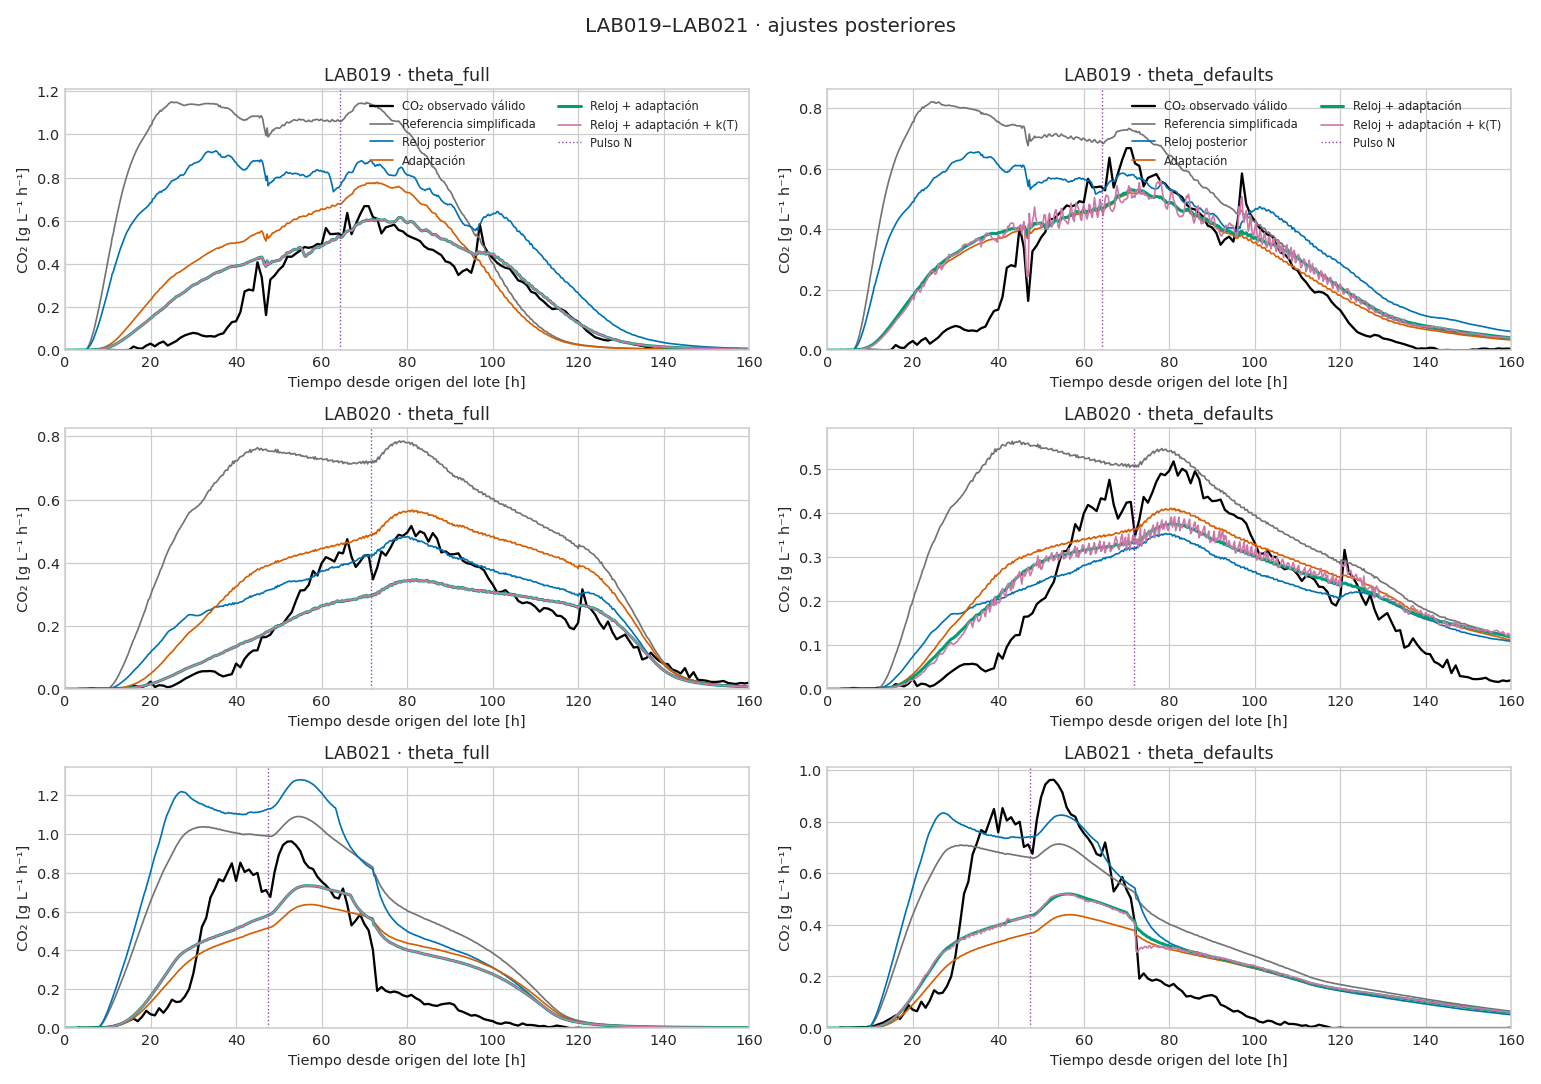

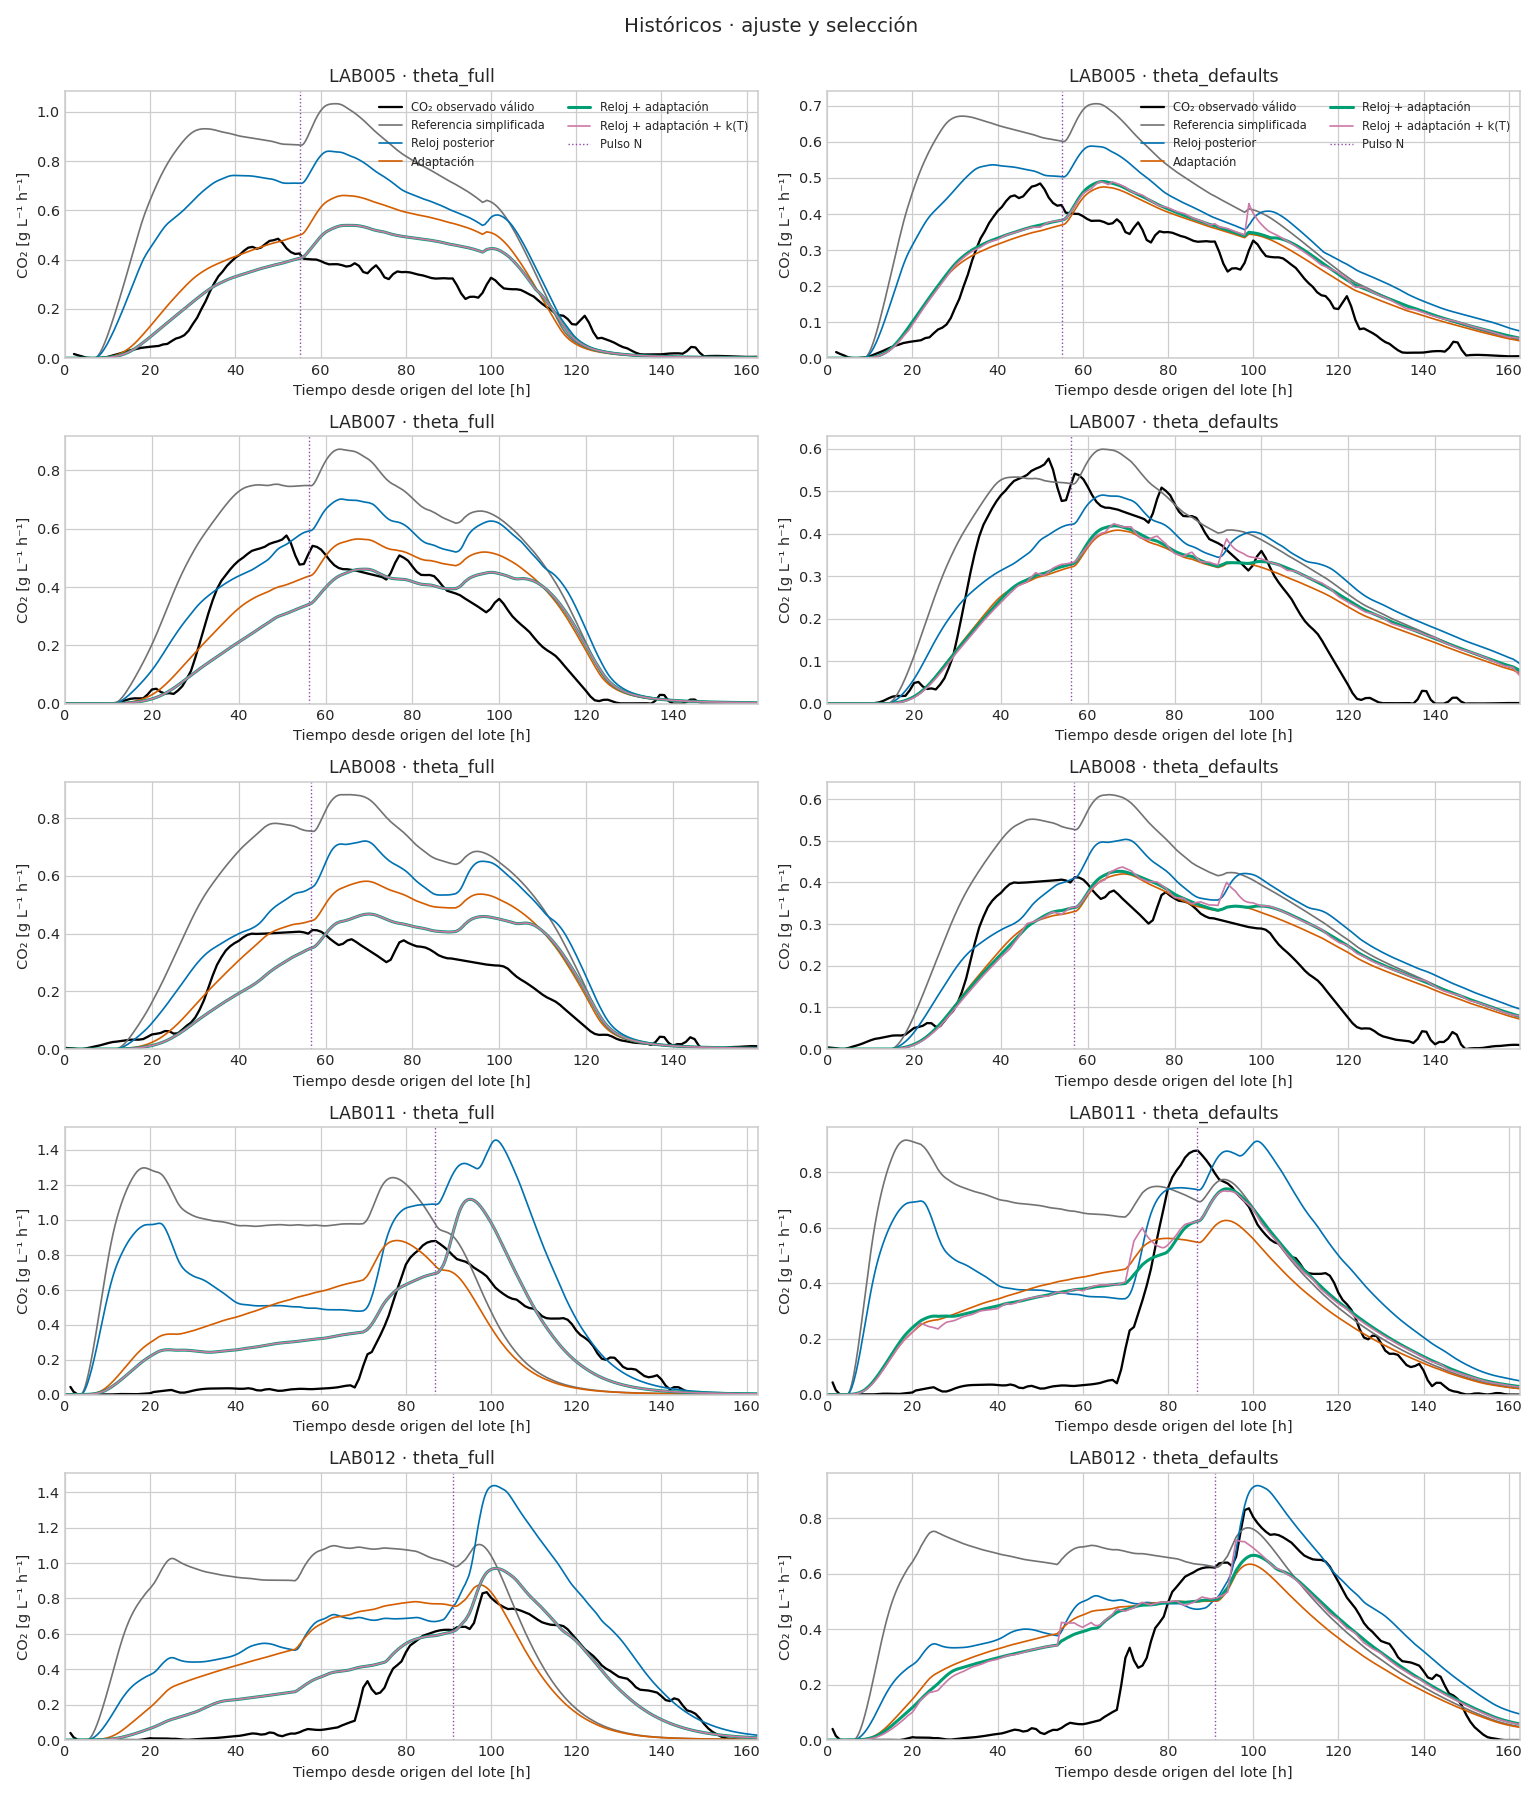

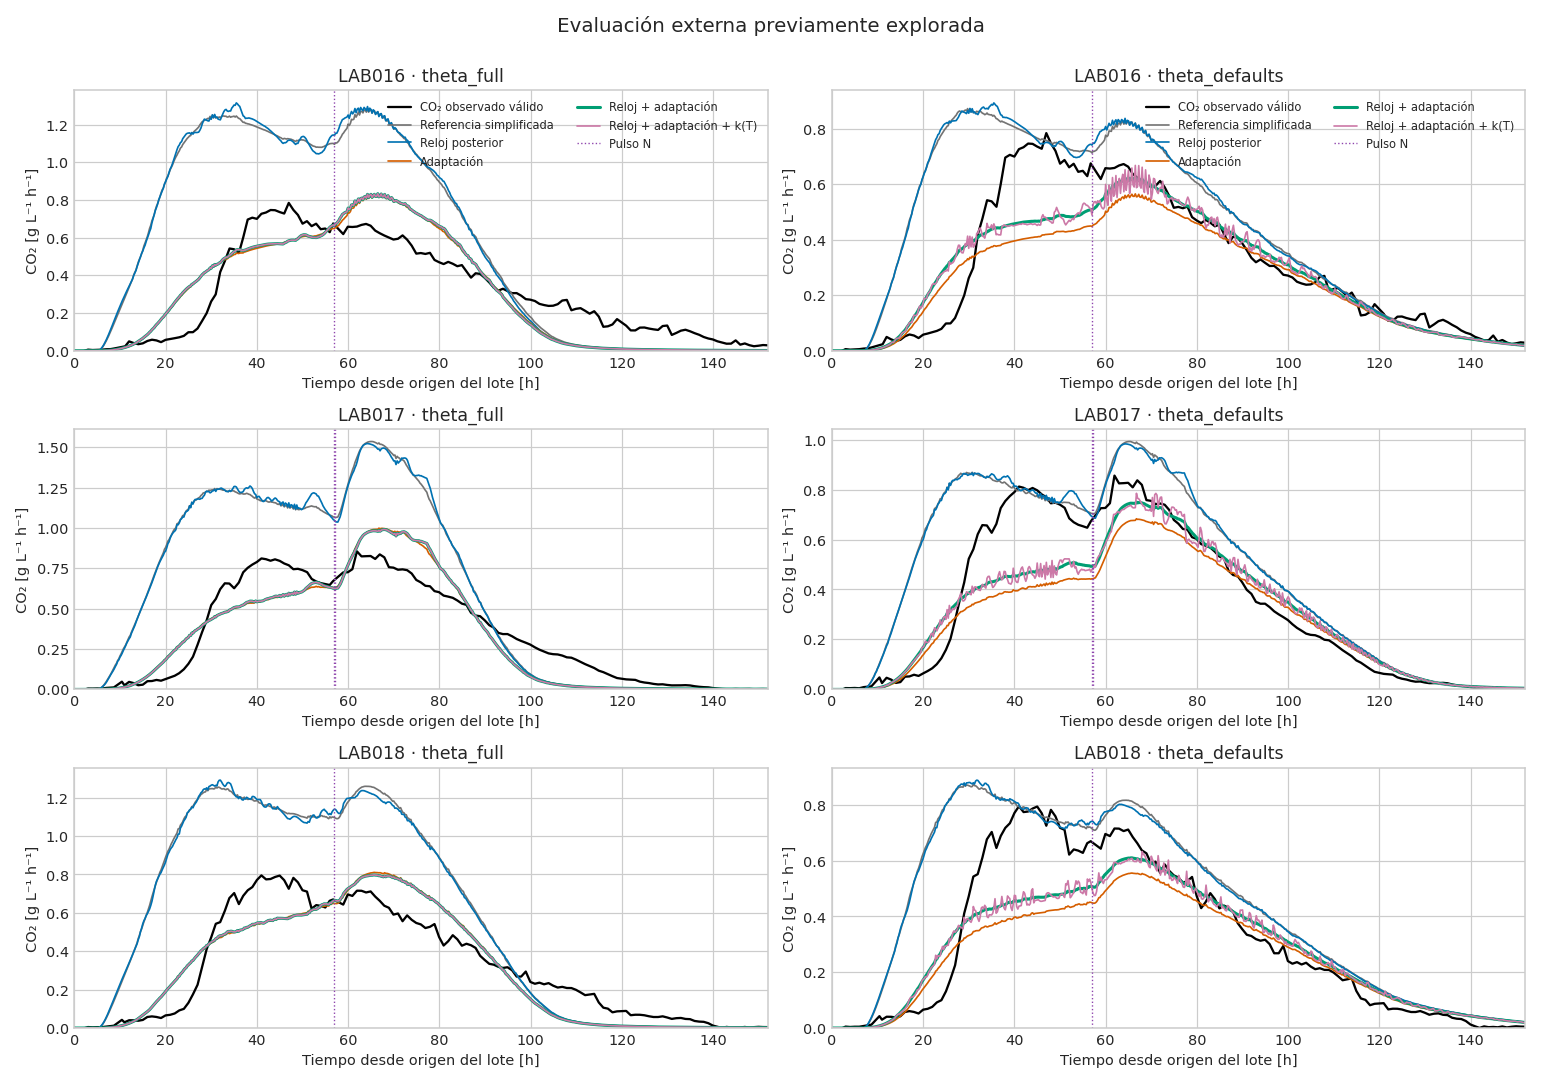

In [16]:
for labs,title in ((RECENT_TRAIN_LABS,'LAB019–LAB021 · ajustes posteriores'),
                   (HISTORICAL_TRAIN_LABS+VALIDATION_LABS,'Históricos · ajuste y selección'),
                   (EXTERNAL_LABS,'Evaluación externa previamente explorada')):
    display_inline_figure(draw_comparison(audit,labs,POST_CURVES,SELECTED_POST,title,all_post=True))

## Reloj, adaptación y transferencia seleccionados

Los factores son adicionales a la temperatura que ya actúa en la cinética. Se compara su historia para ambos theta y se conserva la separación de unidades.

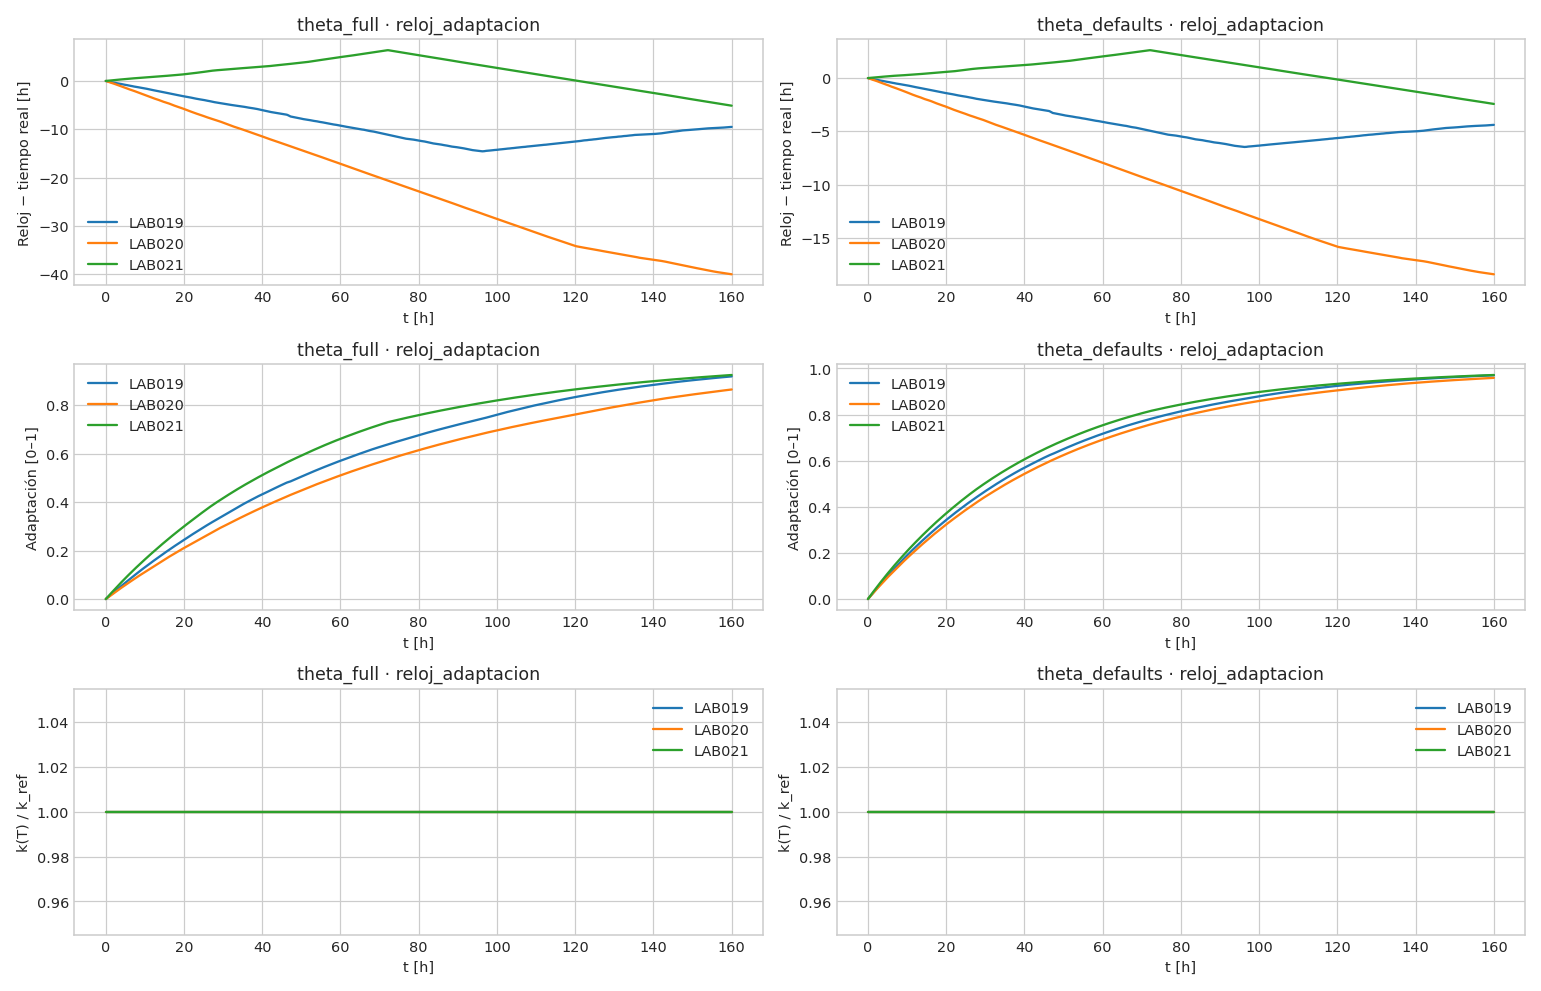

In [17]:
fig,axes=plt.subplots(3,2,figsize=(14,9),squeeze=False)
for j,theta in enumerate(THETA_SETS):
    for lab in RECENT_TRAIN_LABS:
        p=POST_CURVES[(theta,SELECTED_POST[theta],lab)]
        axes[0,j].plot(p.t_h,p.thermal_clock_h-p.t_h,label=lab)
        axes[1,j].plot(p.t_h,p.adaptation,label=lab)
        axes[2,j].plot(p.t_h,p.k_release_h/CO2_PARAMS['kCO2_release_h'],label=lab)
    for i,ylabel in enumerate(('Reloj − tiempo real [h]','Adaptación [0–1]','k(T) / k_ref')):
        axes[i,j].set(title=f'{theta} · {SELECTED_POST[theta]}',xlabel='t [h]',ylabel=ylabel)
        axes[i,j].legend()
fig.tight_layout();display_inline_figure(fig)

## Prueba controlada de forma a temperatura constante

Como en el notebook original, sólo se reemplaza la temperatura que ven el **reloj posterior y k(T)** de LAB020. La química, O₂, gate y solubilidad base siguen calculados con la temperatura real medida. Es una sensibilidad parcial, no una simulación isotérmica de todos los mecanismos.

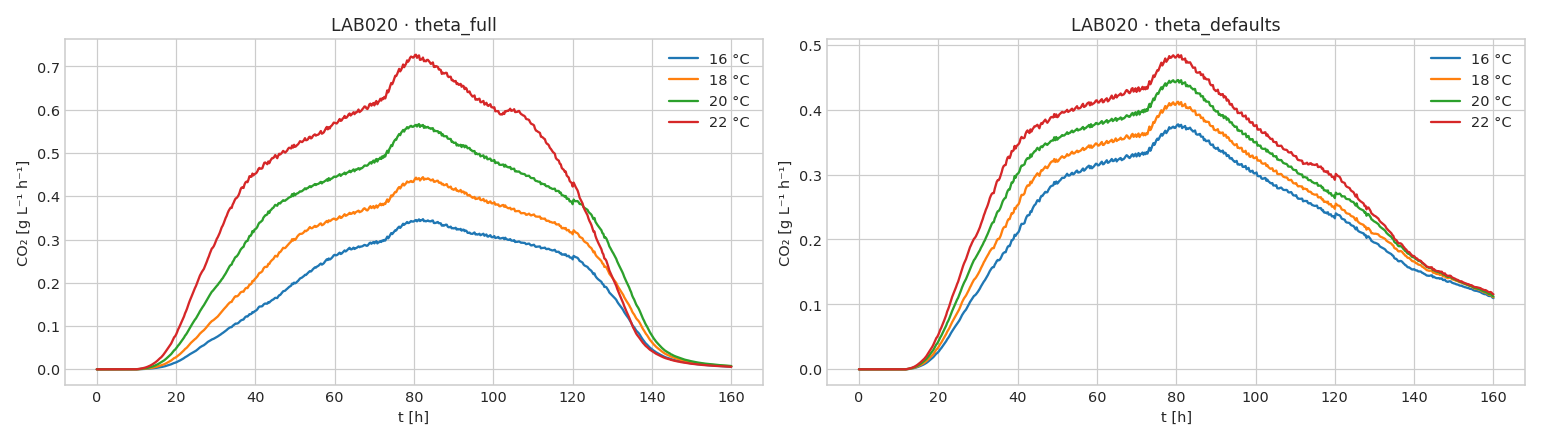

,theta,temperature_C,peak_g_l_h,peak_time_h,AUC_g_l,clock_final_h,driver_exceeded_fraction
0,theta_full,16.0,0.34703,82.25,27.36280,114.35269,0.00000
1,theta_full,18.0,0.44410,82.25,35.92451,135.42044,0.00000
2,theta_full,20.0,0.56676,81.25,46.74376,160.00000,0.00000
3,theta_full,22.0,0.72705,80.50,57.88984,188.61406,0.15289
4,theta_defaults,16.0,0.37724,80.50,33.52814,138.85368,0.00000
5,theta_defaults,18.0,0.41203,80.50,36.78080,149.12489,0.00000
6,theta_defaults,20.0,0.44551,80.50,40.17550,160.00000,0.00000
7,theta_defaults,22.0,0.48444,80.50,43.71133,171.50451,0.06708


In [18]:
CONTROL_TEMPERATURES_C=(16.,18.,20.,22.)
CONTROLLED_ROWS=[]
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,theta in zip(axes,THETA_SETS):
    selected=POST_FITS[(theta,SELECTED_POST[theta])]['params']
    for temperature in CONTROL_TEMPERATURES_C:
        p=audit.predict(theta,'LAB020',selected,temperature_override=temperature)
        CONTROLLED_ROWS.append(dict(theta=theta,temperature_C=temperature,peak_g_l_h=p.predicted.max(),
            peak_time_h=p.loc[p.predicted.idxmax(),'t_h'],AUC_g_l=float(np.trapz(p.predicted,p.t_h)),
            clock_final_h=p.thermal_clock_h.iloc[-1],driver_exceeded_fraction=p.clock_outside_driver.mean()))
        ax.plot(p.t_h,p.predicted,label=f'{temperature:g} °C')
    ax.set(title=f'LAB020 · {theta}',xlabel='t [h]',ylabel='CO₂ [g L⁻¹ h⁻¹]');ax.legend()
fig.tight_layout();display_inline_figure(fig)
display(pd.DataFrame(CONTROLLED_ROWS).round(5))

## Reloj dentro de toda la cinética: nueva búsqueda discreta

Para cada theta se recalculan trayectorias con/sin N para B = 0, 2000, 4000, 8000 y 12000 K. Para cada B se eligen adaptación y transferencia mediante la grilla del protocolo, usando sólo los seis lotes de ajuste. Se selecciona entre candidatos con LAB011–LAB012; los lotes externos no intervienen. Un extremo seleccionado de grilla es una limitación, no un óptimo continuo identificado.

In [19]:
KIN_FITS,KIN_GRID = audit.fit_kinetic()
display(KIN_GRID.sort_values('WSSE').groupby(['theta','model'],as_index=False).first().round(5))
KIN_CURVES,KIN_METRICS,KIN_RANKING,SELECTED_KIN = audit.evaluate_results(KIN_FITS,'kinetic')
display(KIN_RANKING.round(5))
print('Selección cinética independiente por theta:',SELECTED_KIN)
display(KIN_METRICS.groupby(['theta','role','model'],as_index=False).agg(
    median_NRMSE=('NRMSE_peak','median'),median_abs_onset_h=('onset_error_h',abs_median),
    median_abs_AUC=('AUC_relative_error',abs_median)).round(5))

Grilla cinética: theta_full, B=0 K
Grilla cinética: theta_full, B=2000 K
Grilla cinética: theta_full, B=4000 K
Grilla cinética: theta_full, B=8000 K
Grilla cinética: theta_full, B=12000 K
Grilla cinética: theta_defaults, B=0 K
Grilla cinética: theta_defaults, B=2000 K
Grilla cinética: theta_defaults, B=4000 K
Grilla cinética: theta_defaults, B=8000 K
Grilla cinética: theta_defaults, B=12000 K
Selección cinética independiente por theta: {'theta_full': 'cin_global_adapt__Bkin_12000', 'theta_defaults': 'cin_global_full__Bkin_8000'}


,theta,model,spec,B_kin_extra_K,WSSE,tau_adapt_ref_h,B_release_K
0,theta_defaults,cin_global__Bkin_0,cin_global,0.0,1.19049,NaN,NaN
1,theta_defaults,cin_global__Bkin_12000,cin_global,12000.0,0.69899,NaN,NaN
2,theta_defaults,cin_global__Bkin_2000,cin_global,2000.0,1.02716,NaN,NaN
3,theta_defaults,cin_global__Bkin_4000,cin_global,4000.0,0.90111,NaN,NaN
4,theta_defaults,cin_global__Bkin_8000,cin_global,8000.0,0.74498,NaN,NaN
5,theta_defaults,cin_global_adapt__Bkin_0,cin_global_adapt,0.0,0.30326,50.0,NaN
6,theta_defaults,cin_global_adapt__Bkin_12000,cin_global_adapt,12000.0,0.47060,24.0,NaN
7,theta_defaults,cin_global_adapt__Bkin_2000,cin_global_adapt,2000.0,0.30573,50.0,NaN
8,theta_defaults,cin_global_adapt__Bkin_4000,cin_global_adapt,4000.0,0.32870,36.0,NaN
9,theta_defaults,cin_global_adapt__Bkin_8000,cin_global_adapt,8000.0,0.37589,36.0,NaN


,theta,model,median_NRMSE,median_abs_onset_h,median_abs_AUC,median_clock_outside_driver
0,theta_defaults,cin_global_full__Bkin_8000,0.17026,48.45833,0.38194,0.0
1,theta_defaults,cin_global_adapt__Bkin_8000,0.17087,48.45833,0.38058,0.0
2,theta_defaults,cin_global_full__Bkin_12000,0.18770,48.95833,0.51651,0.0
3,theta_defaults,cin_global_adapt__Bkin_12000,0.18781,48.95833,0.51579,0.0
4,theta_defaults,cin_global_full__Bkin_2000,0.21401,51.00000,0.30188,0.0
5,theta_defaults,cin_global_adapt__Bkin_2000,0.21456,51.50000,0.29969,0.0
6,theta_defaults,cin_global_full__Bkin_4000,0.22061,51.50000,0.44973,0.0
7,theta_defaults,cin_global_adapt__Bkin_4000,0.22077,52.00000,0.44829,0.0
8,theta_defaults,cin_global_full__Bkin_0,0.24984,51.50000,0.34052,0.0
9,theta_defaults,cin_global_adapt__Bkin_0,0.25004,53.00000,0.33827,0.0


,theta,role,model,median_NRMSE,median_abs_onset_h,median_abs_AUC
0,theta_defaults,LAB010_sensitivity,cin_global__Bkin_0,1.72227,76.0,4.42481
1,theta_defaults,LAB010_sensitivity,cin_global__Bkin_12000,0.92308,71.0,2.57153
2,theta_defaults,LAB010_sensitivity,cin_global__Bkin_2000,1.57609,75.0,4.16143
3,theta_defaults,LAB010_sensitivity,cin_global__Bkin_4000,1.43270,74.0,3.86603
4,theta_defaults,LAB010_sensitivity,cin_global__Bkin_8000,1.16350,73.0,3.23225
...,...,...,...,...,...,...
145,theta_full,train_recent,cin_global_full__Bkin_0,0.29516,12.0,0.53251
146,theta_full,train_recent,cin_global_full__Bkin_12000,0.17584,7.0,0.26727
147,theta_full,train_recent,cin_global_full__Bkin_2000,0.23179,10.0,0.48215
148,theta_full,train_recent,cin_global_full__Bkin_4000,0.20388,9.0,0.36942


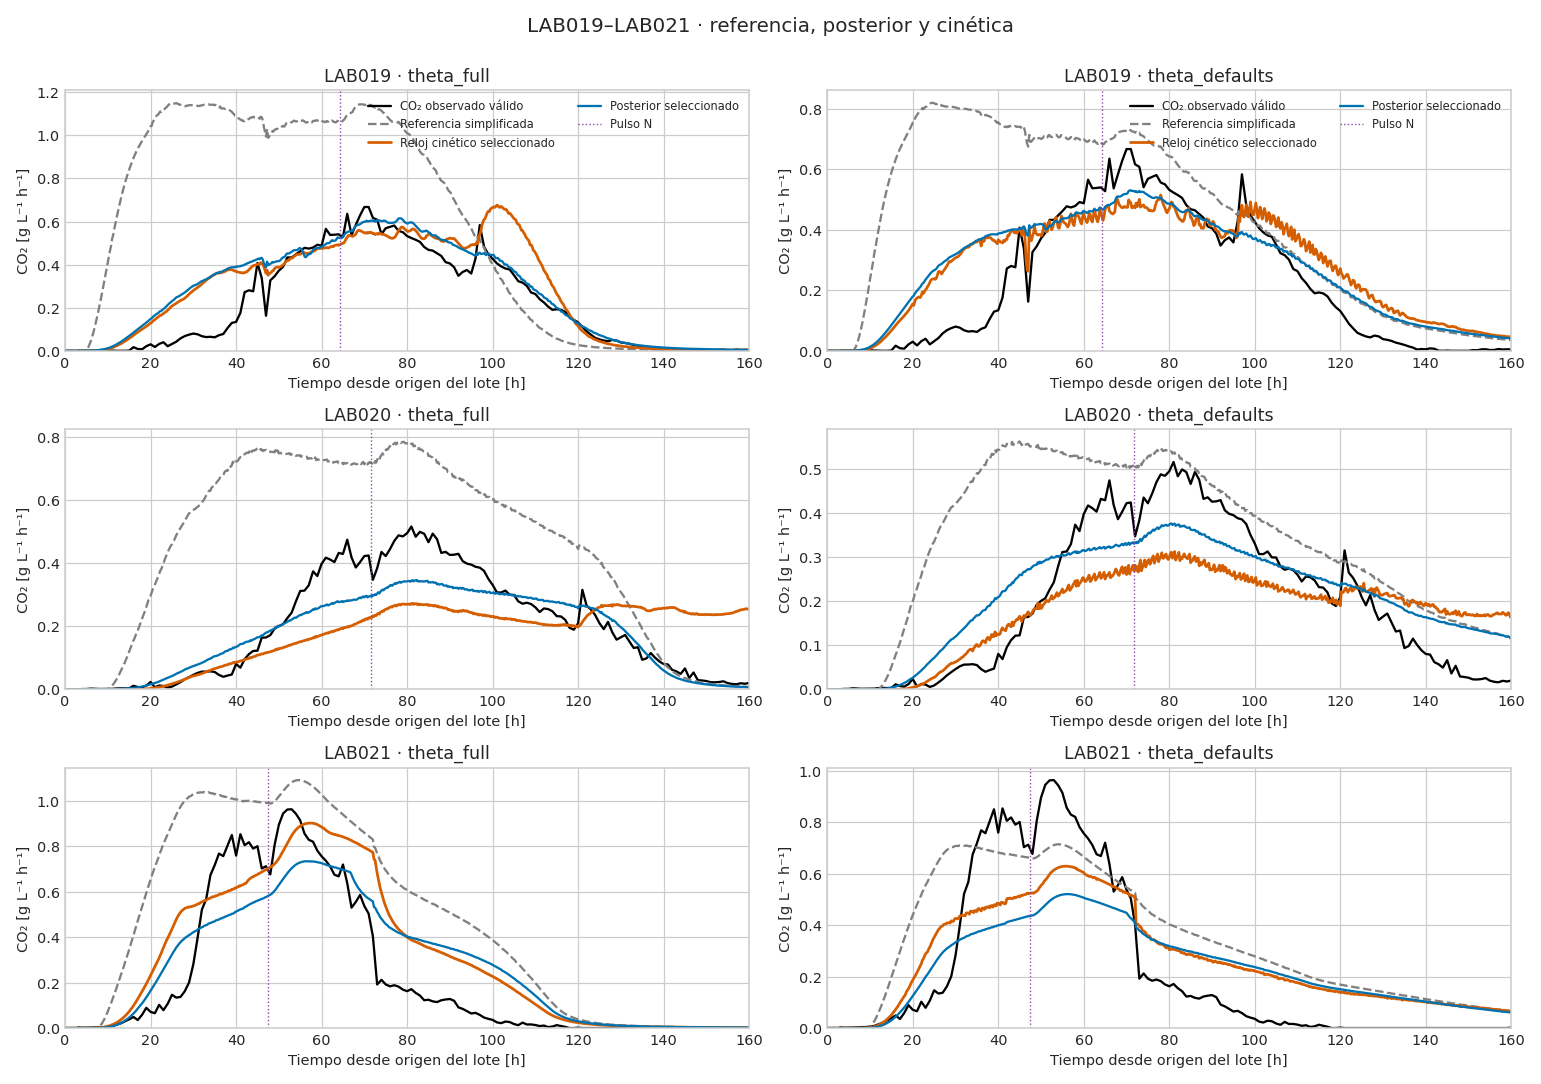

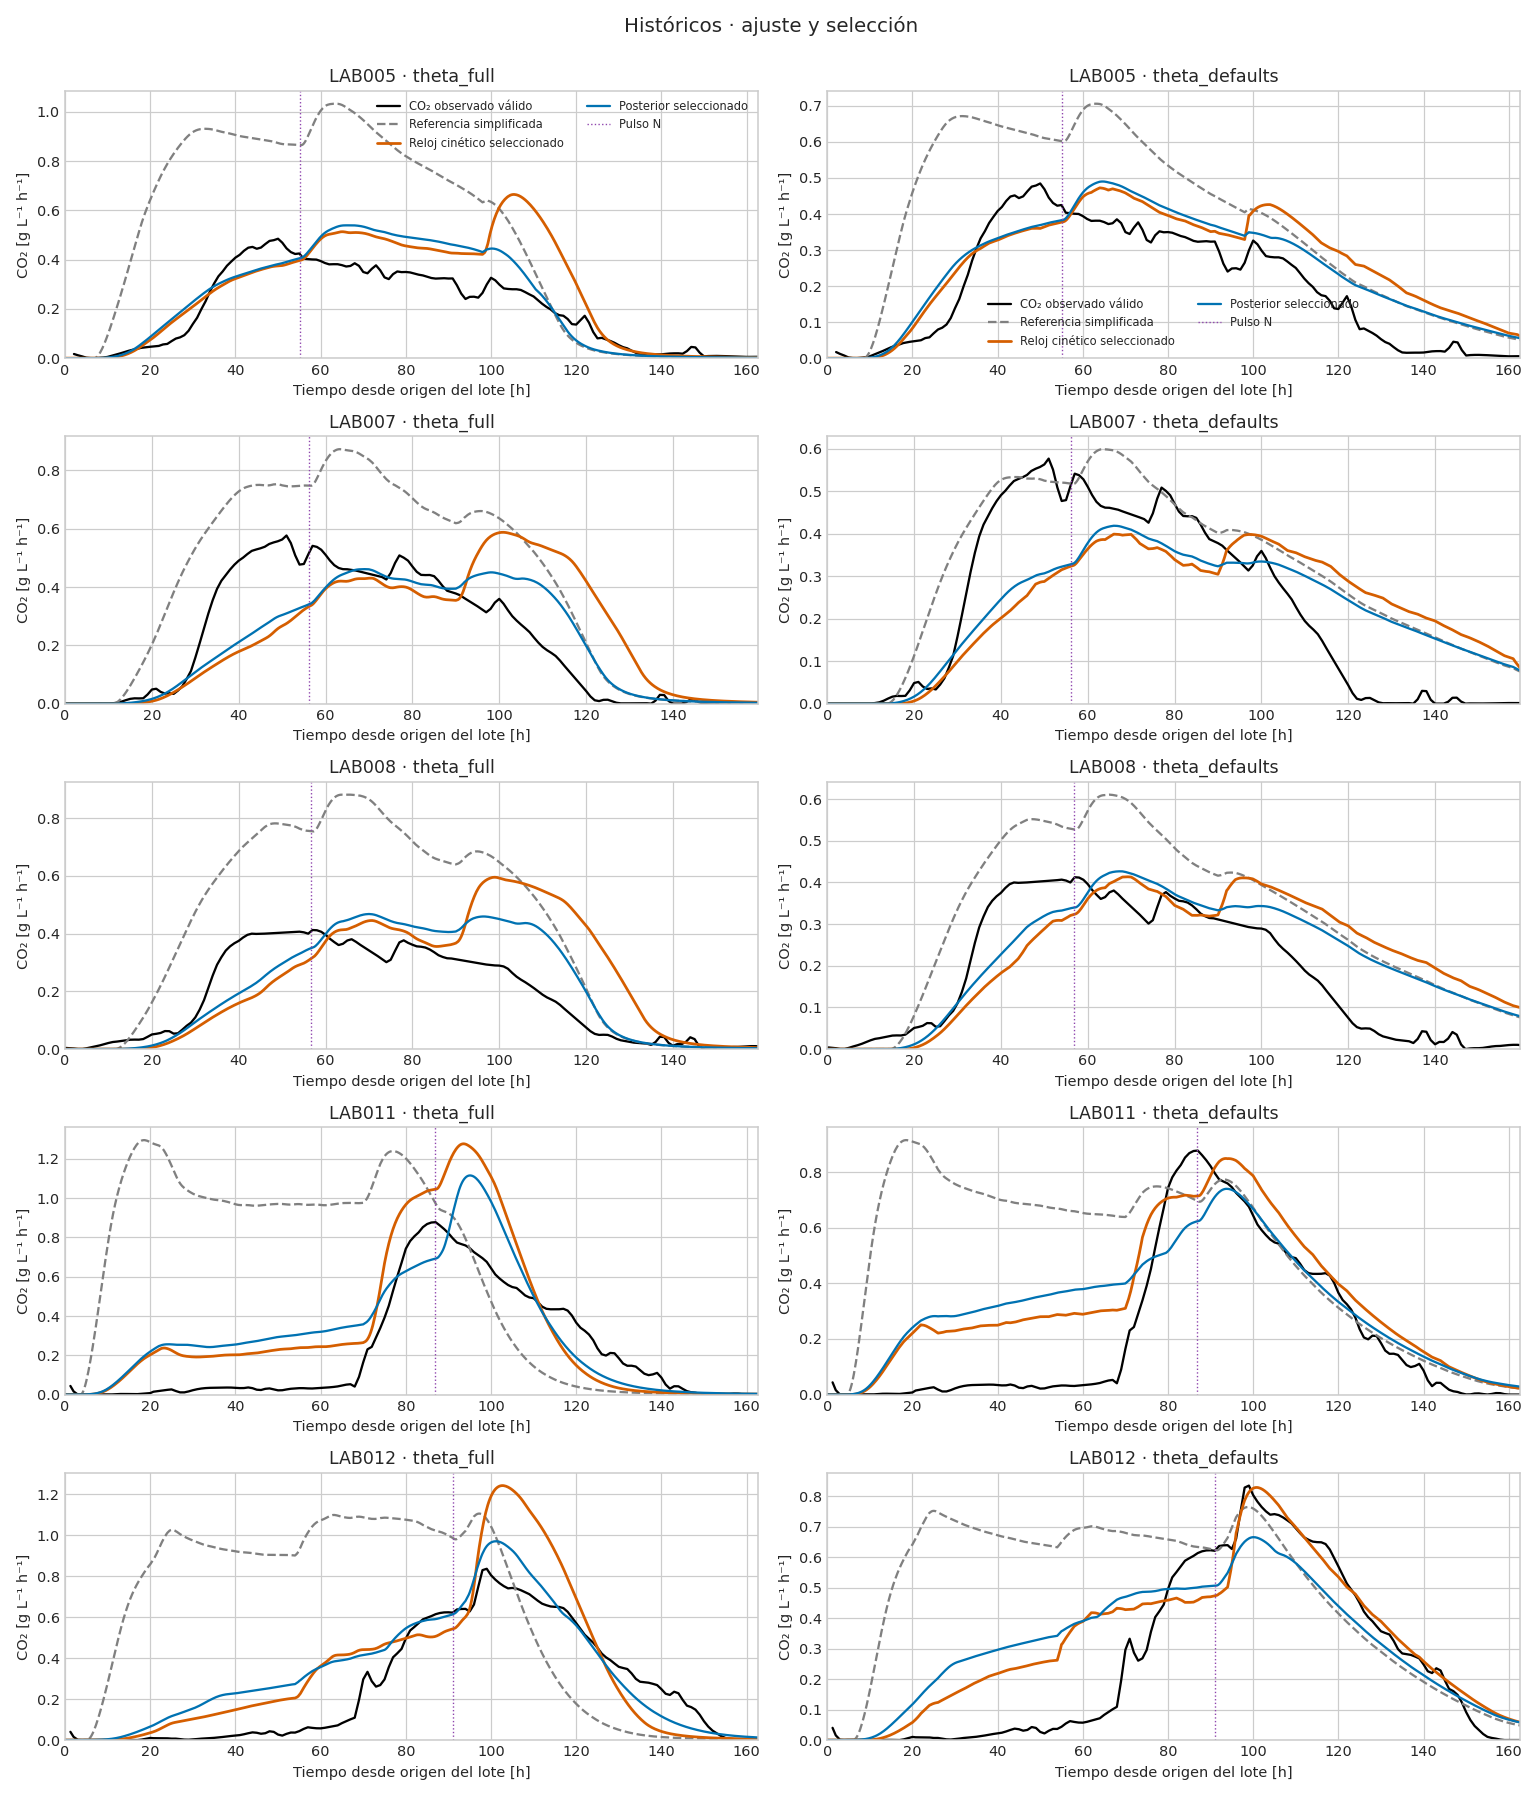

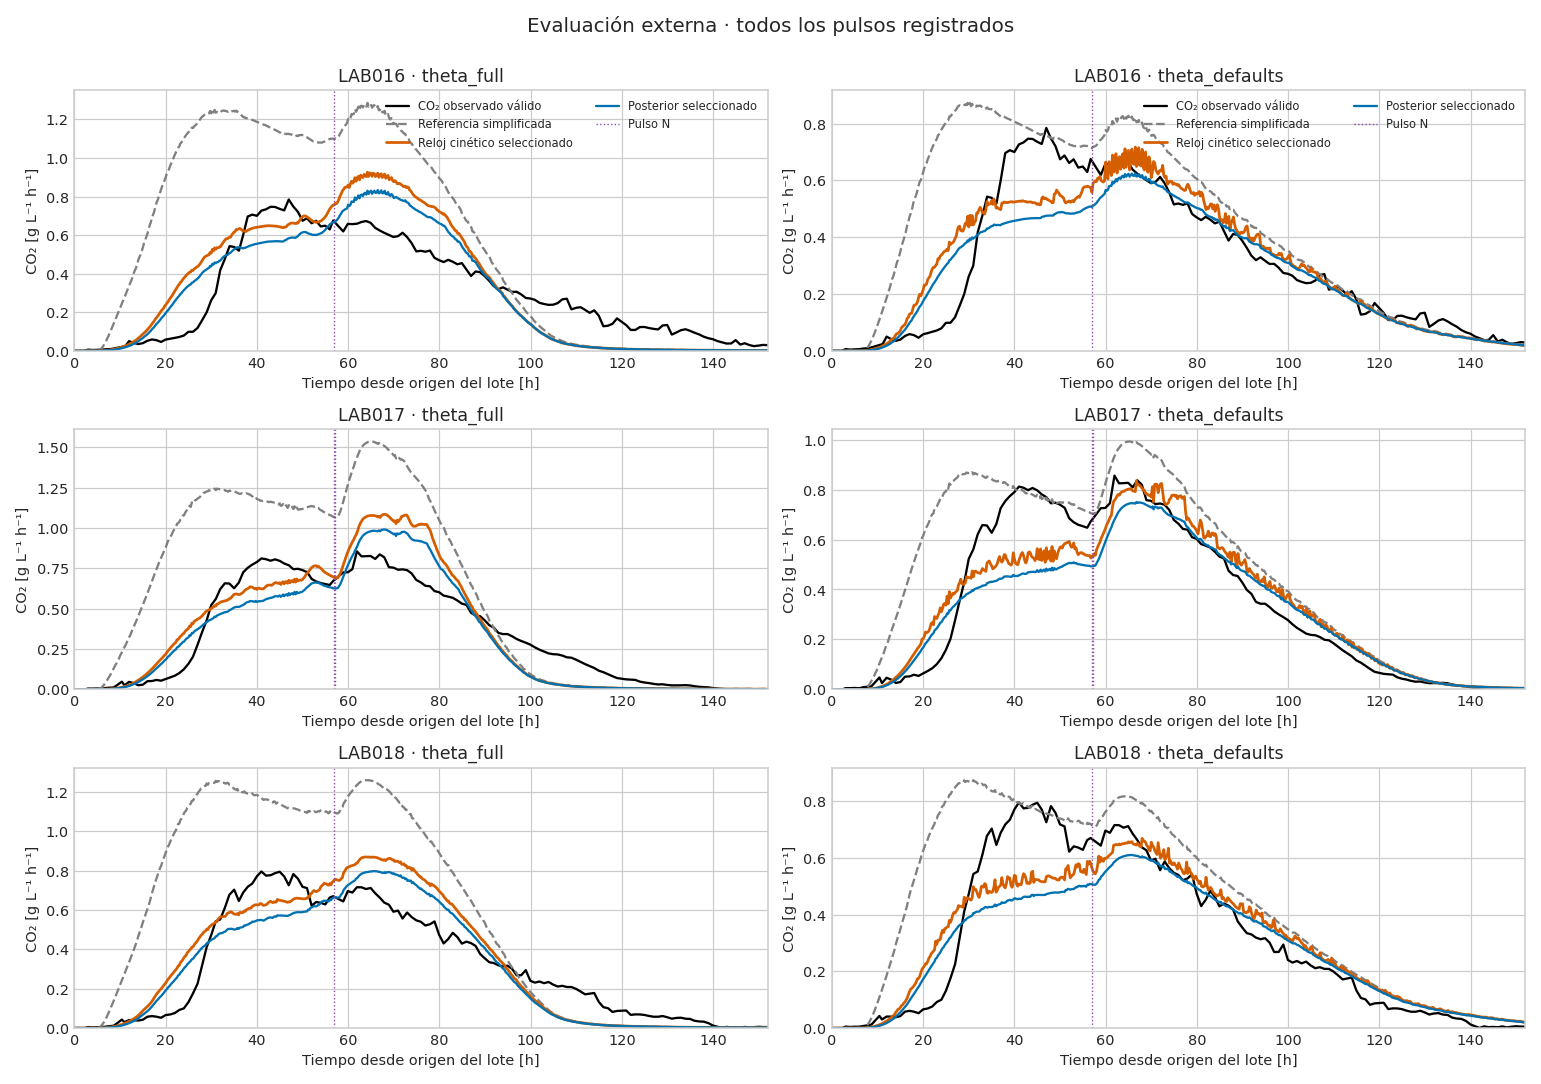

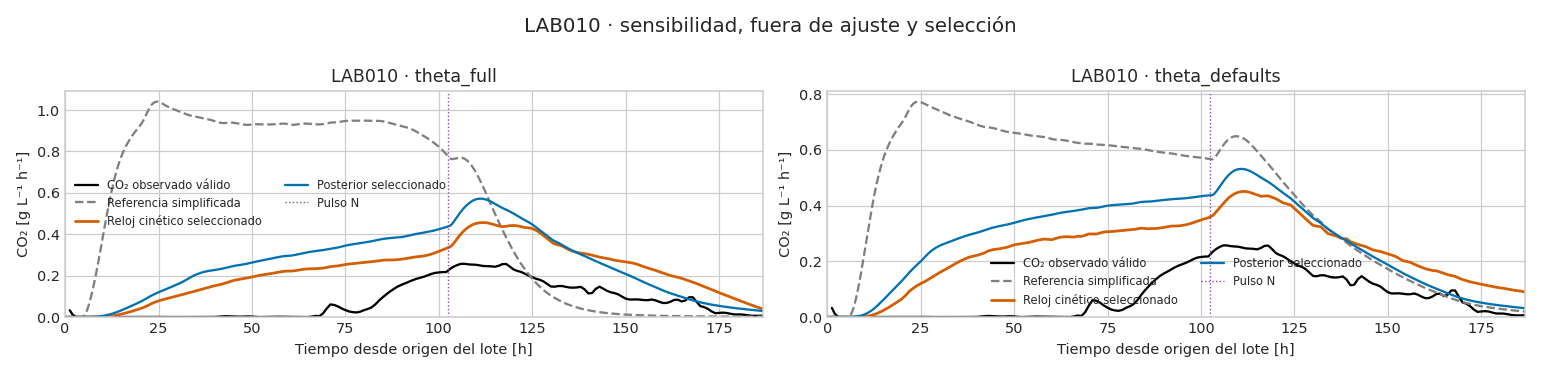

In [20]:
for labs,title in ((RECENT_TRAIN_LABS,'LAB019–LAB021 · referencia, posterior y cinética'),
                   (HISTORICAL_TRAIN_LABS+VALIDATION_LABS,'Históricos · ajuste y selección'),
                   (EXTERNAL_LABS,'Evaluación externa · todos los pulsos registrados'),
                   (SENSITIVITY_LABS,'LAB010 · sensibilidad, fuera de ajuste y selección')):
    display_inline_figure(draw_comparison(audit,labs,KIN_CURVES,SELECTED_KIN,title,
        other_curves=POST_CURVES,other_selections=SELECTED_POST))

## Sensibilidad al reloj cinético y estados internos de LAB021

La sensibilidad del flujo cruza los cinco valores B con los parámetros adaptación/k(T) elegidos en ajuste para `cin_global_full`. Los estados comparan la referencia B=0 con el B del candidato cinético seleccionado para cada theta. Se presentan biomasa, N, azúcares, etanol y glicerol; el reloj altera toda la química, no sólo el flujo de CO₂.

Las mediciones de biomasa se leen de los tres `Oculyze_report_LAB019/020/021.csv` y se vinculan por lote y número de muestra con los tiempos de `MedicionesOffline`. Se usa el tiempo de muestreo, no el de análisis del instrumento; m1 conserva la convención de t=0 del notebook. La biomasa viable observada es $X_{\mathrm{obs}}=0.03\,C_{\mathrm{celular}}\,v/100$ en g/L (30 pg/célula, concentración en millones de células/mL y viabilidad en %). Se conserva la concentración cruda sin restar CERO, como en la convención primaria de inicialización; las ICs existentes permanecen fijas. La tabla distingue biomasa total, viable y muerta.

Además de añadir los puntos de X al diagnóstico de estados de LAB021, se compara la biomasa viable observada de **LAB019–LAB021** con los cinco relojes cinéticos para ambos theta. Las métricas de química incorporan X viable y excluyen m1 por ser la muestra de inicialización. Estas observaciones se usan para el diagnóstico, no para ajustar los parámetros térmicos.


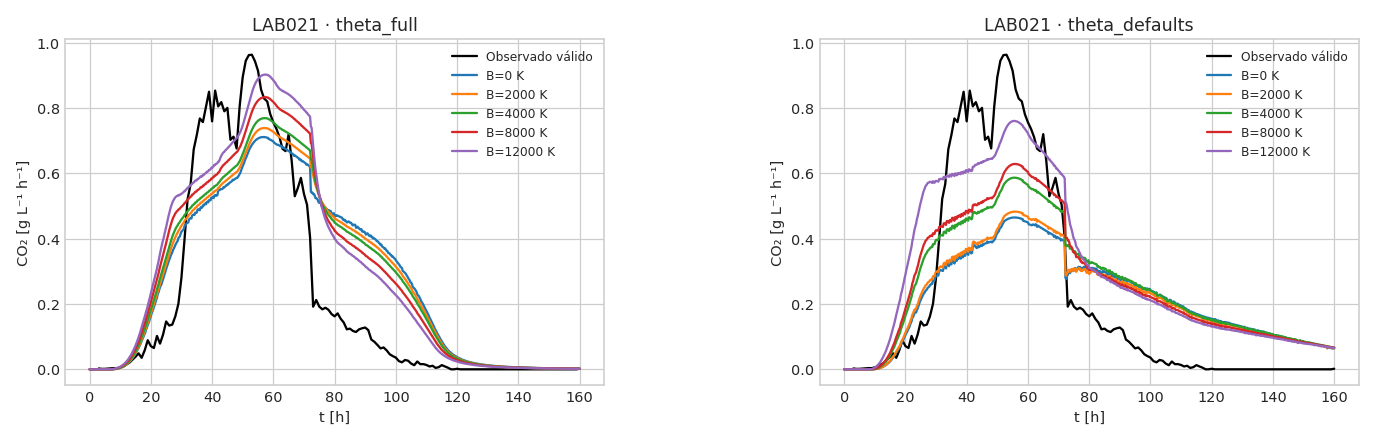

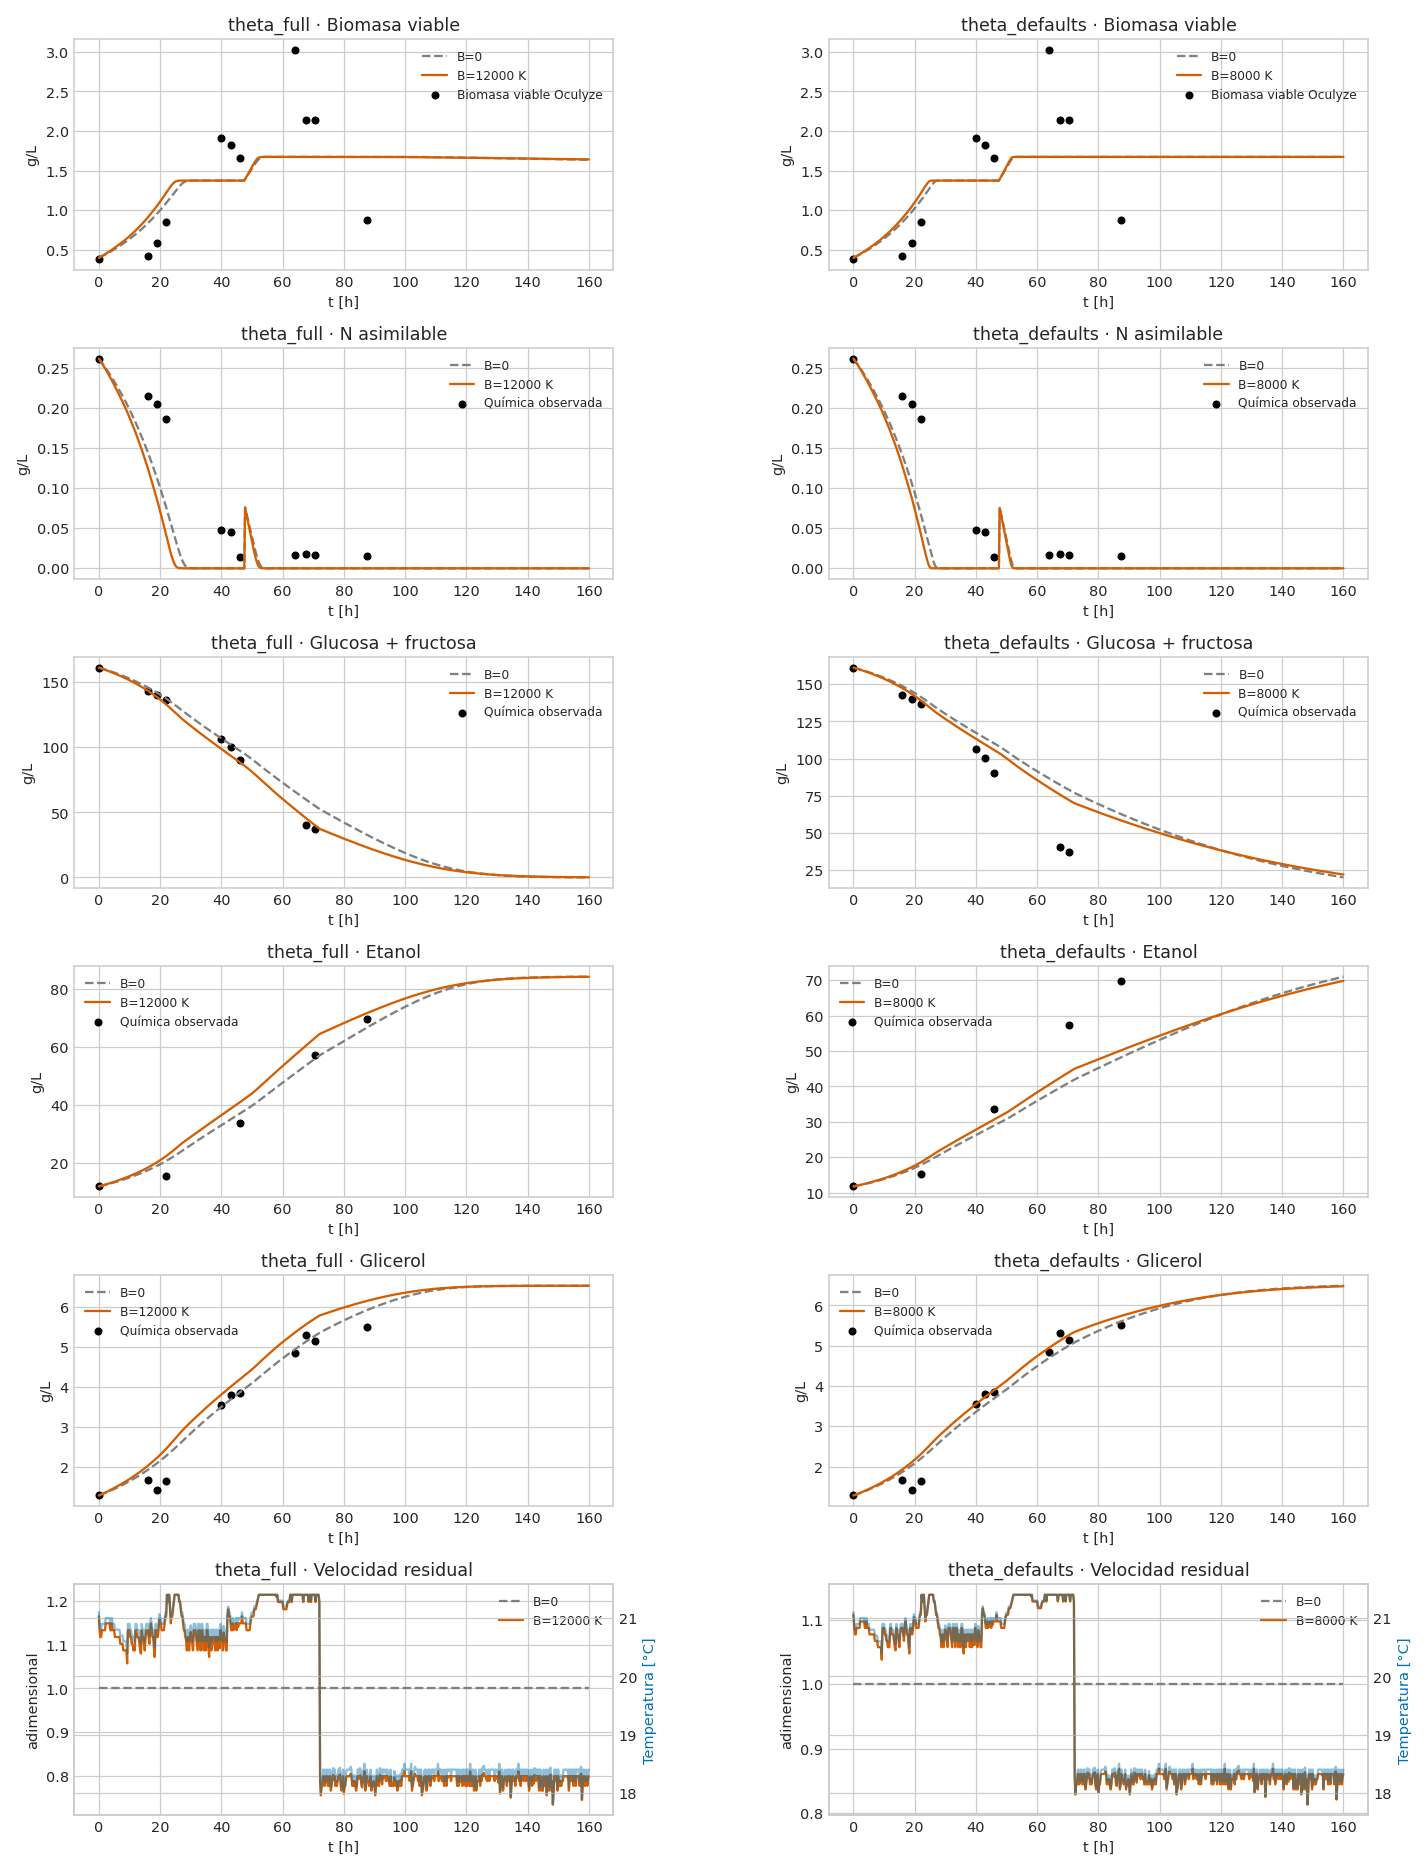

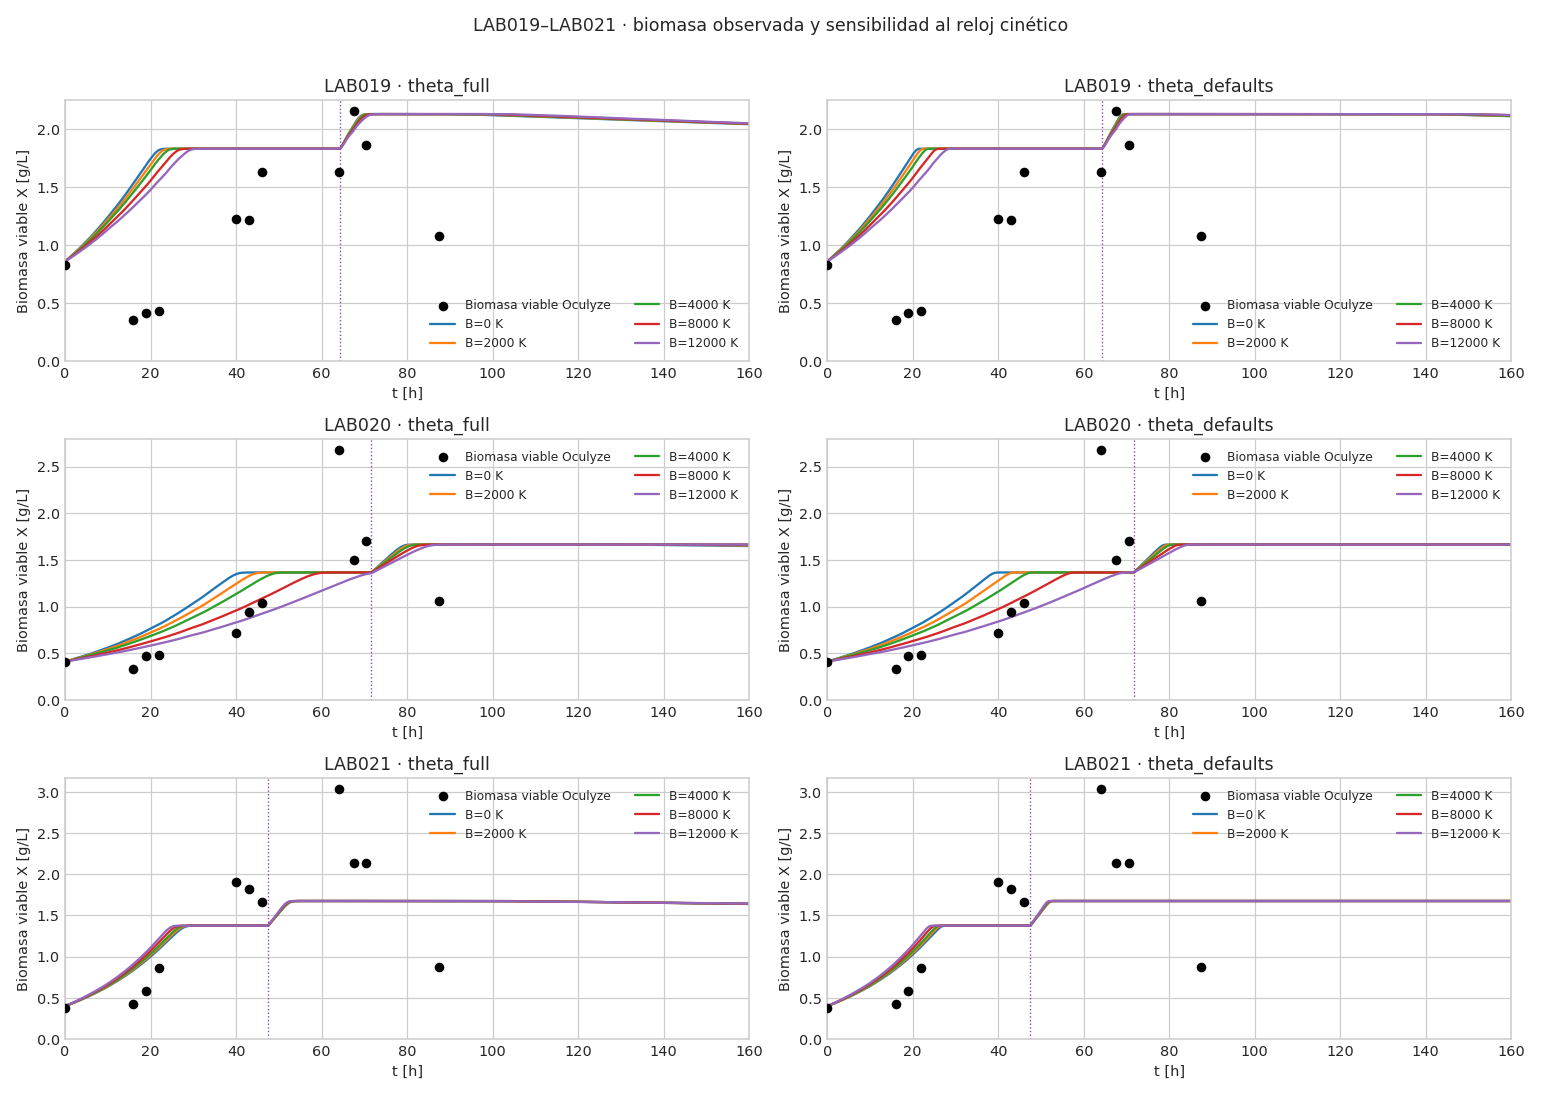

,theta,lab,model,state,n,RMSE_g_l
0,theta_full,LAB019,referencia,X,10,0.83478
1,theta_full,LAB019,referencia,GF,9,36.51982
2,theta_full,LAB019,referencia,E,4,23.72115
3,theta_full,LAB019,referencia,N,10,0.12625
4,theta_full,LAB019,referencia,Gly,10,1.35249
5,theta_full,LAB019,cinético seleccionado,X,10,0.72721
6,theta_full,LAB019,cinético seleccionado,GF,9,18.91850
7,theta_full,LAB019,cinético seleccionado,E,4,13.61104
8,theta_full,LAB019,cinético seleccionado,N,10,0.09996
9,theta_full,LAB019,cinético seleccionado,Gly,10,0.74675


In [21]:
lab='LAB021'
fig,axes=plt.subplots(1,2,figsize=(14,4))
for ax,theta in zip(axes,THETA_SETS):
    obs=OBSERVATIONS[lab];ax.plot(obs.t_h,obs.co2_rate_g_l_h,color='black',label='Observado válido')
    for B in KINETIC_CLOCK_CONFIG['B_grid_K']:
        candidate=f'cin_global_full__Bkin_{B:g}'
        p=KIN_CURVES[(theta,candidate,lab)]
        ax.plot(p.t_h,p.predicted,label=f'B={B:g} K')
    ax.set(title=f'{lab} · {theta}',xlabel='t [h]',ylabel='CO₂ [g L⁻¹ h⁻¹]');ax.legend(fontsize=8)
fig.tight_layout();fig.subplots_adjust(left=.08,right=.92,wspace=.4);display_inline_figure(fig)

fig,axes=plt.subplots(6,2,figsize=(14,17),squeeze=False)
CHEMISTRY_METRIC_ROWS=[]
for j,theta in enumerate(THETA_SETS):
    selected_B=KIN_FITS[(theta,SELECTED_KIN[theta])]['B']
    reference=audit.profile(theta,lab,0.)
    selected=audit.profile(theta,lab,selected_B)
    for i,(state,label) in enumerate((('X','Biomasa viable'),('N','N asimilable'),('GF','Glucosa + fructosa'),('E','Etanol'),('Gly','Glicerol'),('speed','Velocidad residual'))):
        ax=axes[i,j]
        if state=='speed':
            baseline=np.ones(len(reference['t'])); values=selected['speed'];unit='adimensional'
        else:
            baseline=(reference['core'].G+reference['core'].F) if state=='GF' else reference['core'][state]
            values=(selected['core'].G+selected['core'].F) if state=='GF' else selected['core'][state]
            unit='g/L'
        ax.plot(reference['t'],baseline,color='0.5',ls='--',label='B=0')
        ax.plot(selected['t'],values,color='#D55E00',label=f'B={selected_B:g} K')
        column={'X':'X_viable_g_l','GF':'GF_g_l','E':'E_g_l','N':'N_kg_m3','Gly':'Gly_g_l'}.get(state)
        if column:
            measured=chem[chem.lab.eq(lab) & chem[column].notna() & chem.t_h.le(selected['t'][-1])]
            ax.scatter(measured.t_h,measured[column],color='black',s=18,label='Biomasa viable Oculyze' if state=='X' else 'Química observada')
        if state=='speed':
            temp_ax=ax.twinx();temp_ax.plot(selected['t'],selected['temperature'],color='#0072B2',alpha=.45)
            temp_ax.set_ylabel('Temperatura [°C]',color='#0072B2')
        ax.set(title=f'{theta} · {label}',xlabel='t [h]',ylabel=unit);ax.legend(fontsize=8)
fig.tight_layout();fig.subplots_adjust(left=.08,right=.92,wspace=.4);display_inline_figure(fig)


# Biomasa viable: los tres lotes, ambos theta y los cinco relojes cinéticos.
fig,axes=plt.subplots(len(RECENT_TRAIN_LABS),2,figsize=(14,10),squeeze=False)
for i,biomass_lab in enumerate(RECENT_TRAIN_LABS):
    measured=BIOMASS_OBSERVATIONS[BIOMASS_OBSERVATIONS.lab.eq(biomass_lab)]
    for j,theta in enumerate(THETA_SETS):
        ax=axes[i,j]
        ax.scatter(measured.t_h,measured.X_viable_g_l,color='black',s=28,zorder=5,
                   label='Biomasa viable Oculyze')
        for B in KINETIC_CLOCK_CONFIG['B_grid_K']:
            profile=audit.profile(theta,biomass_lab,B)
            ax.plot(profile['t'],profile['core'].X,label=f'B={B:g} K')
        for event,_ in ALL_BATCHES[biomass_lab].pulses.get('N',()):
            ax.axvline(event,color='#8E44AD',ls=':',lw=.9)
        ax.set(title=f'{biomass_lab} · {theta}',xlabel='t [h]',ylabel='Biomasa viable X [g/L]',
               xlim=(0,audit.grids[biomass_lab][-1]),ylim=(0,None))
        ax.legend(fontsize=8,ncol=2)
fig.suptitle('LAB019–LAB021 · biomasa observada y sensibilidad al reloj cinético')
fig.tight_layout(rect=(0,0,1,.97));display_inline_figure(fig)

for theta in THETA_SETS:
    B=KIN_FITS[(theta,SELECTED_KIN[theta])]['B']
    for lab in RECENT_TRAIN_LABS:
        for name,B_value in (('referencia',0.),('cinético seleccionado',B)):
            profile=audit.profile(theta,lab,B_value)
            for state,column in (('X','X_viable_g_l'),('GF','GF_g_l'),('E','E_g_l'),('N','N_kg_m3'),('Gly','Gly_g_l')):
                measured=chem[chem.lab.eq(lab) & ~chem.is_initial & chem[column].notna() & chem.t_h.between(0,profile['t'][-1])]
                if state=='GF':measured=measured[~measured.soft_flag_GF]
                if measured.empty:continue
                values=profile['core'].G+profile['core'].F if state=='GF' else profile['core'][state]
                predicted=np.interp(measured.t_h,profile['t'],values)
                error=predicted-measured[column].to_numpy()
                CHEMISTRY_METRIC_ROWS.append(dict(theta=theta,lab=lab,model=name,state=state,n=len(measured),
                    RMSE_g_l=float(np.sqrt(np.mean(error**2)))))
display(pd.DataFrame(CHEMISTRY_METRIC_ROWS).round(5))

## Ventanas alrededor de cambios de setpoint

Se conservan las ventanas 3–1 h antes y 3–5 h después del cambio, ahora comparando ambos theta, referencia y las dos hipótesis seleccionadas. Predicción y observación se evalúan sobre **los mismos tiempos válidos**. Se reportan ΔT medida, cambio absoluto y razón de CO₂, tamaño de soporte y cercanía de un pulso N. Incluyen progreso fermentativo y memoria del depósito; no son una estimación causal aislada de la temperatura.

,theta,lab,event_h,SP_new_C,delta_T_measured_C,near_N_pulse,model,n_before,n_after,observed_before,observed_after,predicted_before,predicted_after,delta_observed,delta_predicted,ratio_observed,ratio_predicted
0,theta_full,LAB019,96.0,21.0,2.8,False,referencia,3,3,0.36581,0.42713,0.60168,0.40337,0.06131,-0.19830,1.16761,0.67041
1,theta_full,LAB019,96.0,21.0,2.8,False,posterior seleccionado,3,3,0.36581,0.42713,0.46158,0.44495,0.06131,-0.01662,1.16761,0.96399
2,theta_full,LAB019,96.0,21.0,2.8,False,cinético seleccionado,3,3,0.36581,0.42713,0.47947,0.66524,0.06131,0.18577,1.16761,1.38744
3,theta_defaults,LAB019,96.0,21.0,2.8,False,referencia,3,3,0.36581,0.42713,0.47340,0.42652,0.06131,-0.04688,1.16761,0.90098
4,theta_defaults,LAB019,96.0,21.0,2.8,False,posterior seleccionado,3,3,0.36581,0.42713,0.39349,0.37113,0.06131,-0.02236,1.16761,0.94317
5,theta_defaults,LAB019,96.0,21.0,2.8,False,cinético seleccionado,3,3,0.36581,0.42713,0.39730,0.47060,0.06131,0.07330,1.16761,1.18450
6,theta_full,LAB020,120.0,18.0,2.0,False,referencia,3,3,0.19533,0.23549,0.46761,0.41960,0.04016,-0.04801,1.20560,0.89733
7,theta_full,LAB020,120.0,18.0,2.0,False,posterior seleccionado,3,3,0.19533,0.23549,0.26708,0.25327,0.04016,-0.01382,1.20560,0.94826
8,theta_full,LAB020,120.0,18.0,2.0,False,cinético seleccionado,3,3,0.19533,0.23549,0.20201,0.25188,0.04016,0.04987,1.20560,1.24687
9,theta_defaults,LAB020,120.0,18.0,2.0,False,referencia,3,3,0.19533,0.23549,0.29606,0.27738,0.04016,-0.01868,1.20560,0.93690


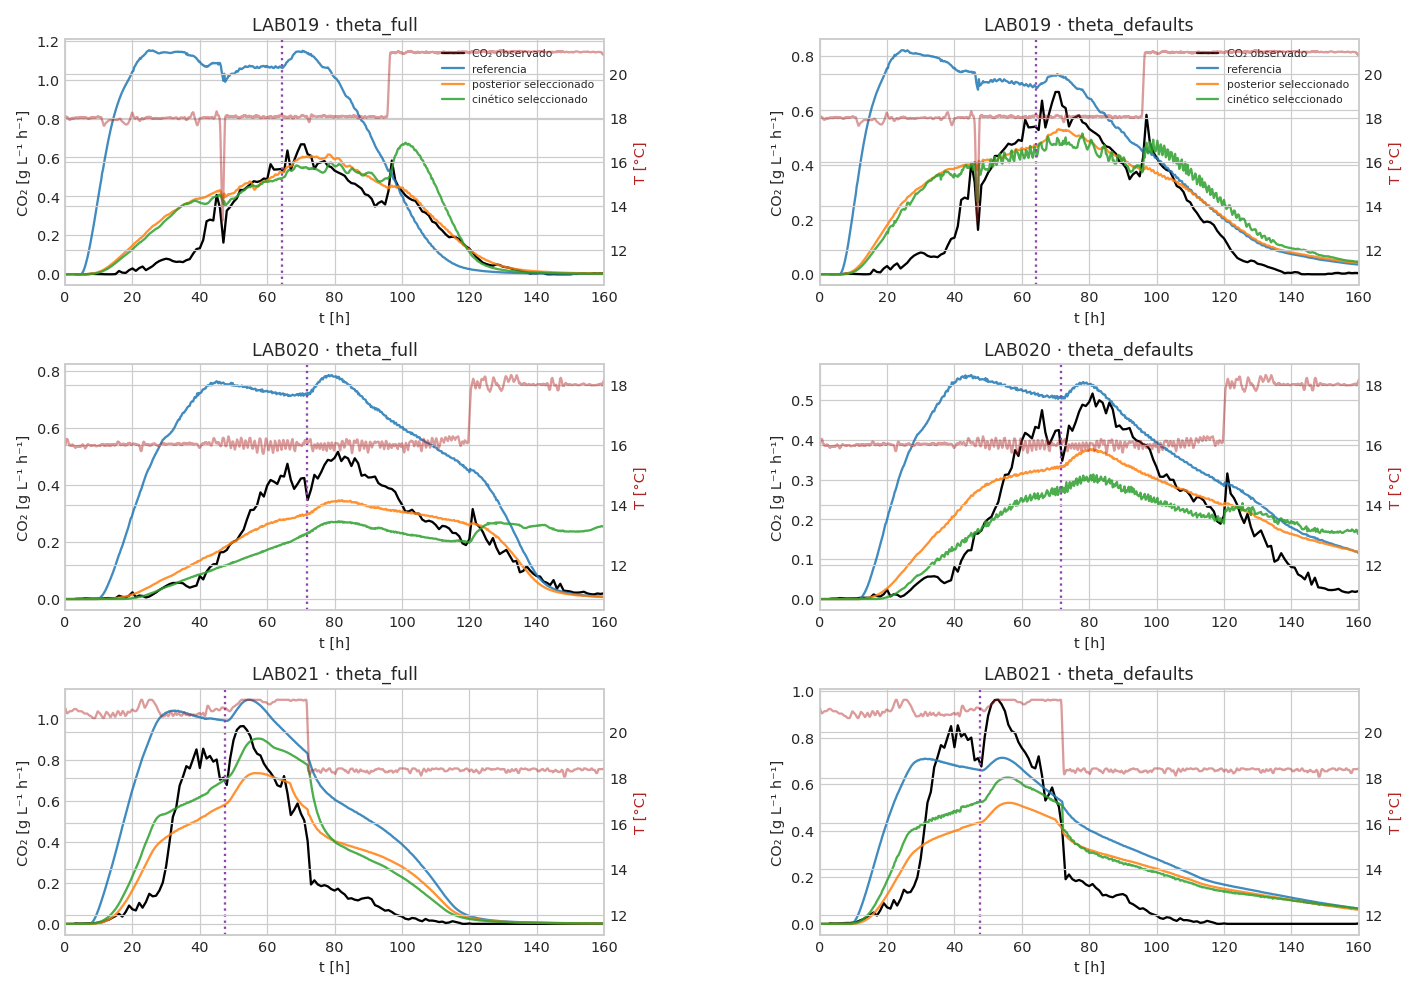

In [22]:
def window_candidates(theta,lab):
    return [('referencia',audit.predict(theta,lab,{})),
            ('posterior seleccionado',POST_CURVES[(theta,SELECTED_POST[theta],lab)]),
            ('cinético seleccionado',KIN_CURVES[(theta,SELECTED_KIN[theta],lab)])]
THERMAL_WINDOWS=thermal_windows(audit,temperature_raw,FERMENTER,T0,window_candidates)
display(THERMAL_WINDOWS.round(5))
fig,axes=plt.subplots(3,2,figsize=(14,9),squeeze=False)
for i,lab in enumerate(RECENT_TRAIN_LABS):
    temp=temp_log[FERMENTER[lab]];tt=(temp.index-T0).total_seconds()/3600.
    for j,theta in enumerate(THETA_SETS):
        ax=axes[i,j];obs=OBSERVATIONS[lab]
        ax.plot(obs.t_h,obs.co2_rate_g_l_h,color='black',label='CO₂ observado')
        for name,p in window_candidates(theta,lab):ax.plot(p.t_h,p.predicted,label=name,alpha=.85)
        for event,_ in ALL_BATCHES[lab].pulses['N']:ax.axvline(event,color='#8E44AD',ls=':')
        tx=ax.twinx();tx.plot(tt,temp.T_filt,color='#B22222',alpha=.45,label='T medida (suavizada sólo para figura)')
        tx.set_ylabel('T [°C]',color='#B22222')
        ax.set(title=f'{lab} · {theta}',xlabel='t [h]',ylabel='CO₂ [g L⁻¹ h⁻¹]',xlim=(0,audit.grids[lab][-1]))
        if i==0:ax.legend(fontsize=7)
fig.tight_layout();fig.subplots_adjust(left=.08,right=.92,wspace=.4);display_inline_figure(fig)

## Explorador manual posterior

Después de Run All, cambia los parámetros de esta celda y ejecuta la figura siguiente. No cambia los ajustes ni el ranking. Se comparan ambos theta con la misma prueba manual.

In [23]:
MANUAL = dict(labs=('LAB019','LAB020','LAB021'),B_clock_extra_K=4000.,tau_adapt_ref_h=18.,B_release_K=2500.,
              clock=True,adaptation=True,release_T=True)

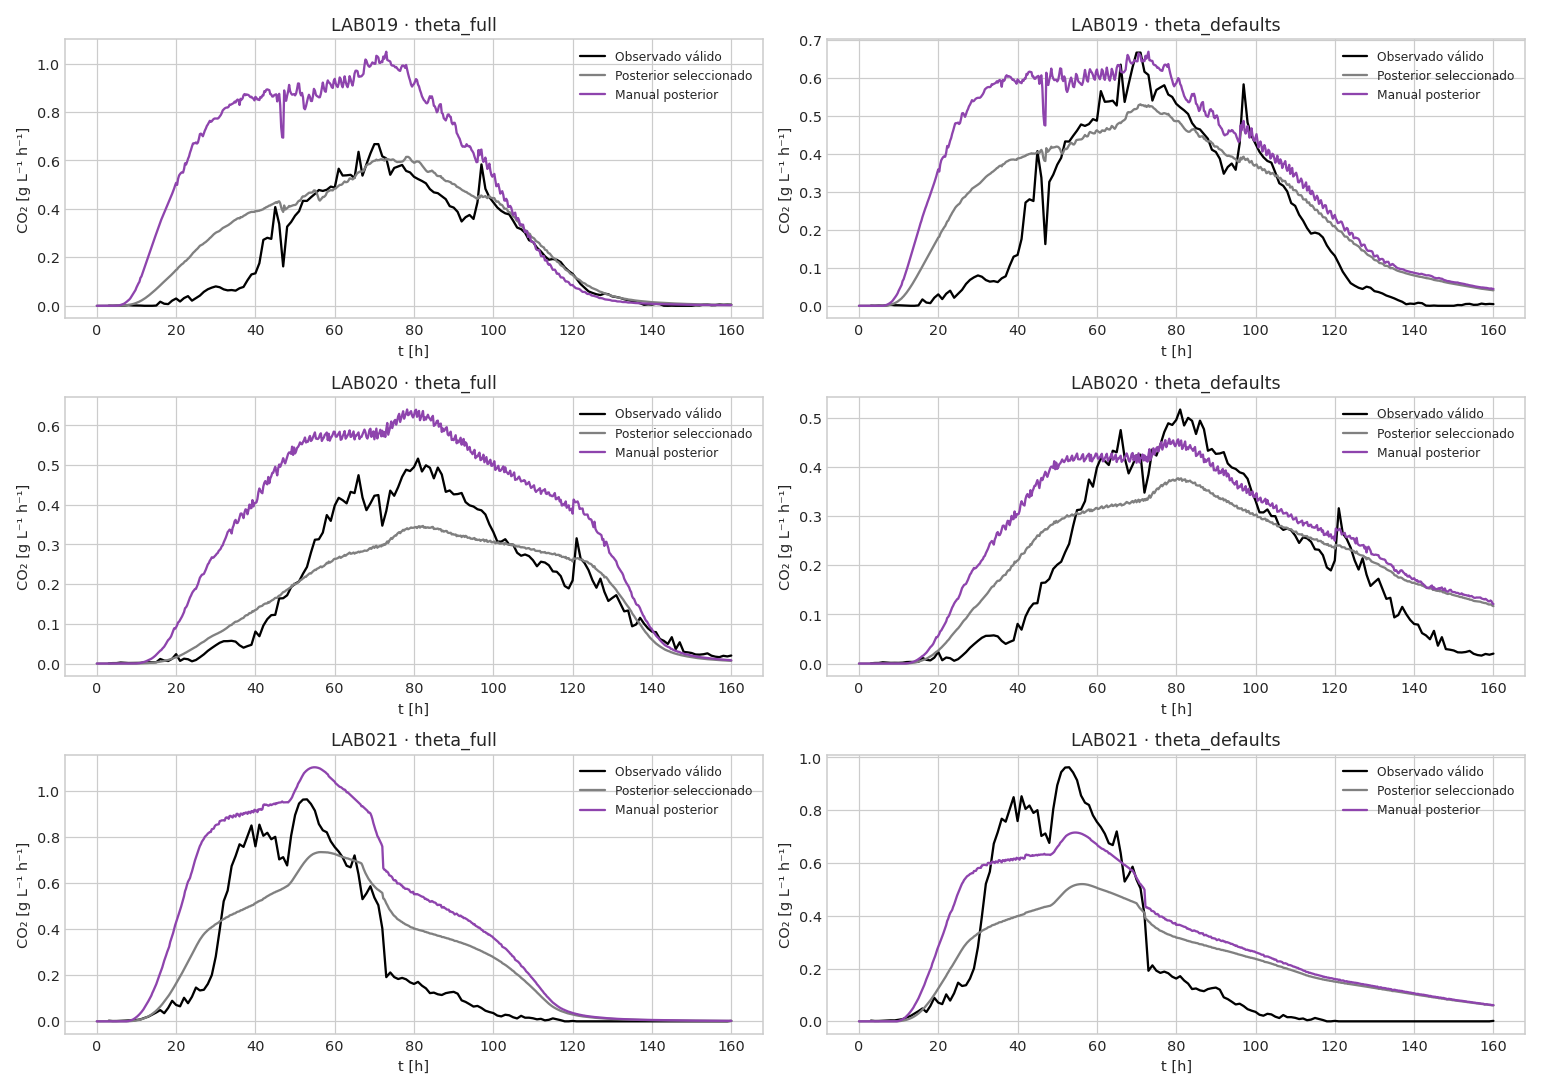

In [24]:
FORMAL_SIGNATURE=(POST_RANKING.to_json(),KIN_RANKING.to_json(),repr(POST_FITS),repr(KIN_FITS))
manual_params={key:MANUAL[key] for key,flag in (('B_clock_extra_K','clock'),('tau_adapt_ref_h','adaptation'),('B_release_K','release_T')) if MANUAL[flag]}
fig,axes=plt.subplots(len(MANUAL['labs']),2,figsize=(14,3.3*len(MANUAL['labs'])),squeeze=False)
for i,lab in enumerate(MANUAL['labs']):
    for j,theta in enumerate(THETA_SETS):
        ax=axes[i,j];obs=OBSERVATIONS[lab]
        formal=POST_CURVES[(theta,SELECTED_POST[theta],lab)];manual=audit.predict(theta,lab,manual_params)
        ax.plot(obs.t_h,obs.co2_rate_g_l_h,color='black',label='Observado válido')
        ax.plot(formal.t_h,formal.predicted,color='0.5',label='Posterior seleccionado')
        ax.plot(manual.t_h,manual.predicted,color='#8E44AD',label='Manual posterior')
        ax.set(title=f'{lab} · {theta}',xlabel='t [h]',ylabel='CO₂ [g L⁻¹ h⁻¹]');ax.legend(fontsize=8)
fig.tight_layout();display_inline_figure(fig)
assert FORMAL_SIGNATURE==(POST_RANKING.to_json(),KIN_RANKING.to_json(),repr(POST_FITS),repr(KIN_FITS))

## Explorador manual del reloj cinético

Recalcula el lote seleccionado para **cada theta**. Los factores opcionales no cambian el ajuste formal. La figura separa flujo, producción/liberación, química y factores térmicos.

In [25]:
KINETIC_MANUAL=dict(lab='LAB021',B_kin_extra_K=8000.,tau_adapt_ref_h=18.,B_release_K=4000.,adaptation=True,release_T=True)

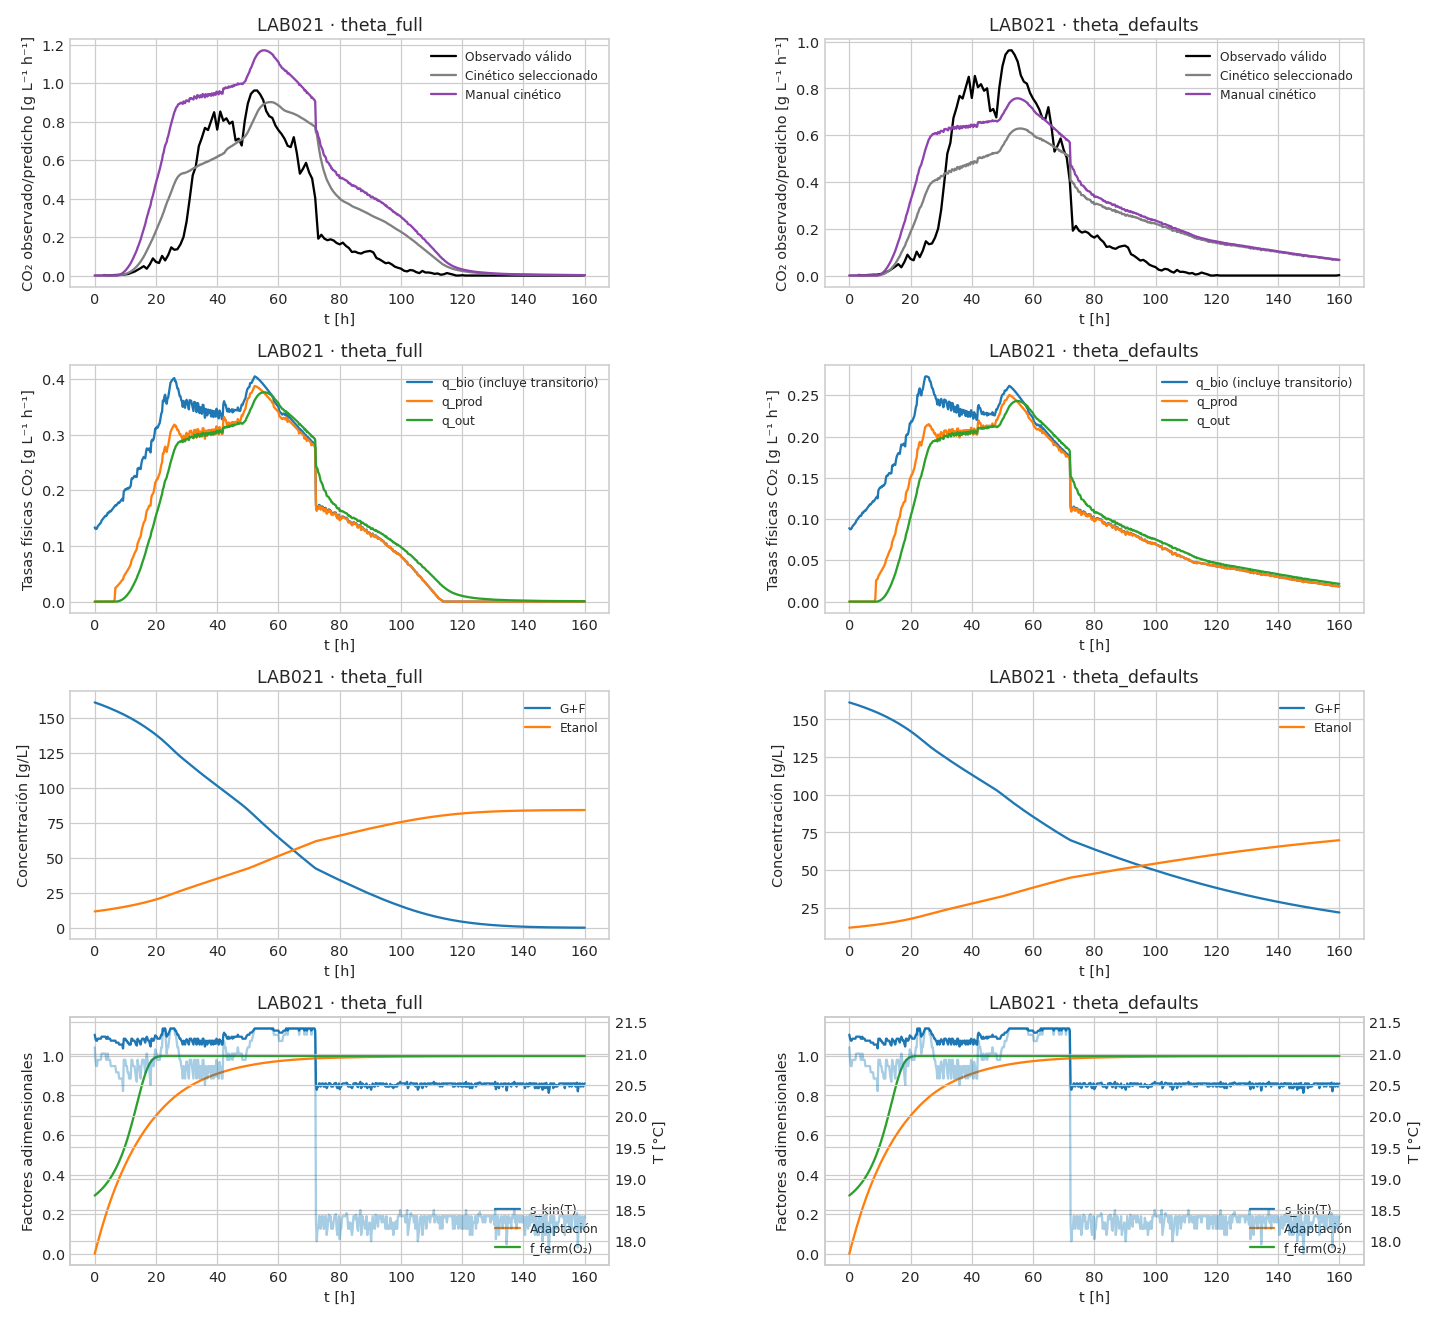

In [26]:
FORMAL_SIGNATURE=(POST_RANKING.to_json(),KIN_RANKING.to_json(),repr(POST_FITS),repr(KIN_FITS))
lab=KINETIC_MANUAL['lab'];manual_B=float(KINETIC_MANUAL['B_kin_extra_K'])
params={key:KINETIC_MANUAL[key] for key,flag in (('tau_adapt_ref_h','adaptation'),('B_release_K','release_T')) if KINETIC_MANUAL[flag]}
fig,axes=plt.subplots(4,2,figsize=(14,12),squeeze=False)
for j,theta in enumerate(THETA_SETS):
    profile=audit.profile(theta,lab,manual_B);manual=audit.predict(theta,lab,params,'kinetic',manual_B)
    formal=KIN_CURVES[(theta,SELECTED_KIN[theta],lab)];obs=OBSERVATIONS[lab]
    axes[0,j].plot(obs.t_h,obs.co2_rate_g_l_h,color='black',label='Observado válido')
    axes[0,j].plot(formal.t_h,formal.predicted,color='0.5',label='Cinético seleccionado')
    axes[0,j].plot(manual.t_h,manual.predicted,color='#8E44AD',label='Manual cinético')
    for field,label in (('qbio','q_bio (incluye transitorio)'),('qprod','q_prod'),('qout','q_out')):
        axes[1,j].plot(manual.t_h,manual[field],label=label)
    axes[2,j].plot(profile['t'],profile['core'].G+profile['core'].F,label='G+F')
    axes[2,j].plot(profile['t'],profile['core'].E,label='Etanol')
    axes[3,j].plot(manual.t_h,manual.thermal_speed,label='s_kin(T)')
    axes[3,j].plot(manual.t_h,manual.adaptation,label='Adaptación')
    axes[3,j].plot(manual.t_h,manual.f_ferm,label='f_ferm(O₂)')
    tx=axes[3,j].twinx();tx.plot(profile['t'],profile['temperature'],color='#0072B2',alpha=.35);tx.set_ylabel('T [°C]')
    for i,ylabel in enumerate(('CO₂ observado/predicho [g L⁻¹ h⁻¹]','Tasas físicas CO₂ [g L⁻¹ h⁻¹]','Concentración [g/L]','Factores adimensionales')):
        axes[i,j].set(title=f'{lab} · {theta}',xlabel='t [h]',ylabel=ylabel);axes[i,j].legend(fontsize=8)
fig.tight_layout();fig.subplots_adjust(left=.08,right=.92,wspace=.4);display_inline_figure(fig)
assert FORMAL_SIGNATURE==(POST_RANKING.to_json(),KIN_RANKING.to_json(),repr(POST_FITS),repr(KIN_FITS))

## Verificación final y conclusiones de esta ejecución

Las conclusiones siguientes se construyen con los nuevos resultados; no se conservan conclusiones, parámetros térmicos ni rankings del notebook anterior. Las métricas AUC se calculan sobre soporte contiguo válido (sin conectar huecos mayores de 1.5 h). El onset requiere tres puntos consecutivos por encima de un umbral observado: es una métrica de evaluación, no una entrada al modelo.

In [27]:
assert protected_before=={str(path):sha256(path) for path in PROTECTED_PATHS}
assert FROZEN_THETA==json.dumps(THETA_SETS,sort_keys=True)
assert FROZEN_CO2==json.dumps(CO2_PARAMS,sort_keys=True)
for prediction in [*POST_CURVES.values(),*KIN_CURVES.values()]:
    assert np.isfinite(prediction.select_dtypes(include='number').to_numpy(dtype=float)).all()
    assert (prediction.predicted>=0).all() and (prediction.dissolved_g_l>=0).all()
    assert prediction.attrs['mass_error']<1e-10
    assert np.all(np.diff(prediction.thermal_clock_h)>=0)
    assert np.allclose(prediction.predicted,CO2_PARAMS['matrix_gain']*prediction.qout)
    assert np.allclose(prediction.qprod,prediction.chemical_activation*prediction.adaptation*prediction.f_ferm*prediction.qbio)
assert set(audit.fit_blocks)==set(TRAIN_LABS)
SUMMARY_ROWS=[]
for theta in THETA_SETS:
    for family,selected,metrics in (('posterior',SELECTED_POST[theta],POST_METRICS),('cinético',SELECTED_KIN[theta],KIN_METRICS)):
        reference_metrics=POST_METRICS[POST_METRICS.theta.eq(theta)&POST_METRICS.model.eq('actual')]
        selected_metrics=metrics[metrics.theta.eq(theta)&metrics.model.eq(selected)]
        for role in ('train_recent','historical_validation','external_holdout'):
            ref=float(reference_metrics[reference_metrics.role.eq(role)].NRMSE_peak.median())
            current=float(selected_metrics[selected_metrics.role.eq(role)].NRMSE_peak.median())
            SUMMARY_ROWS.append(dict(theta=theta,family=family,selected=selected,role=role,
                NRMSE_reference=ref,NRMSE_selected=current,relative_improvement=1-current/ref))
    selection=KIN_FITS[(theta,SELECTED_KIN[theta])]
    B=selection['B']
    post=POST_FITS[(theta,SELECTED_POST[theta])]
    boundary=B in (min(KINETIC_CLOCK_CONFIG['B_grid_K']),max(KINETIC_CLOCK_CONFIG['B_grid_K']))
    display(Markdown(f'**{theta}:** posterior seleccionado `{SELECTED_POST[theta]}`, parámetros `{post["params"]}`. '
        f'Cinético seleccionado `{SELECTED_KIN[theta]}`, B={B:g} K y parámetros `{selection["params"]}`. '
        f'B está en un extremo de la grilla: **{boundary}**. '
        'Las mejoras se deben contrastar entre selección, evaluación externa y química; un mejor flujo no prueba un mecanismo único.'))
SUMMARY_TABLE=pd.DataFrame(SUMMARY_ROWS)
display(SUMMARY_TABLE.round(5))
nonconverged=POST_STARTS[~POST_STARTS.success]
print('Arranques térmicos sin convergencia:',len(nonconverged),'de',len(POST_STARTS))
print('Error máximo de balance pool:',max(p.attrs['mass_error'] for p in [*POST_CURVES.values(),*KIN_CURVES.values()]))
print('VERIFICACIÓN COMPLETA: capa antigua y ambos theta intactos; sin escritura en results; referencia simplificada reproducida.')

Arranques térmicos sin convergencia: 0 de 32
Error máximo de balance pool: 1.1102230246251565e-16
VERIFICACIÓN COMPLETA: capa antigua y ambos theta intactos; sin escritura en results; referencia simplificada reproducida.


**theta_full:** posterior seleccionado `reloj_adaptacion`, parámetros `{'B_clock_extra_K': 7117.794854585656, 'tau_adapt_ref_h': 59.99997433210768}`. Cinético seleccionado `cin_global_adapt__Bkin_12000`, B=12000 K y parámetros `{'tau_adapt_ref_h': 50.0}`. B está en un extremo de la grilla: **True**. Las mejoras se deben contrastar entre selección, evaluación externa y química; un mejor flujo no prueba un mecanismo único.

**theta_defaults:** posterior seleccionado `reloj_adaptacion`, parámetros `{'B_clock_extra_K': 3003.9019350931085, 'tau_adapt_ref_h': 44.282572984419936}`. Cinético seleccionado `cin_global_full__Bkin_8000`, B=8000 K y parámetros `{'tau_adapt_ref_h': 36.0, 'B_release_K': 5000.0}`. B está en un extremo de la grilla: **False**. Las mejoras se deben contrastar entre selección, evaluación externa y química; un mejor flujo no prueba un mecanismo único.

,theta,family,selected,role,NRMSE_reference,NRMSE_selected,relative_improvement
0,theta_full,posterior,reloj_adaptacion,train_recent,0.62780,0.14673,0.76628
1,theta_full,posterior,reloj_adaptacion,historical_validation,0.73388,0.19081,0.73999
2,theta_full,posterior,reloj_adaptacion,external_holdout,0.51238,0.15057,0.70614
3,theta_full,cinético,cin_global_adapt__Bkin_12000,train_recent,0.62780,0.17584,0.71991
4,theta_full,cinético,cin_global_adapt__Bkin_12000,historical_validation,0.73388,0.23143,0.68464
5,theta_full,cinético,cin_global_adapt__Bkin_12000,external_holdout,0.51238,0.16955,0.66910
6,theta_defaults,posterior,reloj_adaptacion,train_recent,0.37937,0.16961,0.55292
7,theta_defaults,posterior,reloj_adaptacion,historical_validation,0.47743,0.21058,0.55893
8,theta_defaults,posterior,reloj_adaptacion,external_holdout,0.25146,0.14361,0.42890
9,theta_defaults,cinético,cin_global_full__Bkin_8000,train_recent,0.37937,0.17550,0.53738
